# CSE 902 — Homework 1: VAE Latent Spaces on Fashion-MNIST

Notebook template. One cell per portion of each subproblem; the question is in the comments at the top of
each cell. Cells marked `TODO` are placeholders for you to complete.

In [20]:
# =============================================================================
# SETUP INSTRUCTIONS (from the CSE 902 Homework 1 handout)
# =============================================================================
#
# 1. DATASET & FRAMEWORK
#    - Dataset: Fashion-MNIST — 70,000 grayscale 28x28 images, 10 clothing classes.
#      60,000 training images / 10,000 test images.
#    - Load it with the Torchvision Fashion-MNIST loader (torchvision.datasets.FashionMNIST)
#      or the TensorFlow/Keras equivalent. This notebook uses PyTorch.
#
# 2. ENVIRONMENT
#    - Python 3.9+ with: torch, torchvision, numpy, matplotlib, scikit-learn, pandas
#        pip install torch torchvision numpy matplotlib scikit-learn pandas
#    - GPU (CUDA) or Apple-Silicon (MPS) is used automatically when available; CPU works too.
#
# 3. STUDENT-SPECIFIC SEED
#    - s = 1000 + (last three digits of your student ID).
#    - Use s for: parameter initialization, data-loader shuffling, latent sampling, and visualization.
#    - State the seed in your report. Set STUDENT_ID_LAST3 in the "Configuration" cell below.
#
# 4. DATA SPLITS
#    - Use the OFFICIAL training split for optimization.
#    - Use the OFFICIAL test split ONLY for evaluation.
#
# 5. DATA PREPROCESSING
#    - Convert each image to a tensor in [0, 1] (transforms.ToTensor()).
#    - Do NOT normalize to [-1, 1]: the decoder ends in a sigmoid and the reconstruction term is BCE.
#
# 6. PRESCRIBED VAE ARCHITECTURE (latent dimension d_z = 16)
#    Encoder: 1x28x28 --Conv 1->32, stride 2--> 32x14x14 --Conv 32->64, stride 2--> 64x7x7
#             4x4 kernels, padding 1. Flatten, then SEPARATE linear layers for mu in R^16 and log sigma^2 in R^16.
#    Decoder: Linear projection to 64x7x7
#             --ConvTranspose 64->32--> 32x14x14 --ConvTranspose 32->1--> 1x28x28
#             4x4 kernels, stride 2, padding 1.
#    Activations: ReLU for hidden layers, sigmoid at the image output.
#
# 7. TRAINING HYPERPARAMETERS
#    Batch size 128 | Optimizer Adam | Learning rate 1e-3 | Epochs 20
#    Reconstruction term: binary cross-entropy, summed over pixels
#    Latent dimension 16 | Prior p(z) = N(0, I)
#
# 8. CONFIGURATIONS TO TRAIN (Problem 2)
#    VAE-A: beta = 0, constant
#    VAE-B: beta = 1, constant
#    VAE-C: beta = 4, constant
#    VAE-D: beta = 4, linear warm-up from 0 to 4 during epochs 1-10
#
# 9. WHAT YOU MUST IMPLEMENT YOURSELF
#    Encoder heads for mu and log sigma^2; reparameterization; the beta-VAE objective; prior sampling;
#    linear interpolation; per-dimension KL diagnostics; active-unit counting; latent replacement and
#    shuffling tests; KL warm-up; and interpretation of all results.
#    You MAY reuse boilerplate for data download, device selection, checkpointing, image saving, and
#    general training-loop / plotting patterns.
#
# 10. REFERENCE IMPLEMENTATIONS (starting points, not solutions to copy unchanged)
#    - Fashion-MNIST dataset:   https://github.com/zalandoresearch/fashion-mnist
#    - Torchvision loader:      https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html
#    - PyTorch VAE example:     https://github.com/pytorch/examples/tree/main/vae
#    - Keras VAE example:       https://keras.io/examples/generative/vae/
#
# 11. CONTROLLED COMPARISONS
#    - For every controlled comparison, state your PREDICTION before presenting the result,
#      then compare the observation with the prediction.
#
# 12. SUBMISSION REQUIREMENTS
#    1. PDF report, at most 10 pages (excluding references and AI-use appendix).
#    2. Runnable source code + README with exact reproduction commands.
#    3. Configuration files, checkpoints, fixed prior codes, and raw metric files.
#    4. One unsuccessful or unexpected result with a technically grounded diagnosis.
#    5. AI-use appendix: tool, prompts used, outputs incorporated, and your modifications.
#    - Every figure must state the configuration, seed, and the conclusion it supports.
#
# 13. AI-USE / ACADEMIC INTEGRITY
#    - Generative AI is allowed for debugging, code suggestions, and conceptual clarification, but must be
#      disclosed in the appendix. You must be able to reproduce, modify, and explain every line
#      (a live/oral verification may be conducted).
# =============================================================================

## 0. Setup

In [21]:
# Install required packages if they are missing (installs into the kernel's own Python via sys.executable).
# Pattern from the pip docs on using pip from your program: https://pip.pypa.io/en/stable/user_guide/#using-pip-from-your-program
# After anything is installed, restart the kernel before running the next cells.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {  # import name -> pip package name
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
}

missing = [pkg for mod, pkg in REQUIREMENTS.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", " ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    print("Done. Restart the kernel, then continue from the next cell.")
else:
    print("All requirements already installed.")

All requirements already installed.


In [22]:
# Imports and device selection.
# Device-selection pattern adapted from the PyTorch VAE example:
#   https://github.com/pytorch/examples/blob/main/vae/main.py
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE)

Device: cuda


In [23]:
# Configuration: seed, hyperparameters, and the four VAE configurations (Problem 2 table).
STUDENT_ID_LAST3 = 522  # TODO: last three digits of your student ID
SEED = 1000 + STUDENT_ID_LAST3

BATCH_SIZE = 128
LR = 1e-3
EPOCHS = 20
LATENT_DIM = 16
WARMUP_EPOCHS = 10
ACTIVE_THRESHOLD = 0.01  # Problem 3A: dimension j is active when KL_j > 0.01

CONFIGS = {
    "VAE-A": {"beta": 0.0, "schedule": "constant"},
    "VAE-B": {"beta": 1.0, "schedule": "constant"},
    "VAE-C": {"beta": 4.0, "schedule": "constant"},
    "VAE-D": {"beta": 4.0, "schedule": "warmup"},
}

FASHION_CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                   "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

OUT_DIR = "outputs"
for sub in ["checkpoints", "metrics", "figures", "configs"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

with open(os.path.join(OUT_DIR, "configs", "configs.json"), "w") as f:
    json.dump({"seed": SEED, "batch_size": BATCH_SIZE, "lr": LR, "epochs": EPOCHS,
               "latent_dim": LATENT_DIM, "warmup_epochs": WARMUP_EPOCHS, "models": CONFIGS}, f, indent=2)
print("Seed:", SEED)

Seed: 1522


In [24]:
# Seeding helper (covers Python, NumPy, and PyTorch RNGs).
# Pattern from the PyTorch reproducibility notes: https://pytorch.org/docs/stable/notes/randomness.html
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

In [25]:
# Data: Fashion-MNIST as tensors in [0, 1] (ToTensor only, no normalization).
# Loader usage from the torchvision docs:
#   https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html
# Seeded DataLoader shuffling via a torch.Generator, per https://pytorch.org/docs/stable/notes/randomness.html
transform = transforms.ToTensor()
train_set = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=transform)


def make_loaders(seed):
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=g)
    test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)
    return train_loader, test_loader


x0, _ = train_set[0]
print(len(train_set), len(test_set), x0.shape, x0.min().item(), x0.max().item())

60000 10000 torch.Size([1, 28, 28]) 0.0 1.0


## Convolutional VAE

In [26]:
# Convolutional VAE following the prescribed architecture in the handout.
# Structure (encode / reparameterize / decode / forward) follows the PyTorch VAE example:
#   https://github.com/pytorch/examples/blob/main/vae/main.py
# Reparameterization trick: Kingma & Welling (2014), "Auto-Encoding Variational Bayes", https://arxiv.org/abs/1312.6114
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim
        # Encoder: 1x28x28 -> 32x14x14 -> 64x7x7
        self.enc_conv1 = nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1)
        self.enc_conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1)
        # Separate linear heads for mu and log sigma^2
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        # Decoder: linear -> 64x7x7 -> 32x14x14 -> 1x28x28
        self.dec_fc = nn.Linear(latent_dim, 64 * 7 * 7)
        self.dec_deconv1 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1)
        self.dec_deconv2 = nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1)

    def encode(self, x):
        h = F.relu(self.enc_conv1(x))
        h = F.relu(self.enc_conv2(h))
        h = h.flatten(start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        # eps ~ N(0, I), sigma = exp(0.5 * log sigma^2), z = mu + sigma * eps
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        h = F.relu(self.dec_fc(z)).view(-1, 64, 7, 7)
        h = F.relu(self.dec_deconv1(h))
        return torch.sigmoid(self.dec_deconv2(h))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

    @torch.no_grad()
    def sample_prior(self, n=None, z=None):
        # Prior sampling: decode z ~ N(0, I). Pass fixed codes `z` to compare models on identical prior draws.
        if z is None:
            z = torch.randn(n, self.latent_dim, device=next(self.parameters()).device)
        return self.decode(z)


print(ConvVAE())

ConvVAE(
  (enc_conv1): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (enc_conv2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (fc_mu): Linear(in_features=3136, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=16, bias=True)
  (dec_fc): Linear(in_features=16, out_features=3136, bias=True)
  (dec_deconv1): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (dec_deconv2): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
)


In [27]:
# beta-VAE objective and KL schedule.
# BCE summed over pixels and closed-form Gaussian KL as in the PyTorch VAE example
# (https://github.com/pytorch/examples/blob/main/vae/main.py) and Kingma & Welling (2014), Appendix B.
# beta weighting: Higgins et al. (2017), "beta-VAE", https://openreview.net/forum?id=Sy2fzU9gl
# Linear KL warm-up: Bowman et al. (2016), https://arxiv.org/abs/1511.06349
# NOTE: losses here are averaged over the batch (per-example), whereas the PyTorch example sums over the batch.
def kl_per_dim(mu, logvar):
    # Closed-form KL(N(mu, sigma^2) || N(0, 1)) for each latent dimension, shape [B, d_z].
    return 0.5 * (mu.pow(2) + logvar.exp() - logvar - 1)


def vae_loss(x_hat, x, mu, logvar, beta):
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kl = kl_per_dim(mu, logvar).sum(dim=1).mean()
    return recon + beta * kl, recon, kl


def beta_at(cfg, step, steps_per_epoch):
    # Constant beta, or linear warm-up 0 -> beta over WARMUP_EPOCHS (updated every optimizer step).
    # TODO (report): state this choice; a per-epoch schedule is an equally valid reading of the handout.
    if cfg["schedule"] == "constant":
        return cfg["beta"]
    progress = step / (WARMUP_EPOCHS * steps_per_epoch)
    return cfg["beta"] * min(1.0, progress)

In [28]:
# Train / evaluate one epoch. General training-loop pattern from the PyTorch VAE example:
#   https://github.com/pytorch/examples/blob/main/vae/main.py
def train_epoch(model, loader, optimizer, cfg, global_step):
    model.train()
    totals = {"recon": 0.0, "kl": 0.0, "total": 0.0}
    n = 0
    for x, _ in loader:
        x = x.to(DEVICE)
        beta = beta_at(cfg, global_step, len(loader))
        x_hat, mu, logvar = model(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        global_step += 1
        b = x.size(0)
        totals["recon"] += recon.item() * b
        totals["kl"] += kl.item() * b
        totals["total"] += loss.item() * b
        n += b
    return {k: v / n for k, v in totals.items()}, global_step, beta


@torch.no_grad()
def eval_epoch(model, loader, beta):
    model.eval()
    totals = {"recon": 0.0, "kl": 0.0, "total": 0.0}
    n = 0
    for x, _ in loader:
        x = x.to(DEVICE)
        x_hat, mu, logvar = model(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar, beta)
        b = x.size(0)
        totals["recon"] += recon.item() * b
        totals["kl"] += kl.item() * b
        totals["total"] += loss.item() * b
        n += b
    return {k: v / n for k, v in totals.items()}

## Problem 1: VAE Foundations and Implementation (20 pts)

### 1A. ELBO and loss function (8 pts)

In [29]:
# Problem 1A (i): Starting with log p_theta(x), explain why direct marginal-likelihood optimization is
# difficult and state the evidence lower bound (ELBO).
# -> Written answer in the markdown cell below.

**1A (i) — your answer:**

_TODO: write your answer here._

In [30]:
# Problem 1A (ii): Show how minimizing the negative ELBO leads to
#   L_beta(x) = -E_{q_phi(z|x)}[log p_theta(x|z)] + beta * D_KL(q_phi(z|x) || p(z)).
# -> Written derivation in the markdown cell below.

**1A (ii) — your answer:**

_TODO: write your answer here._

In [31]:
# Problem 1A (iii): For the diagonal Gaussian posterior, write the closed-form KL term used in your implementation.
# Sanity check: compare kl_per_dim (above) against torch.distributions' analytic KL.
#   torch.distributions.kl docs: https://pytorch.org/docs/stable/distributions.html#module-torch.distributions.kl
# Reference:
# https://docs.pytorch.org/docs/stable/distributions.html
#
# For q(z|x) = N(mu, diag(sigma^2)) and p(z) = N(0, I):
#
# KL(q || p) = 0.5 * sum_j [mu_j^2 + exp(logvar_j) - 1 - logvar_j]
#
# kl_per_dim returns each latent dimension's contribution separately.
import torch
from torch.distributions import Normal, kl_divergence

def check_closed_form_kl(batch=8):
    # TODO: draw random mu/logvar of shape [batch, LATENT_DIM], compute kl_per_dim(mu, logvar) and
    #       kl_divergence(Normal(mu, std), Normal(0, 1)), and assert they match (torch.allclose).
    torch.manual_seed(1522)
    mu = torch.randn(batch, LATENT_DIM, dtype=torch.float64)
    logvar = torch.randn(batch, LATENT_DIM, dtype=torch.float64)

    # manual closed form kl
    manual_kl = 0.5 * (mu.pow(2) + logvar.exp() - logvar - 1)
    std = torch.exp(0.5 * logvar)

    kl_torch = kl_divergence(Normal(mu, std),  Normal(torch.zeros_like(mu), torch.ones_like(std)))
    assert torch.allclose(manual_kl, kl_torch, rtol=1e-5, atol=1e-7), "Per-dimension KL values do not match!"

    # Also verify the summed KL for each example.
    manual_kl_sum = manual_kl.sum(dim=1)
    kl_torch_sum = kl_torch.sum(dim=1)

    assert torch.allclose(manual_kl_sum, kl_torch_sum, rtol=1e-5, atol=1e-7), "Summed KL values do not match!"

    print("Sanity check passed!")
    print("Manual KL shape:", tuple(manual_kl.shape))
    print("PyTorch KL shape:", tuple(kl_torch.shape))
    print("Maximum absolute difference:",(manual_kl - kl_torch).abs().max().item())
    print("Mean KL per example:",manual_kl.mean().item())

    #raise NotImplementedError


check_closed_form_kl()

Sanity check passed!
Manual KL shape: (8, 16)
PyTorch KL shape: (8, 16)
Maximum absolute difference: 4.440892098500626e-16
Mean KL per example: 0.7046512370056053


**1A (iii) — closed-form KL — your answer:**

_TODO: write your answer here._

In [32]:
# Problem 1A (iv): Explain the distinct roles of reconstruction and KL.
# -> Written answer in the markdown cell below.

**1A (iv) — your answer:**

_TODO: write your answer here._

### 1B. Reparameterization and implementation check (6 pts)

In [33]:
# Problem 1B (i): Implement eps ~ N(0, I), z = mu + sigma * eps, sigma = exp(0.5 * log sigma^2).
# (Implemented in ConvVAE.reparameterize above.) Quick check that gradients reach mu and logvar:
def check_reparameterization():
    # TODO: create mu, logvar with requires_grad=True, call ConvVAE().reparameterize, backprop z.sum(),
    #       and confirm mu.grad / logvar.grad are not None. Also check empirical mean/std of z.
    torch.manual_seed(1522)
    batch_size = 128
    mu = torch.randn(1, LATENT_DIM, requires_grad=True)
    logvar = torch.randn(1, LATENT_DIM, requires_grad=True)

    vae = ConvVAE()
    z = vae.reparameterize(mu, logvar)

    z.sum().backward()
    assert mu.grad is not None, "mu.grad is None, gradient did not reach mu"
    assert logvar.grad is not None, "logvar.grad is None, gradient did not reach logvar"

    print("gradient checks")

    print("mu grad exists: ", mu.grad is not None)
    print("logvar grad exists: ", logvar.grad is not None)


    print("mu.grad:", mu.grad.mean().item(), mu.grad.std().item())
    print("logvar.grad:", logvar.grad.mean().item(), logvar.grad.std().item())
    print("z mean:", z.mean().item(), "z std:", z.std().item())


    # Check empirical mean and standard deviation for a known distribution.
    # Set mu=0 and logvar=0, giving sigma=1 and z ~ N(0, I).
    with torch.no_grad():
        test_mu = torch.zeros(batch_size, LATENT_DIM)
        test_logvar = torch.zeros(batch_size, LATENT_DIM)

        samples = vae.reparameterize(test_mu, test_logvar)

        empirical_mean = samples.mean().item()
        empirical_std = samples.std().item()

    print(f"Empirical mean (expected ~0): {empirical_mean:.4f}")
    print(f"Empirical std (expected ~1):  {empirical_std:.4f}")

    assert abs(empirical_mean) < 0.05, "Sample mean is unexpectedly far from zero."
    assert abs(empirical_std - 1.0) < 0.05, "Sample std is unexpectedly far from one."

    print("Empirical distribution checks passed!")


    #raise NotImplementedError


check_reparameterization()

gradient checks
mu grad exists:  True
logvar grad exists:  True
mu.grad: 1.0 0.0
logvar.grad: -0.04322713613510132 0.6007455587387085
z mean: -0.20912688970565796 z std: 1.402847170829773
Empirical mean (expected ~0): 0.0272
Empirical std (expected ~1):  1.0088
Empirical distribution checks passed!


In [34]:
# Problem 1B (ii): Explain why sampling z directly from q_phi(z|x) obstructs ordinary backpropagation
# and how reparameterization resolves the issue.
# -> Written answer in the markdown cell below.

**1B (ii) — your answer:**

_TODO: write your answer here._

In [35]:
# Problem 1B (iii): Verify tensor shapes at every encoder and decoder stage.
# Forward hooks: https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook
def shape_table(model):
    # TODO: register forward hooks on each submodule (or step through encode/decode manually) with a
    #       dummy input torch.zeros(1, 1, 28, 28); return a DataFrame with columns [stage, output shape].

  import torch
  import pandas as pd


  def shape_table(model):
      rows = []
      hooks = []

      def get_shape(module, inputs, output):
          if isinstance(output, torch.Tensor):
              rows.append({
                  "stage": module.__class__.__name__,
                  "output shape": tuple(output.shape)
              })

      # Register hooks on the layers whose output shapes we want to inspect.
      layers = [
          ("enc_conv1", model.enc_conv1),
          ("enc_conv2", model.enc_conv2),
          ("fc_mu", model.fc_mu),
          ("fc_logvar", model.fc_logvar),
          ("dec_fc", model.dec_fc),
          ("dec_deconv1", model.dec_deconv1),
          ("dec_deconv2", model.dec_deconv2),
      ]

      for name, layer in layers:
          hook = layer.register_forward_hook(
              lambda module, inputs, output, name=name:
                  rows.append({
                      "stage": name,
                      "output shape": tuple(output.shape)
                  })
          )
          hooks.append(hook)

      # Run encoder and decoder with a dummy input.
      # Use eval mode and restore the previous training state afterward.
      was_training = model.training
      model.eval()

      try:
          device = next(model.parameters()).device
          x = torch.zeros(1, 1, 28, 28, device=device)

          with torch.no_grad():
              mu, logvar = model.encode(x)
              z = model.reparameterize(mu, logvar)
              model.decode(z)

          # Add the input and latent sampling stages for completeness.
          rows.insert(0, {
              "stage": "input",
              "output shape": tuple(x.shape)
          })

          rows.append({
              "stage": "latent z",
              "output shape": tuple(z.shape)
          })

      finally:
          for hook in hooks:
              hook.remove()
          model.train(was_training)

      return pd.DataFrame(rows, columns=["stage", "output shape"])


  # Run the shape verification
  model = ConvVAE()
  shape_df = shape_table(model)
  print(shape_df.to_string(index=False))
      #raise NotImplementedError

shape_table(ConvVAE())

      stage    output shape
      input  (1, 1, 28, 28)
  enc_conv1 (1, 32, 14, 14)
  enc_conv2   (1, 64, 7, 7)
      fc_mu         (1, 16)
  fc_logvar         (1, 16)
     dec_fc       (1, 3136)
dec_deconv1 (1, 32, 14, 14)
dec_deconv2  (1, 1, 28, 28)
   latent z         (1, 16)


In [36]:
# Problem 1B (iv): Report the number of trainable parameters.
import pandas as pd

def count_trainable_params(model):
    # TODO: sum p.numel() over parameters with requires_grad; also return a per-layer breakdown table.
    # raise NotImplementedError

    rows = []
    total_params = 0

    for name, param in model.named_parameters():
        if param.requires_grad:
            num_params = param.numel()
            rows.append({
                "layer / parameter": name,
                "shape": tuple(param.shape),
                "trainable parameters": num_params
            })
            total_params += num_params

    breakdown = pd.DataFrame(
        rows,
        columns=["layer / parameter", "shape", "trainable parameters"]
    )

    # Add a total row
    total_row = pd.DataFrame([{
        "layer / parameter": "TOTAL",
        "shape": "-",
        "trainable parameters": total_params
    }])

    breakdown = pd.concat([breakdown, total_row], ignore_index=True)

    return total_params, breakdown


# Run the check
model = ConvVAE()
total, breakdown = count_trainable_params(model)

print(f"Total trainable parameters: {total:,}")
print(breakdown.to_string(index=False))
# count_trainable_params(ConvVAE())

Total trainable parameters: 220,385
 layer / parameter          shape  trainable parameters
  enc_conv1.weight  (32, 1, 4, 4)                   512
    enc_conv1.bias          (32,)                    32
  enc_conv2.weight (64, 32, 4, 4)                 32768
    enc_conv2.bias          (64,)                    64
      fc_mu.weight     (16, 3136)                 50176
        fc_mu.bias          (16,)                    16
  fc_logvar.weight     (16, 3136)                 50176
    fc_logvar.bias          (16,)                    16
     dec_fc.weight     (3136, 16)                 50176
       dec_fc.bias        (3136,)                  3136
dec_deconv1.weight (64, 32, 4, 4)                 32768
  dec_deconv1.bias          (32,)                    32
dec_deconv2.weight  (32, 1, 4, 4)                   512
  dec_deconv2.bias           (1,)                     1
             TOTAL              -                220385


### 1C. Reconstruction versus generation (6 pts)

In [37]:
# Problem 1C: Explain the difference between (i) reconstructing an observed image using a code from q_phi(z|x)
# and (ii) generating a new image using z ~ N(0, I). Why can a model reconstruct well while generating poor
# prior samples? Contrast the VAE with a deterministic autoencoder in this respect.
# -> Written answer in the markdown cell below (you may reference figures from Problem 2A, e.g. VAE-A).

**1C — your answer:**

_TODO: write your answer here._

## Problem 2: KL Weighting and Latent-Space Geometry (30 pts)

In [38]:
# Problem 2 — Train the prescribed architecture using all four configurations:
#   VAE-A: beta=0 constant | VAE-B: beta=1 constant | VAE-C: beta=4 constant | VAE-D: beta=4, warm-up epochs 1-10
# Each model is re-seeded with SEED so initialization and shuffling are identical across configurations.
# Saves per-epoch metrics (raw JSON), the best-test-reconstruction checkpoint, and the final checkpoint.
# Checkpointing pattern: https://pytorch.org/tutorials/beginner/saving_loading_models.html
TRAIN = True  # set False to reload saved checkpoints/metrics instead of retraining
# TRAIN = False

models, histories = {}, {}
for name, cfg in CONFIGS.items():
    tag = name.lower().replace("-", "_")
    ckpt_path = os.path.join(OUT_DIR, "checkpoints", f"{tag}_final.pt")
    metrics_path = os.path.join(OUT_DIR, "metrics", f"{tag}.json")

    set_seed(SEED)
    model = ConvVAE().to(DEVICE)

    if not TRAIN and os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        with open(metrics_path) as f:
            histories[name] = json.load(f)
        models[name] = model.eval()
        print(f"Loaded {name}")
        continue

    train_loader, test_loader = make_loaders(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history, step, best_recon = [], 0, float("inf")
    for epoch in range(1, EPOCHS + 1):
        tr, step, beta = train_epoch(model, train_loader, optimizer, cfg, step)
        te = eval_epoch(model, test_loader, beta)
        history.append({"epoch": epoch, "beta": beta,
                        **{f"train_{k}": v for k, v in tr.items()},
                        **{f"test_{k}": v for k, v in te.items()}})
        if te["recon"] < best_recon:
            best_recon = te["recon"]
            torch.save(model.state_dict(), os.path.join(OUT_DIR, "checkpoints", f"{tag}_best.pt"))
        print(f"{name} | epoch {epoch:2d} | beta {beta:.2f} | "
              f"train recon {tr['recon']:.2f} kl {tr['kl']:.2f} | test recon {te['recon']:.2f} kl {te['kl']:.2f}")

    torch.save(model.state_dict(), ckpt_path)
    with open(metrics_path, "w") as f:
        json.dump(history, f, indent=2)
    models[name] = model.eval()
    histories[name] = history

VAE-A | epoch  1 | beta 0.00 | train recon 258.62 kl 306.23 | test recon 228.53 kl 382.47
VAE-A | epoch  2 | beta 0.00 | train recon 223.16 kl 404.64 | test recon 222.33 kl 414.91
VAE-A | epoch  3 | beta 0.00 | train recon 219.30 kl 420.90 | test recon 220.04 kl 418.96
VAE-A | epoch  4 | beta 0.00 | train recon 217.43 kl 415.26 | test recon 218.70 kl 407.23
VAE-A | epoch  5 | beta 0.00 | train recon 216.21 kl 405.15 | test recon 217.42 kl 399.88
VAE-A | epoch  6 | beta 0.00 | train recon 215.37 kl 398.36 | test recon 216.92 kl 385.75
VAE-A | epoch  7 | beta 0.00 | train recon 214.71 kl 389.46 | test recon 216.32 kl 379.44
VAE-A | epoch  8 | beta 0.00 | train recon 214.22 kl 378.45 | test recon 215.84 kl 366.78
VAE-A | epoch  9 | beta 0.00 | train recon 213.77 kl 368.34 | test recon 215.51 kl 361.58
VAE-A | epoch 10 | beta 0.00 | train recon 213.43 kl 359.91 | test recon 215.21 kl 357.06
VAE-A | epoch 11 | beta 0.00 | train recon 213.10 kl 350.01 | test recon 215.02 kl 342.98
VAE-A | ep

In [39]:

import os
import torch

# Save trained model weights and training histories.
checkpoint_dir = os.path.join(OUT_DIR, "checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)

for name, model in models.items():
    checkpoint_path = os.path.join(
        checkpoint_dir, f"{name.lower().replace('-', '_')}.pt"
    )
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved {name}: {checkpoint_path}")

# Save histories too, so you can regenerate training curves and metrics.
torch.save(histories, os.path.join(checkpoint_dir, "histories.pt"))


Saved VAE-A: outputs/checkpoints/vae_a.pt
Saved VAE-B: outputs/checkpoints/vae_b.pt
Saved VAE-C: outputs/checkpoints/vae_c.pt
Saved VAE-D: outputs/checkpoints/vae_d.pt


### 2A. Training, reconstruction, and prior sampling (12 pts)

In [40]:
# Problem 2A — PREDICTION (state before looking at results): how do you expect reconstruction loss, KL,
# and sample quality to change across VAE-A..D?
# -> Write your prediction in the markdown cell below.

**2A prediction — your answer:**

_TODO: write your answer here._


In [41]:
print("histories type:", type(histories))
print("model/config keys:", histories.keys())

for name, history in histories.items():
    print(f"\n{name}: type = {type(history)}")
    print("Example contents:", history[:2] if isinstance(history, list) else history)
    break

histories type: <class 'dict'>
model/config keys: dict_keys(['VAE-A', 'VAE-B', 'VAE-C', 'VAE-D'])

VAE-A: type = <class 'list'>
Example contents: [{'epoch': 1, 'beta': 0.0, 'train_recon': 258.6174267578125, 'train_kl': 306.2285867046912, 'train_total': 258.6174267578125, 'test_recon': 228.52837177734375, 'test_kl': 382.47307465820313, 'test_total': 228.52837177734375}, {'epoch': 2, 'beta': 0.0, 'train_recon': 223.15942416992186, 'train_kl': 404.64262884114584, 'train_total': 223.15942416992186, 'test_recon': 222.32800087890624, 'test_kl': 414.9104615722656, 'test_total': 222.32800087890624}]


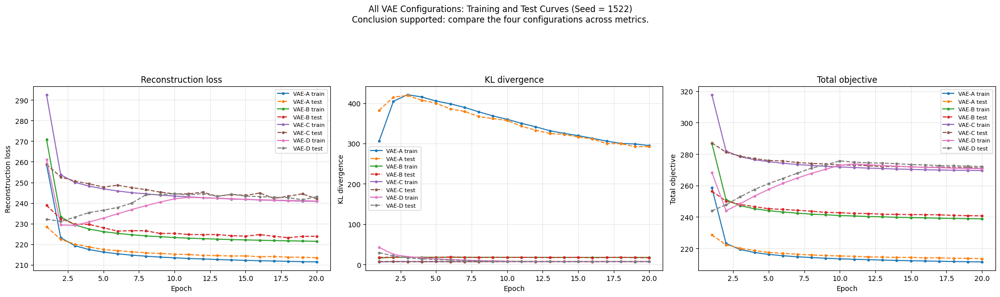

Saved combined figure: outputs/figures/p2a_curves.png


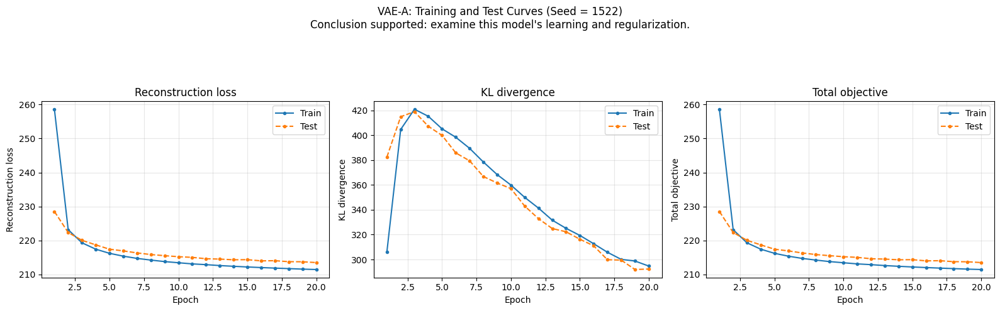

Saved VAE-A figure: outputs/figures/p2a_vae_a_curves.png


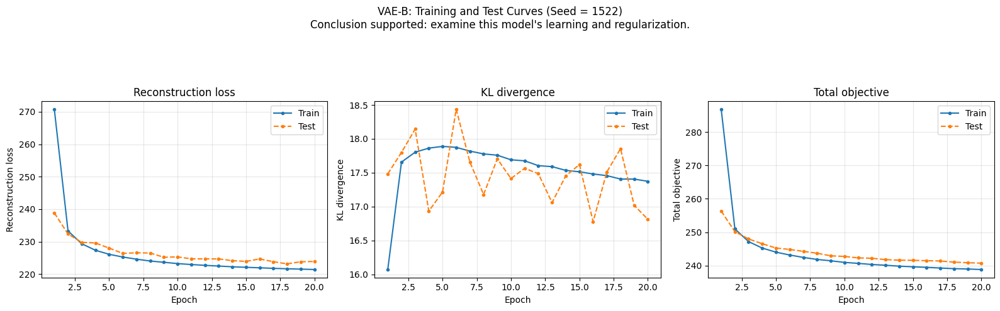

Saved VAE-B figure: outputs/figures/p2a_vae_b_curves.png


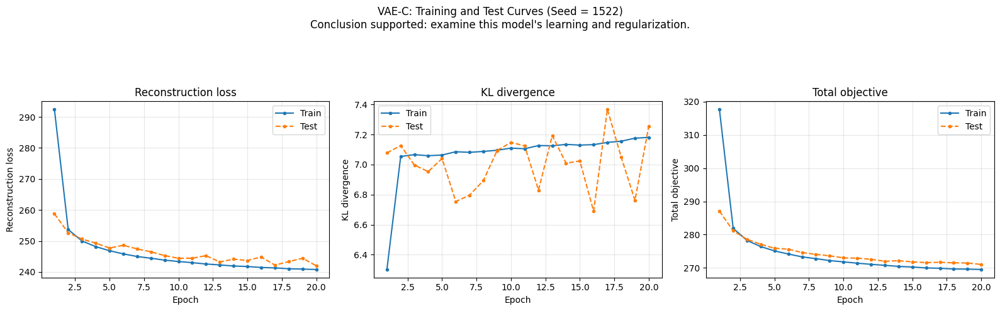

Saved VAE-C figure: outputs/figures/p2a_vae_c_curves.png


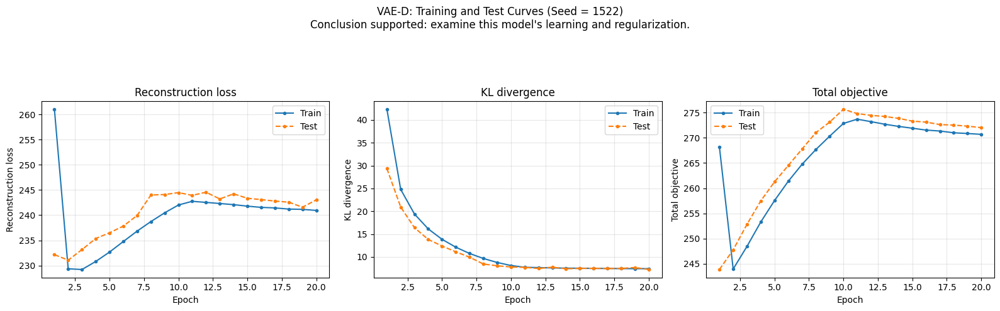

Saved VAE-D figure: outputs/figures/p2a_vae_d_curves.png


In [42]:
# Problem 2A (i): For every configuration, plot training and test reconstruction loss, KL divergence,
# and total objective by epoch.
# Every figure must state configuration, seed, and the conclusion it supports (put this in the title/caption).
import os
import matplotlib.pyplot as plt

def plot_curves(histories):
    figures_dir = os.path.join(OUT_DIR, "figures")
    os.makedirs(figures_dir, exist_ok=True)

    metrics = [
        ("recon", "Reconstruction loss"),
        ("kl", "KL divergence"),
        ("total", "Total objective"),
    ]

    # --------------------------------------------------
    # Figure 1: Combined comparison of all four models
    # --------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    for ax, (metric, ylabel) in zip(axes, metrics):
        for model_name, records in histories.items():
            epochs = [r["epoch"] for r in records]

            for split, linestyle in [("train", "-"), ("test", "--")]:
                values = [r[f"{split}_{metric}"] for r in records]
                ax.plot(
                    epochs, values,
                    linestyle=linestyle,
                    marker="o", markersize=3,
                    label=f"{model_name} {split}"
                )

        ax.set_title(ylabel)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(
        f"All VAE Configurations: Training and Test Curves (Seed = {SEED})\n"
        "Conclusion supported: compare the four configurations across metrics.",
        fontsize=12
    )
    fig.tight_layout(rect=[0, 0, 1, 0.86])

    combined_path = os.path.join(figures_dir, "p2a_curves.png")
    fig.savefig(combined_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved combined figure: {combined_path}")

    # --------------------------------------------------
    # Figures 2–5: One figure per model
    # --------------------------------------------------
    for model_name, records in histories.items():
        if not records:
            print(f"Skipping {model_name}: no recorded epochs.")
            continue

        epochs = [r["epoch"] for r in records]
        fig, axes = plt.subplots(1, 3, figsize=(16, 5))

        for ax, (metric, ylabel) in zip(axes, metrics):
            for split, linestyle in [("train", "-"), ("test", "--")]:
                values = [r[f"{split}_{metric}"] for r in records]
                ax.plot(
                    epochs, values,
                    linestyle=linestyle,
                    marker="o", markersize=3,
                    label=split.capitalize()
                )

            ax.set_title(ylabel)
            ax.set_xlabel("Epoch")
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)
            ax.legend()

        fig.suptitle(
            f"{model_name}: Training and Test Curves (Seed = {SEED})\n"
            "Conclusion supported: examine this model's learning and regularization.",
            fontsize=12
        )
        fig.tight_layout(rect=[0, 0, 1, 0.86])

        filename = f"p2a_{model_name.lower().replace('-', '_')}_curves.png"
        save_path = os.path.join(figures_dir, filename)
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print(f"Saved {model_name} figure: {save_path}")


# Generate all five figures from the existing histories
plot_curves(histories)



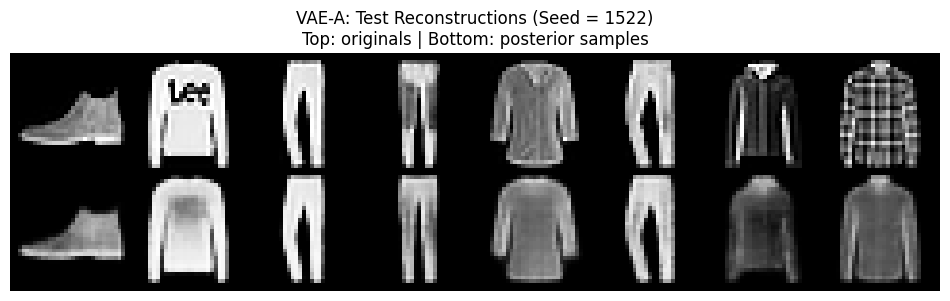

Saved: outputs/figures/p2a_vae-a_reconstructions.png


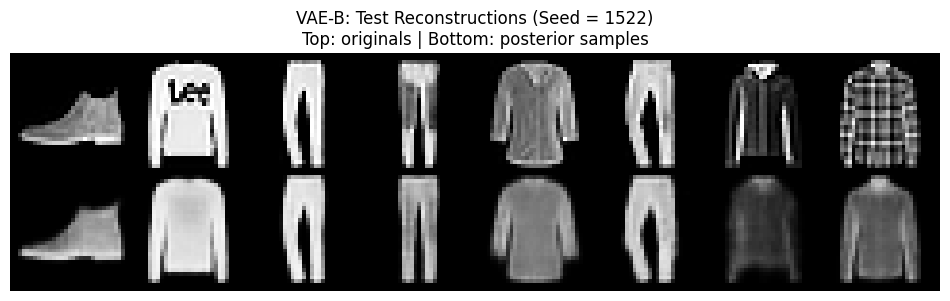

Saved: outputs/figures/p2a_vae-b_reconstructions.png


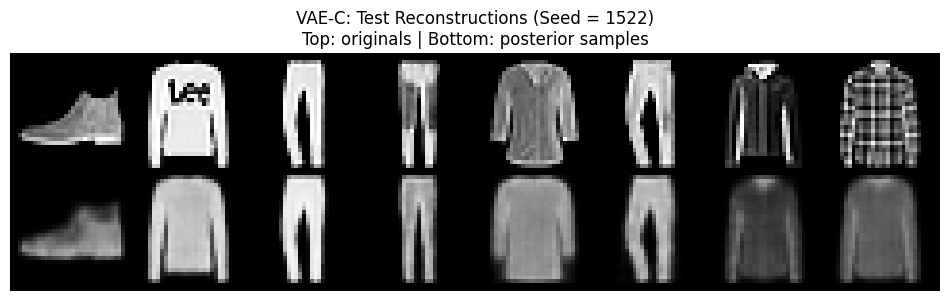

Saved: outputs/figures/p2a_vae-c_reconstructions.png


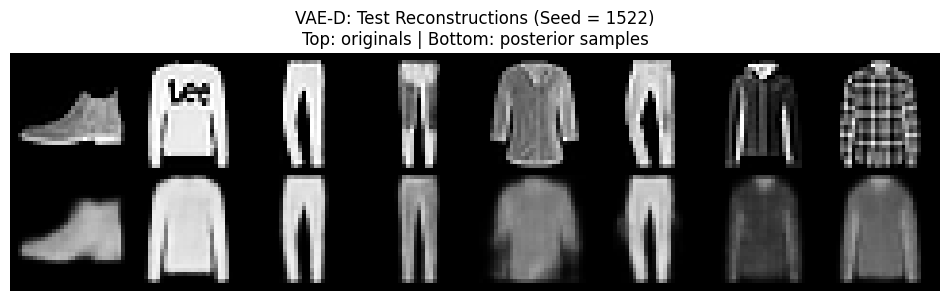

Saved: outputs/figures/p2a_vae-d_reconstructions.png


In [43]:
# Problem 2A (ii): Display test reconstructions as paired original/reconstruction grids.
# make_grid / save_image: https://pytorch.org/vision/stable/utils.html
# (The PyTorch VAE example concatenates originals and reconstructions the same way before save_image.)

import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid, save_image
import os

@torch.no_grad()
def reconstruction_grid(model, x, n=8):
    # TODO: use the posterior mean (or a sample — state which) to reconstruct x[:n];
    #       stack originals over reconstructions and return make_grid(..., nrow=n).
    #raise NotImplementedError
    model.eval()
    device = next(model.parameters()).device
    x = x[:n].to(device)

    # Sample from the approximate posterior q(z | x)
    mu, logvar = model.encode(x)
    z = model.reparameterize(mu, logvar)
    x_recon = model.decode(z)

    # First row: originals; second row: corresponding reconstructions
    images = torch.cat([x, x_recon], dim=0)
    return make_grid(images, nrow=n, padding=2, normalize=False)


# Use the same fixed test images for every model
from torch.utils.data import DataLoader

fixed_test_batch, fixed_test_labels = next(
    iter(DataLoader(test_set, batch_size=64, shuffle=False))
)

os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)

for name, model in models.items():
    grid = reconstruction_grid(model, fixed_test_batch, n=8)

    plt.figure(figsize=(12, 4))
    plt.imshow(grid.cpu().permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title(
        f"{name}: Test Reconstructions (Seed = {SEED})\n"
        "Top: originals | Bottom: posterior samples"
    )
    plt.axis("off")
    plt.show()

    path = os.path.join(
        OUT_DIR, "figures", f"p2a_{name.lower()}_reconstructions.png"
    )
    save_image(grid, path)
    print(f"Saved: {path}")


# fixed_test_batch, fixed_test_labels = next(iter(DataLoader(test_set, batch_size=64, shuffle=False)))
# for name, m in models.items(): ...

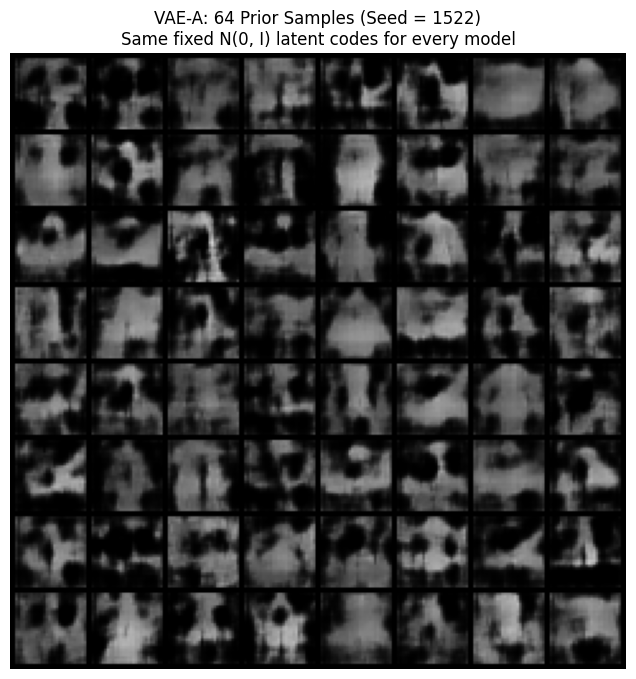

Saved: outputs/figures/p2a_vae-a_prior_samples.png


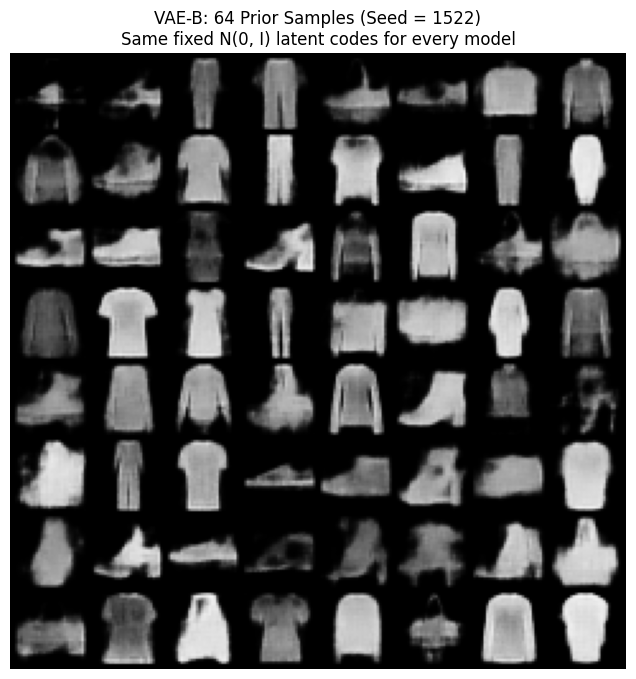

Saved: outputs/figures/p2a_vae-b_prior_samples.png


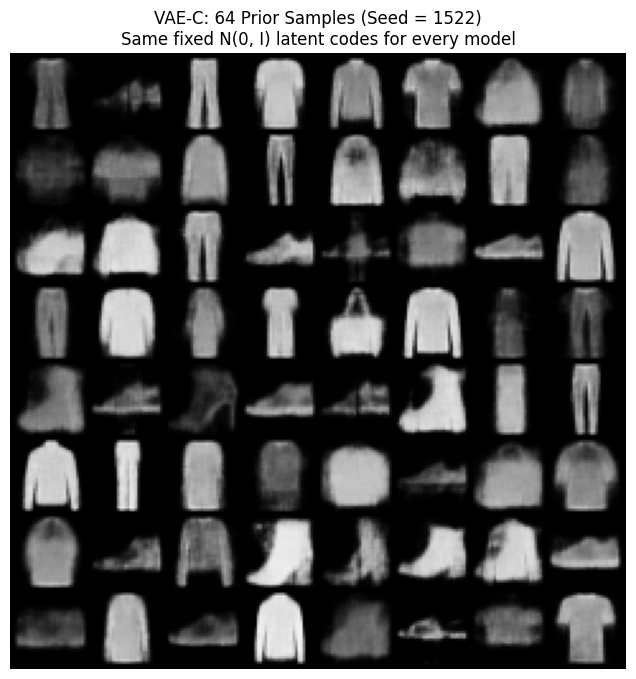

Saved: outputs/figures/p2a_vae-c_prior_samples.png


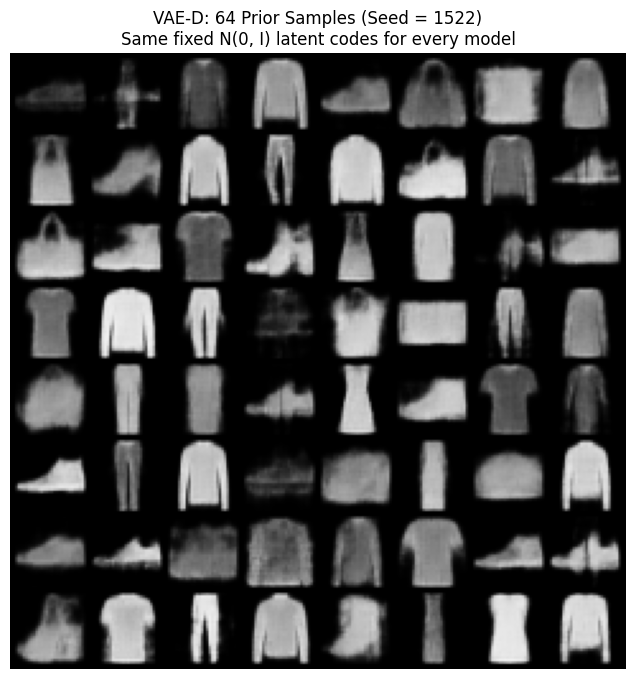

Saved: outputs/figures/p2a_vae-d_prior_samples.png
Saved fixed prior codes to: outputs/fixed_prior_codes.pt


In [44]:
# Problem 2A (iii): Generate 64 samples from the SAME fixed prior codes for all applicable comparisons.
# The fixed prior codes must be saved as a submission artifact.
g = torch.Generator().manual_seed(SEED)
FIXED_PRIOR_Z = torch.randn(64, LATENT_DIM, generator=g)
torch.save(FIXED_PRIOR_Z, os.path.join(OUT_DIR, "fixed_prior_codes.pt"))

# Save the latent codes
os.makedirs(OUT_DIR, exist_ok=True)
torch.save(FIXED_PRIOR_Z, os.path.join(OUT_DIR, "fixed_prior_codes.pt"))

def prior_sample_grid(model, z=FIXED_PRIOR_Z):
    # TODO: decode z with model.sample_prior(z=z.to(DEVICE)) and return make_grid(..., nrow=8).
    # raise NotImplementedError
    model.eval()

    # Use the prescribed sample_prior method
    with torch.no_grad():
        samples = model.sample_prior(z=z.to(DEVICE))

    # Keep the grid on CPU for plotting/saving
    return make_grid(
        samples.cpu(),
        nrow=8,
        padding=2,
        normalize=False
    )


# Generate and save samples for each trained model using identical latent codes
figures_dir = os.path.join(OUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

for name, m in models.items():
    grid = prior_sample_grid(m)

    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title(
        f"{name}: 64 Prior Samples (Seed = {SEED})\n"
        "Same fixed N(0, I) latent codes for every model"
    )
    plt.axis("off")
    plt.show()

    save_path = os.path.join(
        figures_dir, f"p2a_{name.lower()}_prior_samples.png"
    )
    save_image(grid, save_path)
    print(f"Saved: {save_path}")

print(
    "Saved fixed prior codes to:",
    os.path.join(OUT_DIR, "fixed_prior_codes.pt")
)

# for name, m in models.items(): ...

In [45]:

import os
import numpy as np
import pandas as pd

def final_metrics_table(histories):
    metrics_dir = os.path.join(OUT_DIR, "metrics")
    os.makedirs(metrics_dir, exist_ok=True)

    rows = []

    for model_name, epoch_records in histories.items():
        if not epoch_records:
            raise ValueError(f"{model_name} has no recorded epoch metrics.")

        # Each record is a dictionary containing one epoch's metrics.
        required_keys = [
            "epoch",
            "train_recon", "test_recon",
            "train_kl", "test_kl",
            "train_total", "test_total",
        ]

        for record in epoch_records:
            missing = [key for key in required_keys if key not in record]
            if missing:
                raise KeyError(
                    f"{model_name} has missing keys {missing}. "
                    f"Available keys: {list(record.keys())}"
                )

        # Final metrics come from the last recorded epoch.
        final = epoch_records[-1]

        # Find the epoch with the lowest test reconstruction loss.
        best_record = min(
            epoch_records,
            key=lambda record: record["test_recon"]
        )

        rows.append({
            "model": model_name,
            "final_epoch": final["epoch"],
            "final_train_recon": final["train_recon"],
            "final_test_recon": final["test_recon"],
            "final_train_kl": final["train_kl"],
            "final_test_kl": final["test_kl"],
            "final_train_total": final["train_total"],
            "final_test_total": final["test_total"],
            "best_test_recon_epoch": best_record["epoch"],
            "best_test_recon": best_record["test_recon"],
        })

    df = pd.DataFrame(rows)

    csv_path = os.path.join(metrics_dir, "p2a_final_metrics.csv")
    df.to_csv(csv_path, index=False)

    print(df.to_string(index=False))
    print(f"\nSaved metrics table to: {csv_path}")

    return df


# Run using your existing training histories
metrics_df = final_metrics_table(histories)


model  final_epoch  final_train_recon  final_test_recon  final_train_kl  final_test_kl  final_train_total  final_test_total  best_test_recon_epoch  best_test_recon
VAE-A           20         211.441969        213.486009      294.739961     292.354941         211.441969        213.486009                     20       213.486009
VAE-B           20         221.429059        223.901563       17.372476      16.811980         238.801534        240.713542                     18       223.169176
VAE-C           20         240.788683        242.000559        7.181358       7.255802         269.514117        271.023768                     20       242.000559
VAE-D           20         240.939569        243.037647        7.436649       7.245607         270.686167        272.020076                      2       231.055812

Saved metrics table to: outputs/metrics/p2a_final_metrics.csv


In [46]:
# Problem 2A (v): Interpret the reconstruction-regularization tradeoff. Do not assume that larger beta must
# improve sample quality; state what your evidence shows. Compare with your prediction.

**2A interpretation — your answer:**

Done in written portion.

### 2B. Aggregate latent distribution (8 pts)

In [47]:
# Problem 2B — PREDICTION: how will the aggregate posterior of each model compare to N(0, I)?

**2B prediction — your answer:**

_TODO: write your answer here._

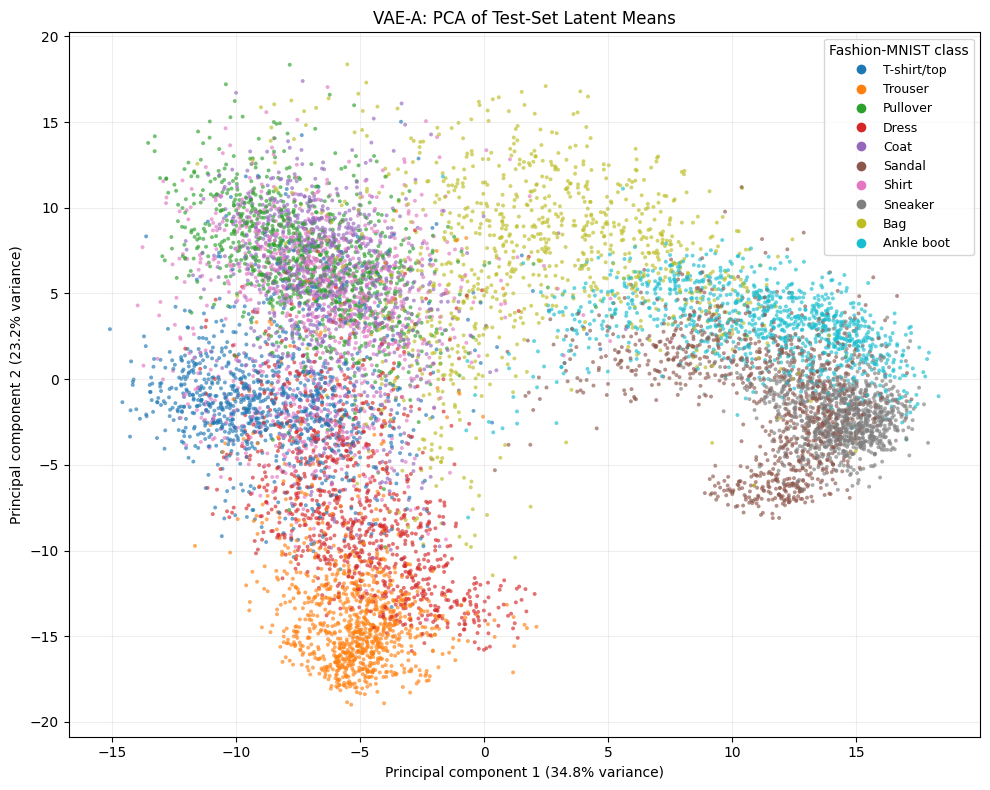

Saved PCA plot: outputs/figures/p2b_i_vae_a_pca.png
Explained variance by first two components: 58.03%


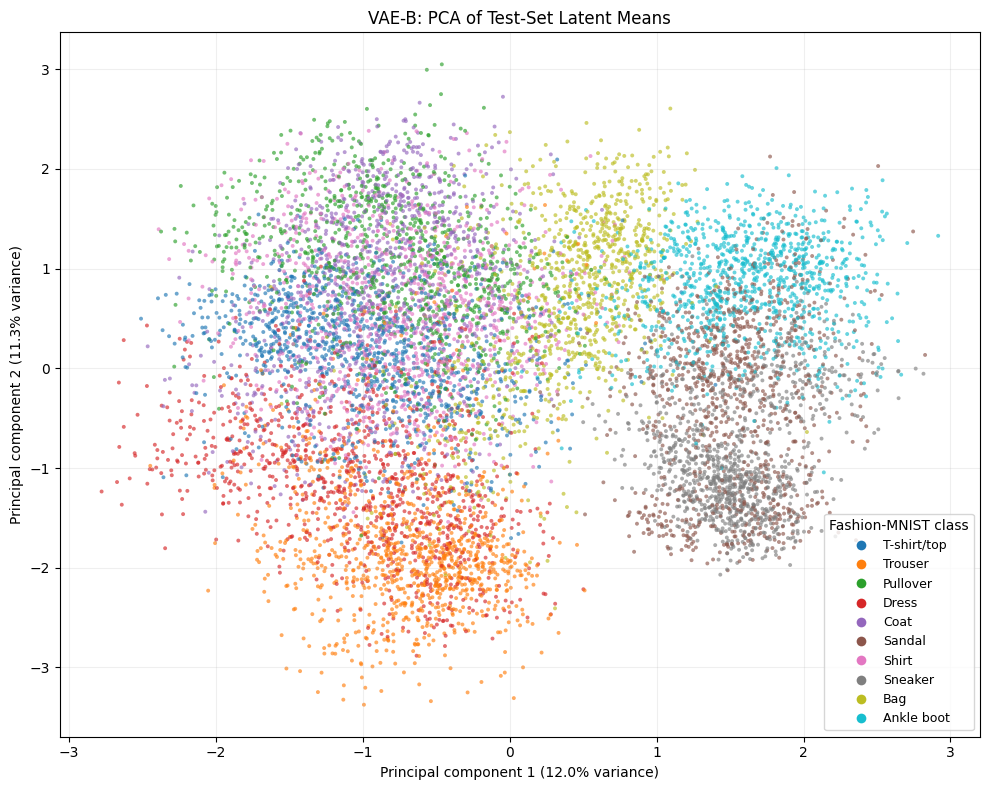

Saved PCA plot: outputs/figures/p2b_i_vae_b_pca.png
Explained variance by first two components: 23.30%


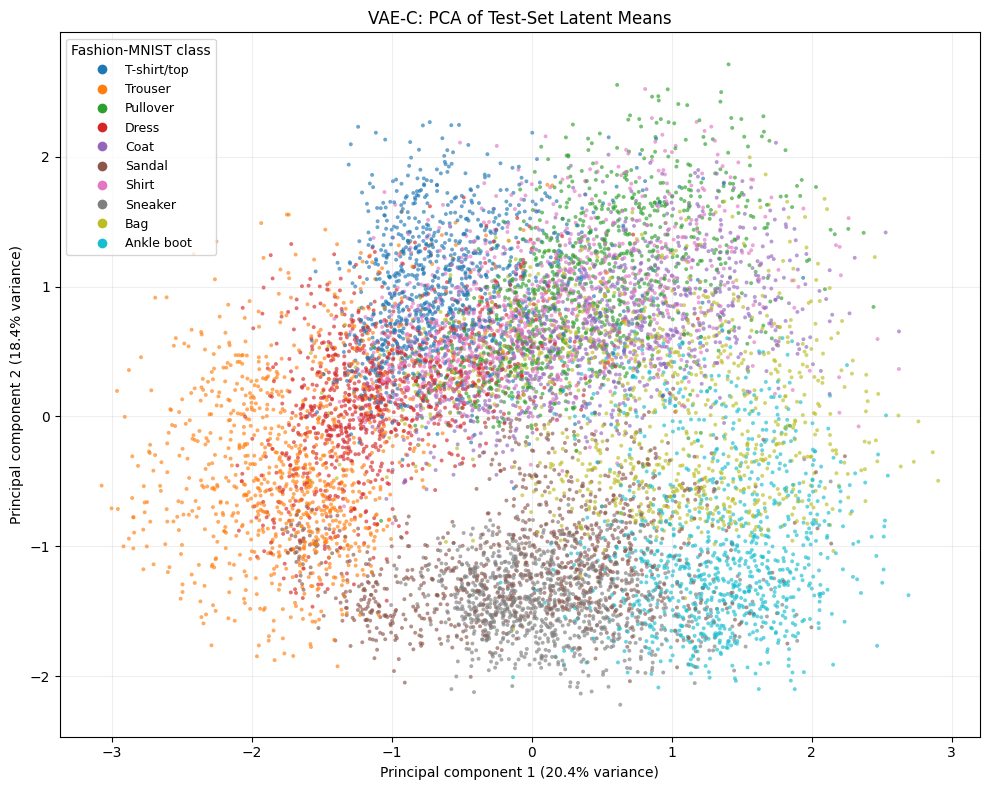

Saved PCA plot: outputs/figures/p2b_i_vae_c_pca.png
Explained variance by first two components: 38.72%


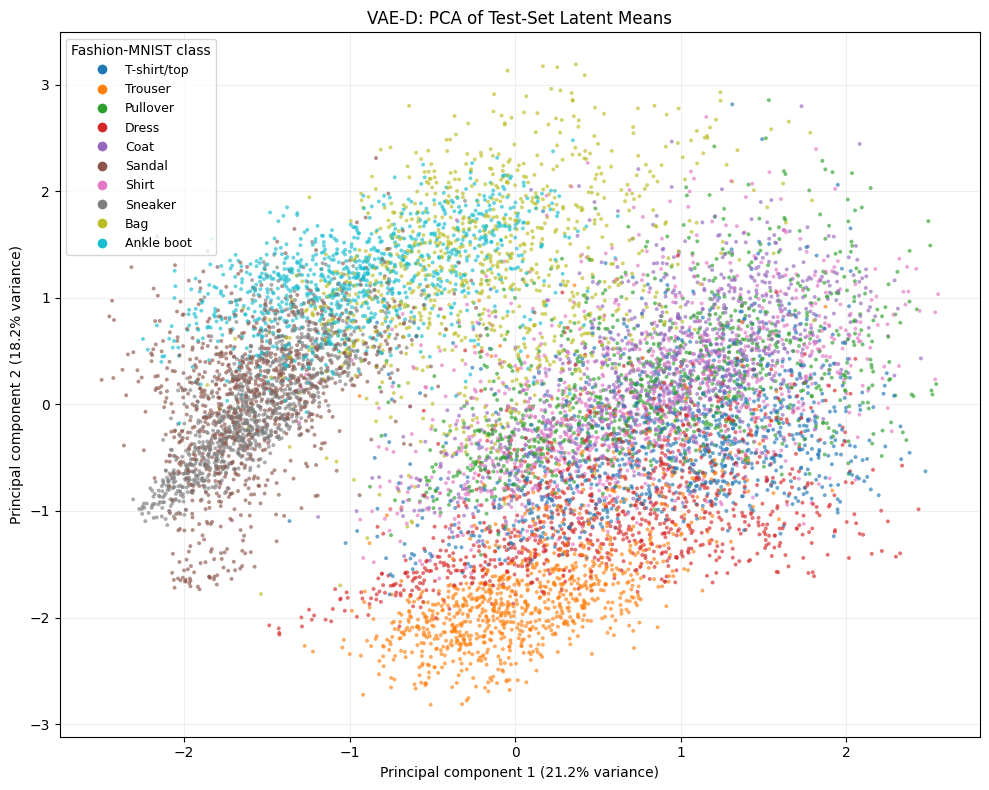

Saved PCA plot: outputs/figures/p2b_i_vae_d_pca.png
Explained variance by first two components: 39.44%


In [48]:
# Problem 2B (i): Encode the complete test set and visualize the latent means using PCA to two dimensions,
# colored by Fashion-MNIST class.
# PCA: scikit-learn docs, https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader
import os

@torch.no_grad()
def encode_dataset(model, dataset):
    # TODO: return mu [N, 16], logvar [N, 16], labels [N] as numpy arrays (no shuffling, model.eval()).
    model.eval()
    device = next(model.parameters()).device

    # No shuffling ensures the original dataset order is preserved.
    loader = DataLoader(dataset, batch_size=256, shuffle=False)

    all_mu = []
    all_logvar = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)

        mu, logvar = model.encode(images)

        all_mu.append(mu.cpu().numpy())
        all_logvar.append(logvar.cpu().numpy())
        all_labels.append(labels.numpy())

    mu = np.concatenate(all_mu, axis=0)
    logvar = np.concatenate(all_logvar, axis=0)
    labels = np.concatenate(all_labels, axis=0)

    return mu, logvar, labels


def pca_plot(mu, labels, name):
    # TODO: fit PCA(n_components=2) on mu, scatter colored by class with a legend of FASHION_CLASSES.
    #       Return the fitted PCA so the same transform can be applied to prior samples in (ii).
    mu = np.asarray(mu)
    labels = np.asarray(labels)

    if mu.ndim != 2 or mu.shape[1] != LATENT_DIM:
        raise ValueError(
            f"Expected mu with shape [N, {LATENT_DIM}], got {mu.shape}"
        )

    pca = PCA(n_components=2)
    mu_2d = pca.fit_transform(mu)

    figures_dir = os.path.join(OUT_DIR, "figures")
    os.makedirs(figures_dir, exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 8))

    # Use the actual class indices as labels so colors match Fashion-MNIST.
    scatter = ax.scatter(
        mu_2d[:, 0],
        mu_2d[:, 1],
        c=labels,
        cmap="tab10",
        vmin=-0.5,
        vmax=9.5,
        s=8,
        alpha=0.65,
        linewidths=0
    )

    # Build a class-name legend using the assignment's FASHION_CLASSES.
    handles, _ = scatter.legend_elements(
        num=10,
        prop="colors",
        alpha=0.8
    )
    class_handles = [
        plt.Line2D(
            [], [],
            marker="o",
            linestyle="",
            markersize=7,
            markerfacecolor=plt.cm.tab10(i),
            markeredgecolor="none",
            label=str(FASHION_CLASSES[i])
        )
        for i in range(len(FASHION_CLASSES))
    ]

    ax.legend(
        handles=class_handles,
        title="Fashion-MNIST class",
        loc="best",
        fontsize=9
    )

    explained = pca.explained_variance_ratio_ * 100
    ax.set_xlabel(f"Principal component 1 ({explained[0]:.1f}% variance)")
    ax.set_ylabel(f"Principal component 2 ({explained[1]:.1f}% variance)")
    ax.set_title(f"{name}: PCA of Test-Set Latent Means")
    ax.grid(True, alpha=0.2)

    fig.tight_layout()

    filename = f"p2b_i_{name.lower().replace('-', '_')}_pca.png"
    save_path = os.path.join(figures_dir, filename)
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved PCA plot: {save_path}")
    print(
        f"Explained variance by first two components: "
        f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
    )

    return pca


# Encode the complete test set for every trained model.
encoded = {
    name: encode_dataset(model, test_set)
    for name, model in models.items()
}

# Fit and plot a separate PCA for each model.
pcas = {}
for name, (mu, logvar, labels) in encoded.items():
    pcas[name] = pca_plot(mu, labels, name)


# encoded = {name: encode_dataset(m, test_set) for name, m in models.items()}

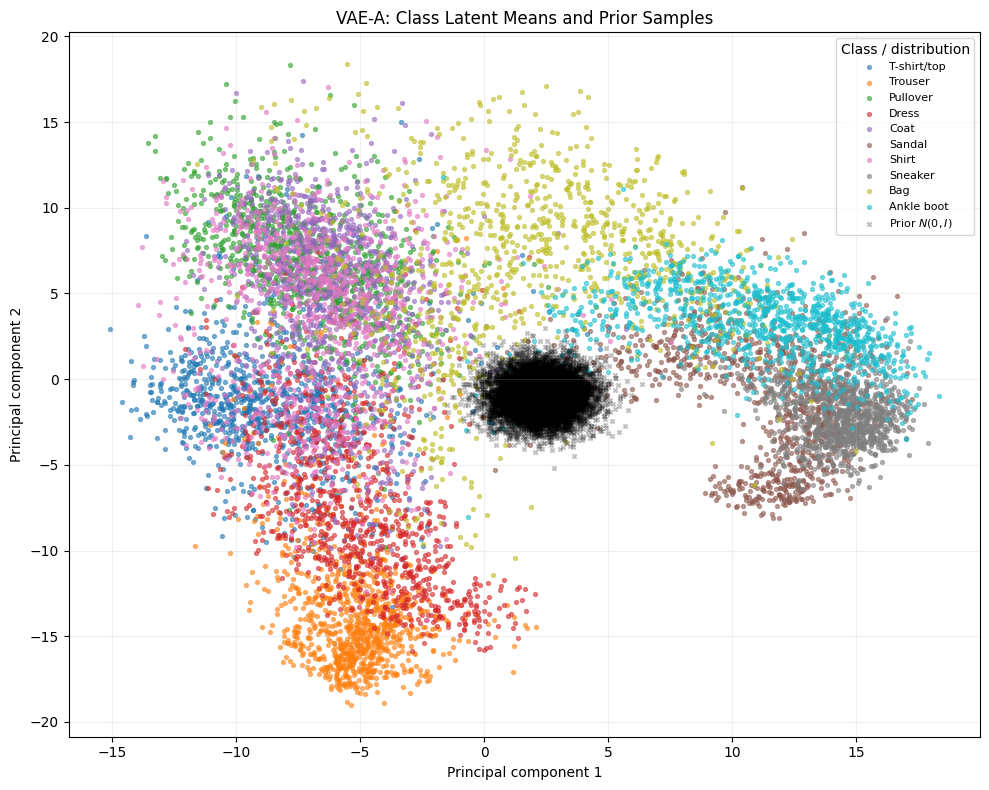

Posterior means: 10000; prior samples: 10000
Saved plot: outputs/figures/p2b_ii_vae_a_prior_overlay.png


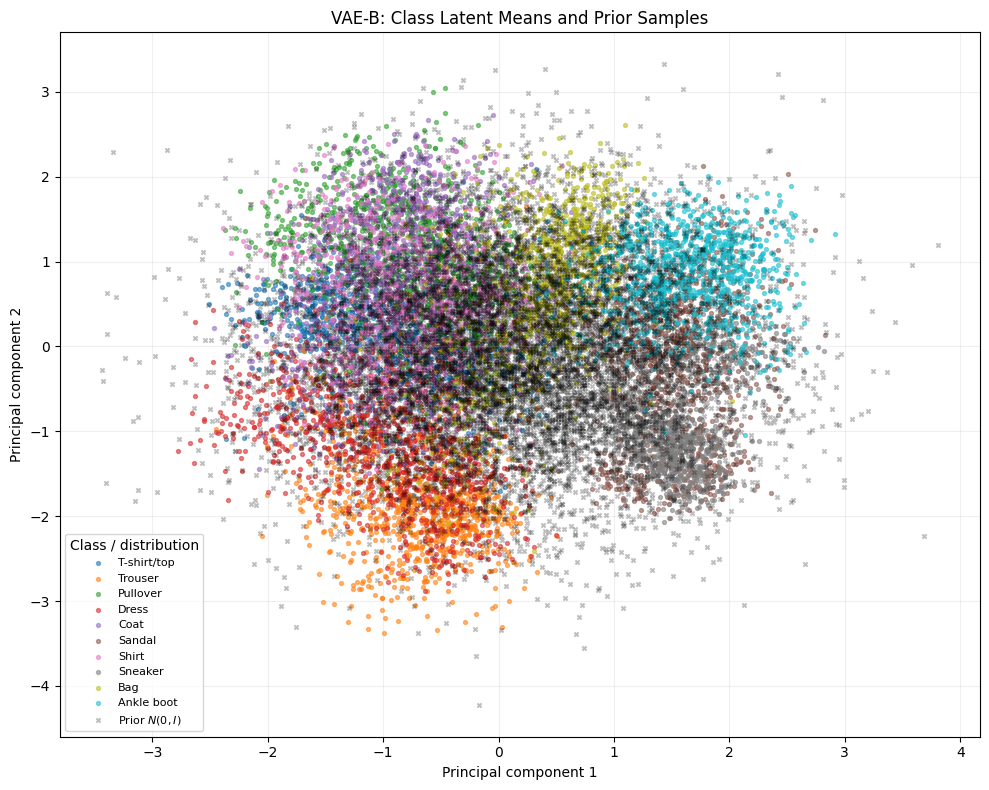

Posterior means: 10000; prior samples: 10000
Saved plot: outputs/figures/p2b_ii_vae_b_prior_overlay.png


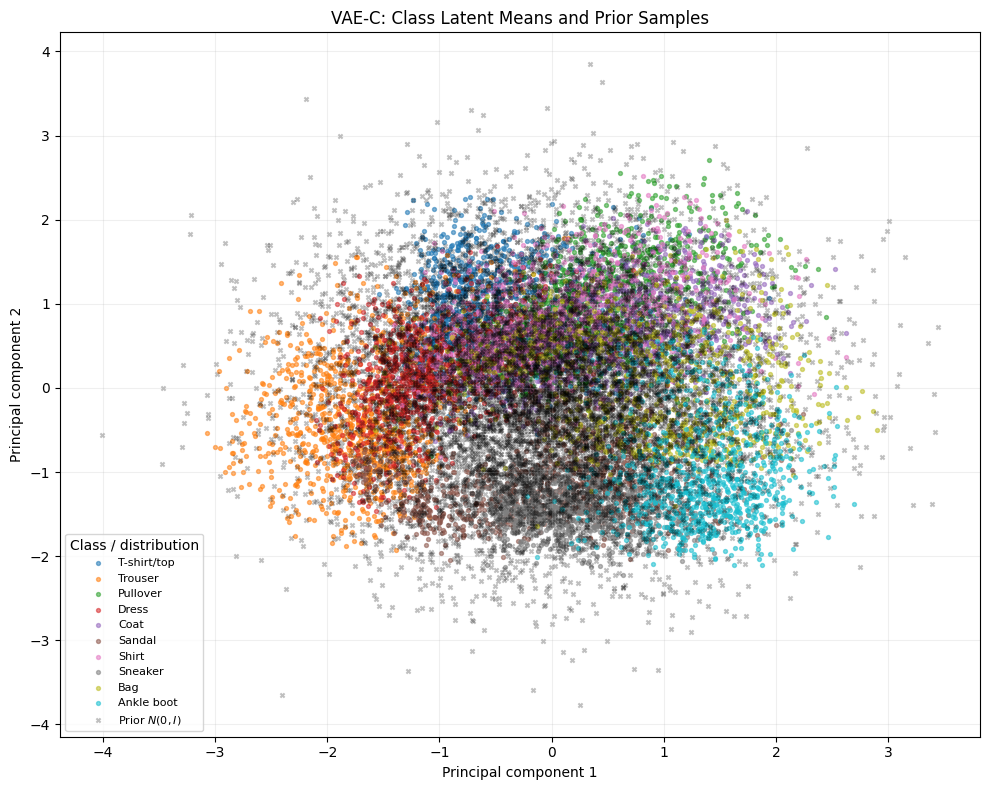

Posterior means: 10000; prior samples: 10000
Saved plot: outputs/figures/p2b_ii_vae_c_prior_overlay.png


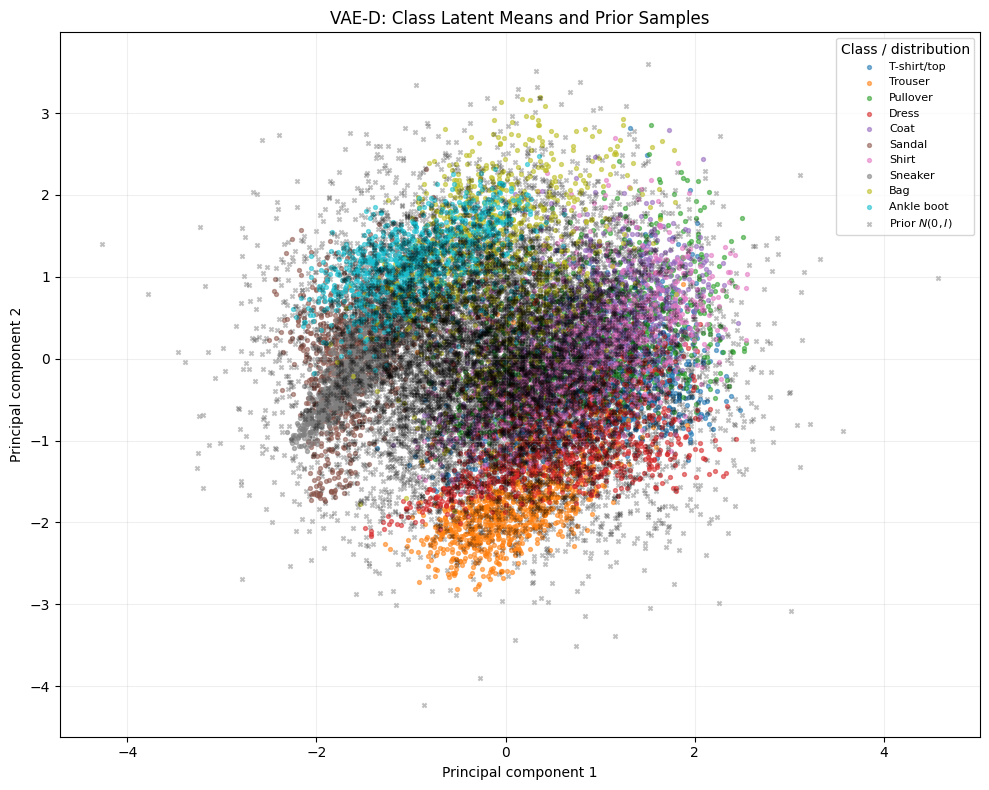

Posterior means: 10000; prior samples: 10000
Saved plot: outputs/figures/p2b_ii_vae_d_prior_overlay.png


In [49]:

# Problem 2B (ii): Overlay class-colored posterior means and prior samples.

def pca_prior_overlay(pca, mu, labels, n_seed=SEED, name="VAE"):
    """
    Reuse the fitted PCA to compare class-colored posterior means
    against an equal number of samples from N(0, I).
    """
    mu = np.asarray(mu)
    labels = np.asarray(labels)
    n_samples, latent_dim = mu.shape

    # Draw the same number of reproducible prior samples.
    rng = np.random.default_rng(n_seed)
    prior_z = rng.standard_normal((n_samples, latent_dim))

    # Use the existing PCA from Problem 2B (i).
    posterior_2d = pca.transform(mu)
    prior_2d = pca.transform(prior_z)

    # Equal axis limits across both distributions.
    all_points = np.concatenate([posterior_2d, prior_2d], axis=0)
    x_min, y_min = all_points.min(axis=0)
    x_max, y_max = all_points.max(axis=0)
    x_pad = max((x_max - x_min) * 0.05, 1e-6)
    y_pad = max((y_max - y_min) * 0.05, 1e-6)

    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot each class separately so the class structure remains visible.
    for class_idx, class_name in enumerate(FASHION_CLASSES):
        mask = labels == class_idx
        if np.any(mask):
            ax.scatter(
                posterior_2d[mask, 0],
                posterior_2d[mask, 1],
                s=8,
                alpha=0.55,
                label=str(class_name)
            )

    # Prior samples in black, plotted with low visual prominence.
    ax.scatter(
        prior_2d[:, 0],
        prior_2d[:, 1],
        s=9,
        alpha=0.25,
        c="black",
        marker="x",
        label=r"Prior $N(0,I)$"
    )

    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
    ax.set_title(f"{name}: Class Latent Means and Prior Samples")
    ax.legend(title="Class / distribution", fontsize=8)
    ax.grid(True, alpha=0.2)
    fig.tight_layout()

    figures_dir = os.path.join(OUT_DIR, "figures")
    os.makedirs(figures_dir, exist_ok=True)
    filename = f"p2b_ii_{name.lower().replace('-', '_')}_prior_overlay.png"
    save_path = os.path.join(figures_dir, filename)
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Posterior means: {n_samples}; prior samples: {len(prior_z)}")
    print(f"Saved plot: {save_path}")

    return prior_z, prior_2d


# Reuse the PCA fitted for each model in Problem 2B (i).
prior_samples = {}

for name, (mu, logvar, labels) in encoded.items():
    prior_z, prior_2d = pca_prior_overlay(
        pca=pcas[name],
        mu=mu,
        labels=labels,
        n_seed=SEED,
        name=name
    )
    prior_samples[name] = (prior_z, prior_2d)


In [50]:
# Problem 2B (iii): Discuss class overlap, gaps, isolated regions, scale mismatch, and excessive concentration.

**2B (iii) — your answer:**

_TODO: write your answer here._

In [51]:
# Problem 2B (iv): Explain why a two-dimensional projection cannot establish prior matching or semantic
# disentanglement in the original 16-dimensional space.
# (Optional supporting numbers: pca.explained_variance_ratio_, per-dimension mean/variance of the aggregate posterior.)

**2B (iv) — your answer:**

_TODO: write your answer here._

### 2C. Interpolation and traversal (10 pts)

In [52]:
# Problem 2C — PREDICTION: which model will interpolate most smoothly / plausibly, and why?

**2C prediction — your answer:**

_TODO: write your answer here._

Image A: index=0, class=9
Image B: index=1, class=2


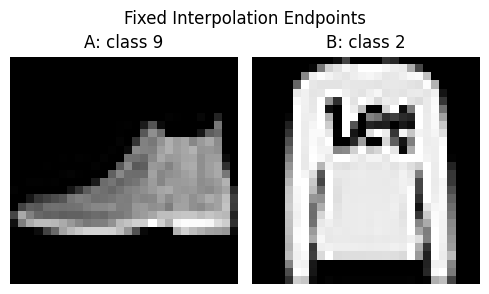

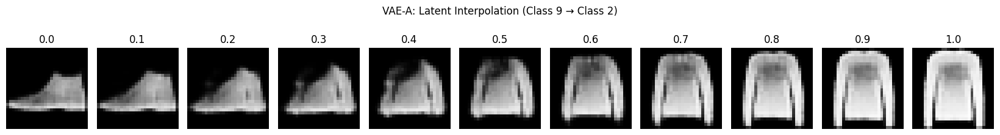

VAE-A: decoded shape = (11, 1, 28, 28)
Saved figure: outputs/figures/p2c_i_vae_a_interpolation.png


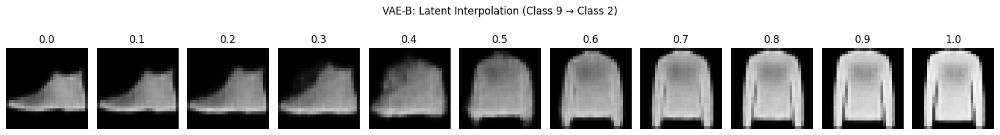

VAE-B: decoded shape = (11, 1, 28, 28)
Saved figure: outputs/figures/p2c_i_vae_b_interpolation.png


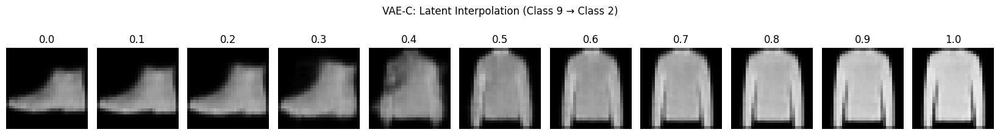

VAE-C: decoded shape = (11, 1, 28, 28)
Saved figure: outputs/figures/p2c_i_vae_c_interpolation.png


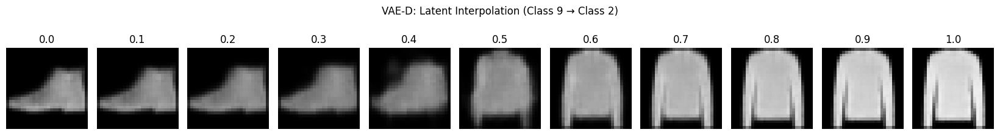

VAE-D: decoded shape = (11, 1, 28, 28)
Saved figure: outputs/figures/p2c_i_vae_d_interpolation.png


In [53]:
# Problem 2C (i): Choose two test images from different classes. Use their posterior means as endpoints and
# decode at least 11 linear interpolation points z(alpha) = (1 - alpha) z_a + alpha z_b, alpha in [0, 1].
# Repeat for VAE-A, VAE-B, VAE-C, and VAE-D (same two images for all four).

import os
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Choose two test images from different Fashion-MNIST classes
# ------------------------------------------------------------

# Automatically select two indices with different labels.
IDX_A = 0
label_a = int(test_set[IDX_A][1])

IDX_B = next(
    idx for idx in range(1, len(test_set))
    if int(test_set[idx][1]) != label_a
)

x_a, y_a = test_set[IDX_A]
x_b, y_b = test_set[IDX_B]

assert int(y_a) != int(y_b), "Choose images from different classes."

print(f"Image A: index={IDX_A}, class={int(y_a)}")
print(f"Image B: index={IDX_B}, class={int(y_b)}")

# Display the chosen endpoints.
fig, axes = plt.subplots(1, 2, figsize=(5, 3))

axes[0].imshow(x_a.squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"A: class {int(y_a)}")
axes[0].axis("off")

axes[1].imshow(x_b.squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"B: class {int(y_b)}")
axes[1].axis("off")

fig.suptitle("Fixed Interpolation Endpoints")
fig.tight_layout()
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 2. Interpolate between posterior means
# ------------------------------------------------------------

@torch.no_grad()
def interpolate(model, x_a, x_b, n_points=11):
    """
    Interpolate between the posterior means of two input images.

    Args:
        model: trained VAE
        x_a, x_b: images shaped [1, 28, 28]
        n_points: number of interpolation points, at least 11

    Returns:
        decoded: [n_points, 1, 28, 28]
    """
    if n_points < 11:
        raise ValueError("n_points must be at least 11.")

    model.eval()
    device = next(model.parameters()).device

    # Add batch dimensions and move images to the model's device.
    x_a = x_a.unsqueeze(0).to(device)
    x_b = x_b.unsqueeze(0).to(device)

    # Encode both endpoints; use posterior means, not sampled z values.
    mu_a, logvar_a = model.encode(x_a)
    mu_b, logvar_b = model.encode(x_b)

    # n_points evenly spaced values, including 0 and 1.
    alphas = torch.linspace(0.0, 1.0, n_points, device=device)

    # z(alpha) = (1 - alpha) * mu_a + alpha * mu_b
    z = (1.0 - alphas[:, None]) * mu_a + alphas[:, None] * mu_b

    # Decode all interpolated latent vectors.
    decoded = model.decode(z)

    expected_shape = (n_points, 1, 28, 28)
    assert tuple(decoded.shape) == expected_shape, (
        f"Expected {expected_shape}, got {tuple(decoded.shape)}"
    )

    return decoded, alphas


# ------------------------------------------------------------
# 3. Run interpolation for VAE-A, VAE-B, VAE-C, and VAE-D
# ------------------------------------------------------------

N_POINTS = 11  # At least 11 points, including both endpoints.

figures_dir = os.path.join(OUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

interpolations = {}

for name, model in models.items():
    decoded, alphas = interpolate(
        model=model,
        x_a=x_a,
        x_b=x_b,
        n_points=N_POINTS
    )

    # Save generated images in CPU memory for later comparison.
    interpolations[name] = decoded.cpu()

    # Plot the interpolation sequence for this model.
    fig, axes = plt.subplots(
        1, N_POINTS,
        figsize=(1.5 * N_POINTS, 2.5)
    )

    for i, ax in enumerate(axes):
        ax.imshow(
            decoded[i, 0].cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        ax.set_title(f"{alphas[i].item():.1f}")
        ax.axis("off")

    fig.suptitle(
        f"{name}: Latent Interpolation "
        f"(Class {int(y_a)} → Class {int(y_b)})"
    )
    fig.tight_layout()

    filename = f"p2c_i_{name.lower().replace('-', '_')}_interpolation.png"
    save_path = os.path.join(figures_dir, filename)

    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"{name}: decoded shape = {tuple(decoded.shape)}")
    print(f"Saved figure: {save_path}")


Top three latent dimensions for VAE-B:
  Dimension 2: variance = 1.275718
  Dimension 9: variance = 1.186492
  Dimension 11: variance = 0.990626

Base latent vector: zero vector of length 16
Traversal values: [-3, -2, -1, 0, 1, 2, 3]


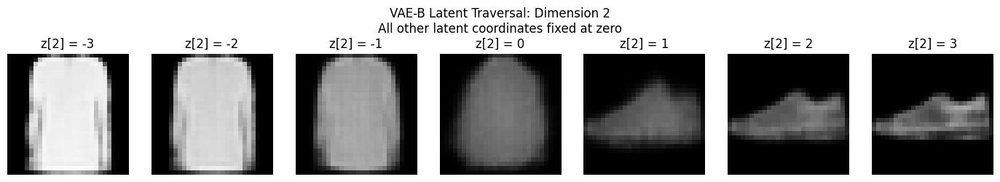

Dimension 2: decoded shape = (7, 1, 28, 28)
Saved figure: outputs/figures/p2c_ii_vae_b_dim_2_traversal.png


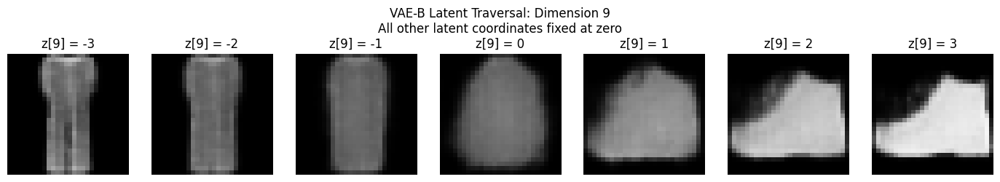

Dimension 9: decoded shape = (7, 1, 28, 28)
Saved figure: outputs/figures/p2c_ii_vae_b_dim_9_traversal.png


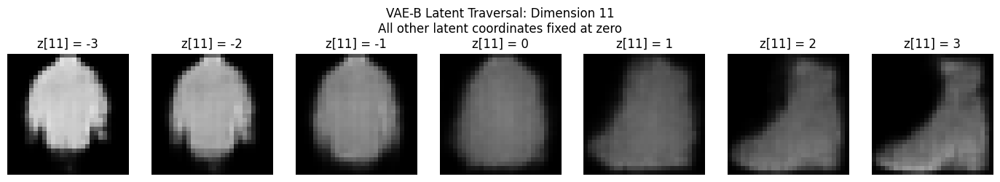

Dimension 11: decoded shape = (7, 1, 28, 28)
Saved figure: outputs/figures/p2c_ii_vae_b_dim_11_traversal.png


In [54]:
# Problem 2C (ii): For VAE-B, select the three dimensions with the largest Var_x[mu_j(x)] and traverse each one
# over {-3, -2, -1, 0, 1, 2, 3} while holding all other coordinates fixed.
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

TRAVERSAL_VALUES = [-3, -2, -1, 0, 1, 2, 3]

# ------------------------------------------------------------
# 1. Select the three dimensions with largest variance in mu_j(x)
# ------------------------------------------------------------

# encoded["VAE-B"] = (mu, logvar, labels) from Problem 2B (i).
mu_B = encoded["VAE-B"][0]  # Shape: [N_test, LATENT_DIM]

# Compute Var_x[mu_j(x)] across the complete test set.
latent_variances = mu_B.var(axis=0, ddof=0)

# Sort dimensions by decreasing variance and take the top three.
top3 = np.argsort(latent_variances)[::-1][:3]

print("Top three latent dimensions for VAE-B:")
for dim in top3:
    print(f"  Dimension {dim}: variance = {latent_variances[dim]:.6f}")


# ------------------------------------------------------------
# 2. Traverse one latent dimension while fixing all others
# ------------------------------------------------------------

@torch.no_grad()
def traverse(model, z_base, dim, values=TRAVERSAL_VALUES):
    """
    Decode latent vectors that vary in only one coordinate.

    Args:
        model: trained VAE model
        z_base: fixed latent vector, shape [LATENT_DIM] or [1, LATENT_DIM]
        dim: latent coordinate to vary
        values: values assigned to z[:, dim]

    Returns:
        decoded: [len(values), 1, 28, 28] tensor
    """
    model.eval()
    device = next(model.parameters()).device

    # Copy and normalize z_base to shape [1, LATENT_DIM].
    z_base = torch.as_tensor(
        z_base, dtype=torch.float32, device=device
    ).detach().clone()

    if z_base.ndim == 1:
        z_base = z_base.unsqueeze(0)

    if z_base.ndim != 2 or z_base.shape != (1, LATENT_DIM):
        raise ValueError(
            f"z_base must have shape [{LATENT_DIM}] or [1, {LATENT_DIM}], "
            f"got {tuple(z_base.shape)}"
        )

    if not 0 <= dim < LATENT_DIM:
        raise ValueError(f"dim must be between 0 and {LATENT_DIM - 1}")

    # Make one independent copy of z_base for every traversal value.
    z_values = z_base.repeat(len(values), 1)

    # Change only the selected coordinate; hold all others fixed.
    z_values[:, dim] = torch.as_tensor(
        values, dtype=z_values.dtype, device=device
    )

    # Decode all traversal points.
    decoded = model.decode(z_values)

    expected_shape = (len(values), 1, 28, 28)
    assert tuple(decoded.shape) == expected_shape, (
        f"Expected {expected_shape}, got {tuple(decoded.shape)}"
    )

    return decoded


# ------------------------------------------------------------
# 3. Use the zero vector as the fixed base latent code
# ------------------------------------------------------------

# Explicitly define z_base = 0 in all latent dimensions.
z_base = torch.zeros(LATENT_DIM, dtype=torch.float32)

print(f"\nBase latent vector: zero vector of length {LATENT_DIM}")
print(f"Traversal values: {TRAVERSAL_VALUES}")


# ------------------------------------------------------------
# 4. Generate and save traversal plots for the top three dimensions
# ------------------------------------------------------------

figures_dir = os.path.join(OUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

model_B = models["VAE-B"]
traversal_results = {}

for dim in top3:
    decoded = traverse(
        model=model_B,
        z_base=z_base,
        dim=int(dim),
        values=TRAVERSAL_VALUES
    )

    traversal_results[int(dim)] = decoded.cpu()

    fig, axes = plt.subplots(
        1, len(TRAVERSAL_VALUES),
        figsize=(2 * len(TRAVERSAL_VALUES), 2.5)
    )

    for i, ax in enumerate(axes):
        ax.imshow(
            decoded[i, 0].cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        ax.set_title(f"z[{dim}] = {TRAVERSAL_VALUES[i]}")
        ax.axis("off")

    fig.suptitle(
        f"VAE-B Latent Traversal: Dimension {dim}\n"
        "All other latent coordinates fixed at zero"
    )
    fig.tight_layout()

    save_path = os.path.join(
        figures_dir, f"p2c_ii_vae_b_dim_{dim}_traversal.png"
    )
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Dimension {dim}: decoded shape = {tuple(decoded.shape)}")
    print(f"Saved figure: {save_path}")

# mu_B = encoded["VAE-B"][0]; top3 = np.argsort(mu_B.var(axis=0))[::-1][:3]

In [55]:
# Problem 2C (iii): Discuss continuity, plausibility, and coupled attribute changes. Explain why a smooth
# interpolation does not prove that the latent variables are disentangled.

**2C (iii) — your answer:**

_TODO: write your answer here._

## Problem 3: Diagnosing Posterior Collapse (30 pts)

### 3A. Per-dimension diagnostics (12 pts)

In [56]:
# Problem 3A — PREDICTION: which models will have the fewest active dimensions?

**3A prediction — your answer:**

_TODO: write your answer here._

In [57]:
# Problem 3A (i): For each latent dimension j compute
#   KL_j = 1/(2N) * sum_i ( mu_ij^2 + exp(logvar_ij) - logvar_ij - 1 )
# Report all 16 values of KL_j and their sum.

import numpy as np

def per_dim_kl(mu, logvar):
    """
    Compute the average KL divergence for each latent dimension.

    Args:
        mu:     [N, 16] posterior means for N test examples
        logvar: [N, 16] posterior log-variances for N test examples

    Returns:
        kl_per_dim: NumPy array of shape [16], one KL value per dimension
    """
    mu = np.asarray(mu)
    logvar = np.asarray(logvar)

    if mu.shape != logvar.shape:
        raise ValueError(
            f"mu and logvar must have matching shapes; "
            f"got {mu.shape} and {logvar.shape}"
        )

    if mu.ndim != 2 or mu.shape[1] != LATENT_DIM:
        raise ValueError(
            f"Expected mu and logvar with shape [N, {LATENT_DIM}], "
            f"got {mu.shape}"
        )

    N = mu.shape[0]
    if N == 0:
        raise ValueError("Cannot compute KL divergence for an empty dataset.")

    # KL contribution for every example and every latent dimension.
    kl_terms = (
        mu**2
        + np.exp(logvar)
        - logvar
        - 1.0
    )

    # Sum across examples and divide by 2N.
    kl_per_dim = kl_terms.sum(axis=0) / (2.0 * N)

    return kl_per_dim


# ------------------------------------------------------------
# Compute and report all 16 dimensions for each VAE configuration.
# Reuse the full-test-set encodings from Problem 2B (i).
# encoded[name] = (mu, logvar, labels)
# ------------------------------------------------------------

for name, (mu, logvar, labels) in encoded.items():
    kl_values = per_dim_kl(mu, logvar)

    print(f"\n{name}: Per-dimension KL divergence")
    for j, value in enumerate(kl_values):
        print(f"  KL_{j:02d} = {value:.8f}")

    print(f"Sum of 16 KL dimensions: {kl_values.sum():.8f}")



VAE-A: Per-dimension KL divergence
  KL_00 = 19.69577217
  KL_01 = 18.15644455
  KL_02 = 16.25312805
  KL_03 = 17.91071320
  KL_04 = 25.46177864
  KL_05 = 13.86107540
  KL_06 = 11.92184258
  KL_07 = 19.79469299
  KL_08 = 14.31320477
  KL_09 = 25.30765533
  KL_10 = 13.43722534
  KL_11 = 20.92034912
  KL_12 = 12.39258099
  KL_13 = 18.79681587
  KL_14 = 26.63378143
  KL_15 = 17.49787903
Sum of 16 KL dimensions: 292.35491943

VAE-B: Per-dimension KL divergence
  KL_00 = 0.56824905
  KL_01 = 1.15191698
  KL_02 = 2.49042630
  KL_03 = 1.06121016
  KL_04 = 0.54482508
  KL_05 = 0.31168598
  KL_06 = 0.59224176
  KL_07 = 0.51718038
  KL_08 = 1.19092166
  KL_09 = 2.16475582
  KL_10 = 0.42007682
  KL_11 = 1.65820074
  KL_12 = 0.46835977
  KL_13 = 0.97365409
  KL_14 = 1.54160035
  KL_15 = 1.15667248
Sum of 16 KL dimensions: 16.81197739

VAE-C: Per-dimension KL divergence
  KL_00 = 0.00779028
  KL_01 = 1.84321153
  KL_02 = 0.00154690
  KL_03 = 0.96652275
  KL_04 = 0.73813611
  KL_05 = 0.00228194
  K

In [58]:
import os
import pandas as pd

metrics_dir = os.path.join(OUT_DIR, "metrics")
os.makedirs(metrics_dir, exist_ok=True)

rows = []

for name, (mu, logvar, labels) in encoded.items():
    kl_values = per_dim_kl(mu, logvar)

    row = {"model": name}
    row.update({
        f"KL_{j}": float(value)
        for j, value in enumerate(kl_values)
    })
    row["KL_sum"] = float(kl_values.sum())
    rows.append(row)

kl_df = pd.DataFrame(rows)
csv_path = os.path.join(metrics_dir, "p3a_i_per_dim_kl.csv")
kl_df.to_csv(csv_path, index=False)

print(kl_df.to_string(index=False))
print(f"\nSaved per-dimension KL results to: {csv_path}")


model      KL_0      KL_1      KL_2      KL_3      KL_4      KL_5      KL_6      KL_7      KL_8      KL_9     KL_10     KL_11     KL_12     KL_13     KL_14     KL_15     KL_sum
VAE-A 19.695772 18.156445 16.253128 17.910713 25.461779 13.861075 11.921843 19.794693 14.313205 25.307655 13.437225 20.920349 12.392581 18.796816 26.633781 17.497879 292.354919
VAE-B  0.568249  1.151917  2.490426  1.061210  0.544825  0.311686  0.592242  0.517180  1.190922  2.164756  0.420077  1.658201  0.468360  0.973654  1.541600  1.156672  16.811977
VAE-C  0.007790  1.843212  0.001547  0.966523  0.738136  0.002282  0.022384  0.001777  0.976024  1.501652  0.005878  0.002674  1.027988  0.001884  0.152754  0.003295   7.255798
VAE-D  0.609918  1.409160  1.224411  0.154891  0.134506  0.543643  0.001683  0.002419  0.008949  1.155776  0.050709  0.291509  0.050456  0.004780  1.447934  0.154867   7.245609

Saved per-dimension KL results to: outputs/metrics/p3a_i_per_dim_kl.csv


In [59]:
# Problem 3A (ii): Report the number of active dimensions (active when KL_j > 0.01).
# Active units idea: Burda et al. (2016), "Importance Weighted Autoencoders", https://arxiv.org/abs/1509.00519
# (they use a variance criterion; the handout prescribes the KL_j > 0.01 criterion — use that.)

ACTIVE_THRESHOLD = 0.01

def count_active(kl_j, threshold=ACTIVE_THRESHOLD):
    """
    Count latent dimensions whose per-dimension KL exceeds the threshold.

    Args:
        kl_j: array of per-dimension KL values (e.g., shape [16])
        threshold: activity threshold, default 0.01

    Returns:
        Number of active latent dimensions.
    """
    kl_j = np.asarray(kl_j)

    if kl_j.ndim != 1:
        raise ValueError(f"Expected a 1D array of KL values, got {kl_j.shape}")

    return int(np.sum(kl_j > threshold))


# Report the active dimension count for each model.
for name, (mu, logvar, labels) in encoded.items():
    kl_values = per_dim_kl(mu, logvar)
    active_count = count_active(kl_values)

    print(
        f"{name}: {active_count}/{len(kl_values)} active latent dimensions "
        f"(threshold = {ACTIVE_THRESHOLD})"
    )


VAE-A: 16/16 active latent dimensions (threshold = 0.01)
VAE-B: 16/16 active latent dimensions (threshold = 0.01)
VAE-C: 8/16 active latent dimensions (threshold = 0.01)
VAE-D: 12/16 active latent dimensions (threshold = 0.01)


In [60]:
import os
import pandas as pd

metrics_dir = os.path.join(OUT_DIR, "metrics")
os.makedirs(metrics_dir, exist_ok=True)

rows = []

for name, (mu, logvar, labels) in encoded.items():
    kl_values = per_dim_kl(mu, logvar)

    rows.append({
        "model": name,
        "active_dimensions": count_active(kl_values),
        "total_dimensions": len(kl_values),
        "threshold": ACTIVE_THRESHOLD,
        "KL_sum": float(kl_values.sum()),
    })

active_df = pd.DataFrame(rows)
csv_path = os.path.join(metrics_dir, "p3a_ii_active_dimensions.csv")
active_df.to_csv(csv_path, index=False)

print(active_df.to_string(index=False))
print(f"\nSaved results to: {csv_path}")


model  active_dimensions  total_dimensions  threshold     KL_sum
VAE-A                 16                16       0.01 292.354919
VAE-B                 16                16       0.01  16.811977
VAE-C                  8                16       0.01   7.255798
VAE-D                 12                16       0.01   7.245609

Saved results to: outputs/metrics/p3a_ii_active_dimensions.csv


In [61]:
# Problem 3A (iii): Report Var_x[mu_j(x)] for every dimension.
# TODO: build a table: rows = models, columns = KL_0..KL_15, sum, #active, Var(mu_0)..Var(mu_15). Save CSV.
# Problem 3A (iii): Report Var_x[mu_j(x)] for every dimension.

import numpy as np

def mu_variance(mu):
    """
    Compute the variance of each latent posterior mean dimension
    across all test examples.

    Args:
        mu: array of shape (N, LATENT_DIM)

    Returns:
        Array of shape (LATENT_DIM,)
    """
    mu = np.asarray(mu)

    if mu.ndim != 2 or mu.shape[1] != LATENT_DIM:
        raise ValueError(
            f"Expected mu with shape (N, {LATENT_DIM}), got {mu.shape}"
        )

    if mu.shape[0] == 0:
        raise ValueError("mu must contain at least one example.")

    # Population variance across test examples, separately for each dimension.
    return np.var(mu, axis=0, ddof=0)


# Print all 16 variances for every model.
for name, (mu, logvar, labels) in encoded.items():
    variances = mu_variance(mu)

    print(f"\n{name}:")
    for j, value in enumerate(variances):
        print(f"  Var(mu_{j}) = {value:.6f}")


VAE-A:
  Var(mu_0) = 16.793852
  Var(mu_1) = 17.417255
  Var(mu_2) = 15.297583
  Var(mu_3) = 8.051351
  Var(mu_4) = 20.013836
  Var(mu_5) = 8.623232
  Var(mu_6) = 5.813800
  Var(mu_7) = 5.064568
  Var(mu_8) = 9.994976
  Var(mu_9) = 33.534870
  Var(mu_10) = 8.331607
  Var(mu_11) = 18.403473
  Var(mu_12) = 7.536520
  Var(mu_13) = 11.610836
  Var(mu_14) = 24.053564
  Var(mu_15) = 17.799299

VAE-B:
  Var(mu_0) = 0.588583
  Var(mu_1) = 0.817990
  Var(mu_2) = 1.275718
  Var(mu_3) = 0.775136
  Var(mu_4) = 0.554817
  Var(mu_5) = 0.399160
  Var(mu_6) = 0.579950
  Var(mu_7) = 0.566880
  Var(mu_8) = 0.814060
  Var(mu_9) = 1.186492
  Var(mu_10) = 0.499325
  Var(mu_11) = 0.990626
  Var(mu_12) = 0.509057
  Var(mu_13) = 0.777436
  Var(mu_14) = 0.988345
  Var(mu_15) = 0.798948

VAE-C:
  Var(mu_0) = 0.014854
  Var(mu_1) = 1.034563
  Var(mu_2) = 0.002593
  Var(mu_3) = 0.816911
  Var(mu_4) = 0.666263
  Var(mu_5) = 0.003065
  Var(mu_6) = 0.039309
  Var(mu_7) = 0.003074
  Var(mu_8) = 0.829039
  Var(mu_9) 

In [62]:
# Problem 3A: Combined KL, active-dimension, and variance table.

import os
import pandas as pd

ACTIVE_THRESHOLD = 0.01

rows = []

for name, (mu, logvar, labels) in encoded.items():
    kl_values = per_dim_kl(mu, logvar)
    variances = mu_variance(mu)
    active_count = count_active(kl_values, threshold=ACTIVE_THRESHOLD)

    row = {
        "model": name,
        **{f"KL_{j}": float(kl_values[j]) for j in range(LATENT_DIM)},
        "KL_sum": float(kl_values.sum()),
        "active_dimensions": active_count,
        **{
            f"Var(mu_{j})": float(variances[j])
            for j in range(LATENT_DIM)
        },
    }

    rows.append(row)

# Assemble the table in a consistent column order.
columns = (
    ["model"]
    + [f"KL_{j}" for j in range(LATENT_DIM)]
    + ["KL_sum", "active_dimensions"]
    + [f"Var(mu_{j})" for j in range(LATENT_DIM)]
)

p3a_table = pd.DataFrame(rows, columns=columns)

# Display the complete table.
display(p3a_table.round(6))

# Save the CSV.
metrics_dir = os.path.join(OUT_DIR, "metrics")
os.makedirs(metrics_dir, exist_ok=True)

csv_path = os.path.join(metrics_dir, "p3a_combined_latent_metrics.csv")
p3a_table.to_csv(csv_path, index=False)

print(f"\nSaved combined table to: {csv_path}")

,model,KL_0,KL_1,KL_2,KL_3,KL_4,KL_5,KL_6,KL_7,KL_8,...,Var(mu_6),Var(mu_7),Var(mu_8),Var(mu_9),Var(mu_10),Var(mu_11),Var(mu_12),Var(mu_13),Var(mu_14),Var(mu_15)
0,VAE-A,19.695772,18.156445,16.253128,17.910713,25.461779,13.861075,11.921843,19.794693,14.313205,...,5.813800,5.064568,9.994976,33.534870,8.331607,18.403473,7.536520,11.610836,24.053564,17.799299
1,VAE-B,0.568249,1.151917,2.490426,1.061210,0.544825,0.311686,0.592242,0.517180,1.190922,...,0.579950,0.566880,0.814060,1.186492,0.499325,0.990626,0.509057,0.777436,0.988345,0.798948
2,VAE-C,0.007790,1.843212,0.001547,0.966523,0.738136,0.002282,0.022384,0.001777,0.976024,...,0.039309,0.003074,0.829039,0.998584,0.010182,0.004480,0.850170,0.003520,0.238844,0.005994
3,VAE-D,0.609918,1.409160,1.224411,0.154891,0.134506,0.543643,0.001683,0.002419,0.008949,...,0.003108,0.004168,0.016797,0.903382,0.086772,0.349822,0.082453,0.008872,0.989689,0.196185



Saved combined table to: outputs/metrics/p3a_combined_latent_metrics.csv


In [63]:
# Problem 3A (iv): Bar plot of per-dimension KL values with the 0.01 threshold shown (one panel per model).
import os
import numpy as np
import matplotlib.pyplot as plt

ACTIVE_THRESHOLD = 0.01

def plot_kl_bars(kl_by_model):
    """
    Plot per-dimension KL values in one panel per model.

    Args:
        kl_by_model: dict mapping model names to length-LATENT_DIM arrays.

    Returns:
        fig, axes
    """
    n_models = len(kl_by_model)
    if n_models == 0:
        raise ValueError("kl_by_model must contain at least one model.")

    fig, axes = plt.subplots(
        nrows=n_models,
        ncols=1,
        figsize=(12, 3.2 * n_models),
        sharex=True,
        squeeze=False
    )
    axes = axes.ravel()

    dimensions = np.arange(LATENT_DIM)

    for ax, (name, kl_values) in zip(axes, kl_by_model.items()):
        kl_values = np.asarray(kl_values, dtype=float)

        if kl_values.shape != (LATENT_DIM,):
            raise ValueError(
                f"{name}: expected {LATENT_DIM} KL values, "
                f"got shape {kl_values.shape}"
            )

        ax.bar(dimensions, kl_values, width=0.8)
        ax.axhline(
            ACTIVE_THRESHOLD,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"Active threshold = {ACTIVE_THRESHOLD}"
        )

        # Log scale can help show both small and large KL values.
        # Use symlog so zero-valued KL dimensions remain visible.
        ax.set_yscale("symlog", linthresh=ACTIVE_THRESHOLD / 10)

        ax.set_ylabel("KL contribution")
        ax.set_title(name)
        ax.set_xticks(dimensions)
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(loc="best")

    axes[-1].set_xlabel("Latent dimension")
    fig.suptitle("Per-Dimension KL Divergence by Model", y=1.002)
    fig.tight_layout()

    figures_dir = os.path.join(OUT_DIR, "figures")
    os.makedirs(figures_dir, exist_ok=True)

    save_path = os.path.join(figures_dir, "p3a_iv_per_dim_kl.png")
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    print(f"Saved plot to: {save_path}")

    return fig, axes

In [64]:
# Problem 3A (v): Explain why a small total KL may mean either successful regularization or failure to
# encode input-dependent information.

**3A (v) — your answer:**

_TODO: write your answer here._

### 3B. Interventions on the latent code (8 pts)

In [65]:
# Problem 3B — PREDICTION: if the decoder uses z, what should each intervention do?

**3B prediction — your answer:**

_TODO: write your answer here._

In [66]:
# Problem 3B (i): For a fixed batch of at least 64 test examples, compare ordinary reconstructions with outputs
# obtained after replacing every posterior code by an independent prior sample.
import torch

@torch.no_grad()
def intervene_prior_replacement(model, x, seed=SEED):
    """
    Compare posterior-mean reconstructions with prior-replacement outputs.

    Args:
        model: trained VAE model
        x: fixed batch of test images, shape (N, 1, 28, 28), N >= 64
        seed: random seed for reproducible prior samples

    Returns:
        x_rec: posterior-mean reconstructions
        x_int: outputs decoded from independent prior samples
        mean_abs_diff: scalar mean absolute pixel difference
    """
    if x.ndim != 4 or x.shape[1:] != (1, 28, 28):
        raise ValueError(
            f"Expected x with shape (N, 1, 28, 28), got {tuple(x.shape)}"
        )

    if x.shape[0] < 64:
        raise ValueError("Use a fixed batch of at least 64 test examples.")

    model.eval()
    device = next(model.parameters()).device
    x = x.to(device)

    # Encode images and reconstruct using posterior means.
    mu, logvar = model.encode(x)
    x_rec = model.decode(mu)

    # Draw independent standard normal codes reproducibly.
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    z_prior = torch.randn(
        mu.shape,
        generator=generator,
        device=device,
        dtype=mu.dtype
    )

    # Replace every posterior code with a prior sample.
    x_int = model.decode(z_prior)

    if x_rec.shape != x_int.shape:
        raise RuntimeError("Reconstruction and intervention shapes differ.")

    mean_abs_diff = (x_int - x_rec).abs().mean().item()

    return x_rec, x_int, mean_abs_diff

In [67]:
from torch.utils.data import DataLoader

fixed_test_batch, fixed_test_labels = next(
    iter(DataLoader(test_set, batch_size=64, shuffle=False))
)

intervention_results = {}

for name, model in models.items():
    x_rec, x_int, mean_abs_diff = intervene_prior_replacement(
        model,
        fixed_test_batch,
        seed=SEED
    )

    intervention_results[name] = {
        "x_rec": x_rec.cpu(),
        "x_int": x_int.cpu(),
        "mean_abs_diff": mean_abs_diff
    }

    print(f"{name}: mean absolute pixel difference = {mean_abs_diff:.6f}")

VAE-A: mean absolute pixel difference = 0.281517
VAE-B: mean absolute pixel difference = 0.248605
VAE-C: mean absolute pixel difference = 0.234832
VAE-D: mean absolute pixel difference = 0.252389


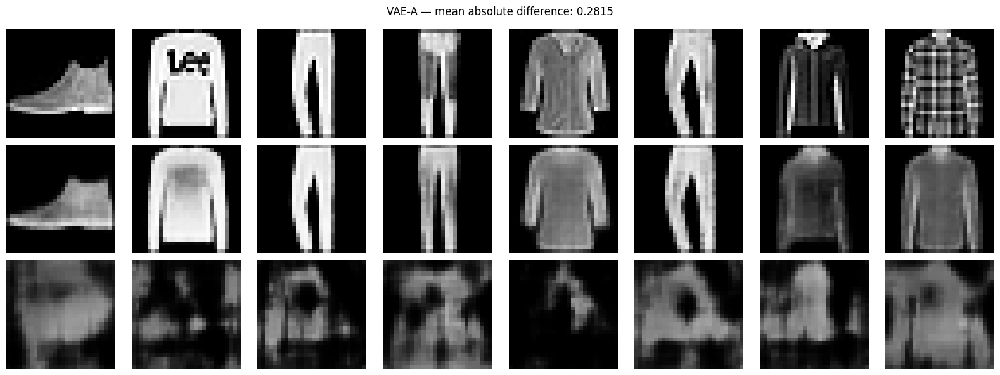

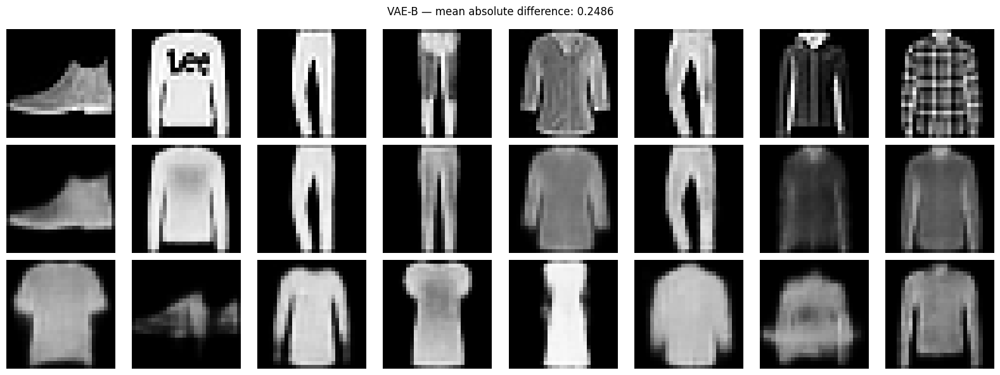

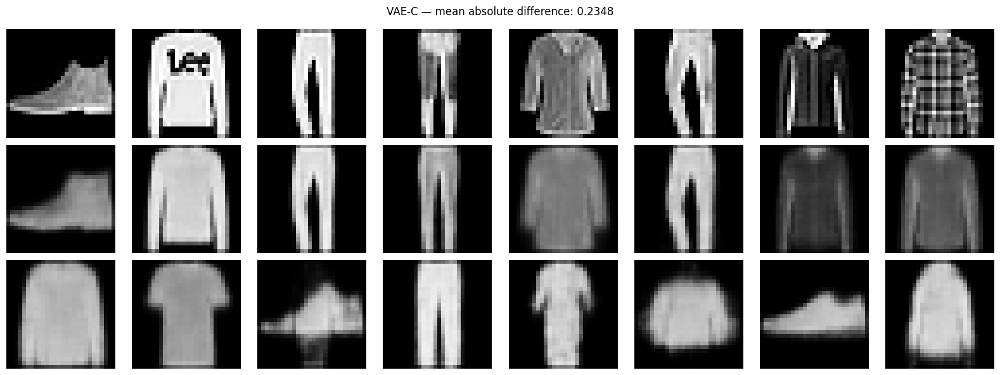

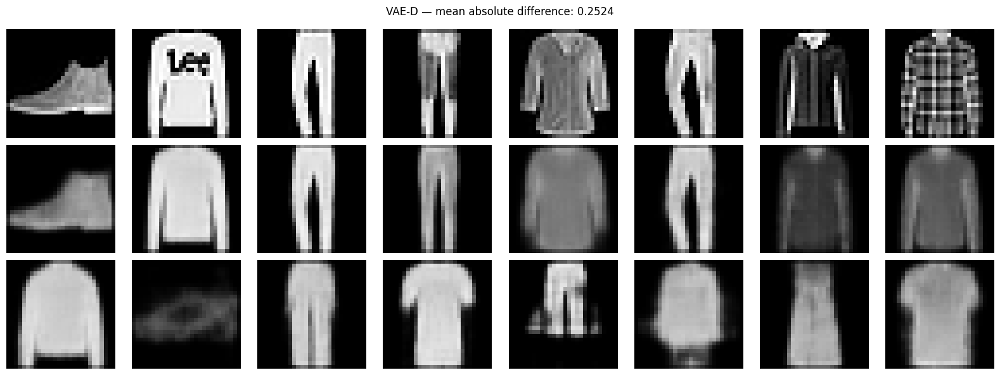

In [68]:
import matplotlib.pyplot as plt

n_show = 8

for name, result in intervention_results.items():
    originals = fixed_test_batch[:n_show].cpu()
    reconstructions = result["x_rec"][:n_show]
    interventions = result["x_int"][:n_show]

    fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))

    rows = [
        (originals, "Original"),
        (reconstructions, "Reconstruction"),
        (interventions, "Prior replacement")
    ]

    for row_idx, (images, row_label) in enumerate(rows):
        for col_idx in range(n_show):
            axes[row_idx, col_idx].imshow(
                images[col_idx, 0].numpy(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[row_idx, col_idx].axis("off")

        axes[row_idx, 0].set_ylabel(row_label, fontsize=10)

    fig.suptitle(
        f"{name} — mean absolute difference: "
        f"{result['mean_abs_diff']:.4f}"
    )
    fig.tight_layout()
    plt.show()

In [69]:
# Problem 3B (ii): ... and after independently permuting the posterior codes across examples.
import torch

@torch.no_grad()
def intervene_shuffle(model, x, seed=1552, mode="whole"):
    """
    Compare posterior-mean reconstructions with shuffled-code outputs.

    Args:
        model: trained VAE model
        x: fixed batch of test images, shape (N, 1, 28, 28)
        seed: seed for reproducible permutations
        mode:
            "whole"      - shuffle complete latent vectors across examples
            "per_dim"    - independently shuffle each latent dimension

    Returns:
        x_rec: reconstructions decoded from the original posterior means
        x_int: outputs decoded from shuffled posterior means
        mean_abs_diff: mean absolute pixel difference (scalar)
    """
    if x.ndim != 4 or x.shape[1:] != (1, 28, 28):
        raise ValueError(
            f"Expected x with shape (N, 1, 28, 28), got {tuple(x.shape)}"
        )

    if x.shape[0] < 64:
        raise ValueError("Use a fixed batch of at least 64 test examples.")

    if mode not in {"whole", "per_dim"}:
        raise ValueError("mode must be 'whole' or 'per_dim'.")

    model.eval()
    device = next(model.parameters()).device
    x = x.to(device)

    # Use posterior means for deterministic reconstructions.
    mu, logvar = model.encode(x)
    x_rec = model.decode(mu)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    if mode == "whole":
        # One permutation is applied to the complete latent vectors.
        permutation = torch.randperm(
            mu.shape[0], generator=generator, device=device
        )
        mu_shuffled = mu[permutation]

    else:  # mode == "per_dim"
        # Each latent dimension receives its own independent permutation.
        mu_shuffled = torch.empty_like(mu)

        for j in range(mu.shape[1]):
            permutation = torch.randperm(
                mu.shape[0], generator=generator, device=device
            )
            mu_shuffled[:, j] = mu[permutation, j]

    x_int = model.decode(mu_shuffled)

    if x_rec.shape != x_int.shape:
        raise RuntimeError("Reconstruction and intervention shapes differ.")

    mean_abs_diff = (x_int - x_rec).abs().mean().item()

    return x_rec, x_int, mean_abs_diff

In [70]:
shuffle_results = {}

for name, model in models.items():
    shuffle_results[name] = {}

    for mode in ["whole", "per_dim"]:
        x_rec, x_int, mean_abs_diff = intervene_shuffle(
            model,
            fixed_test_batch,
            seed=SEED,
            mode=mode
        )

        shuffle_results[name][mode] = {
            "x_rec": x_rec.cpu(),
            "x_int": x_int.cpu(),
            "mean_abs_diff": mean_abs_diff
        }

        print(
            f"{name} | {mode} shuffle | "
            f"mean absolute pixel difference = {mean_abs_diff:.6f}"
        )

VAE-A | whole shuffle | mean absolute pixel difference = 0.254878
VAE-A | per_dim shuffle | mean absolute pixel difference = 0.271160
VAE-B | whole shuffle | mean absolute pixel difference = 0.242830
VAE-B | per_dim shuffle | mean absolute pixel difference = 0.249679
VAE-C | whole shuffle | mean absolute pixel difference = 0.234067
VAE-C | per_dim shuffle | mean absolute pixel difference = 0.248728
VAE-D | whole shuffle | mean absolute pixel difference = 0.234272
VAE-D | per_dim shuffle | mean absolute pixel difference = 0.251666


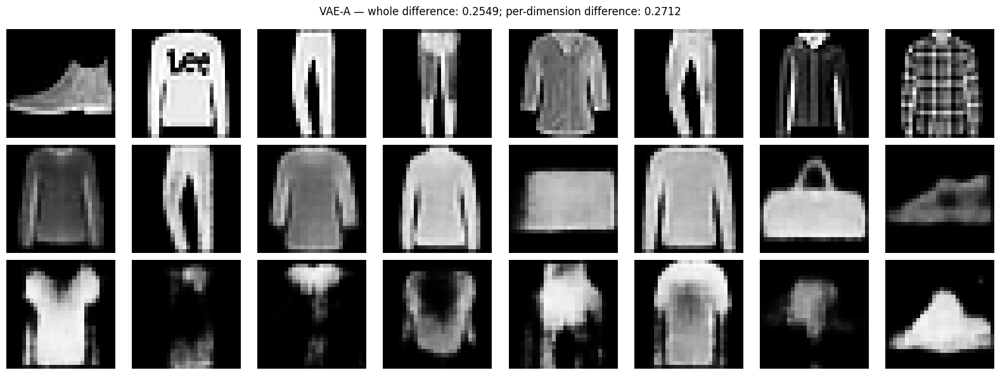

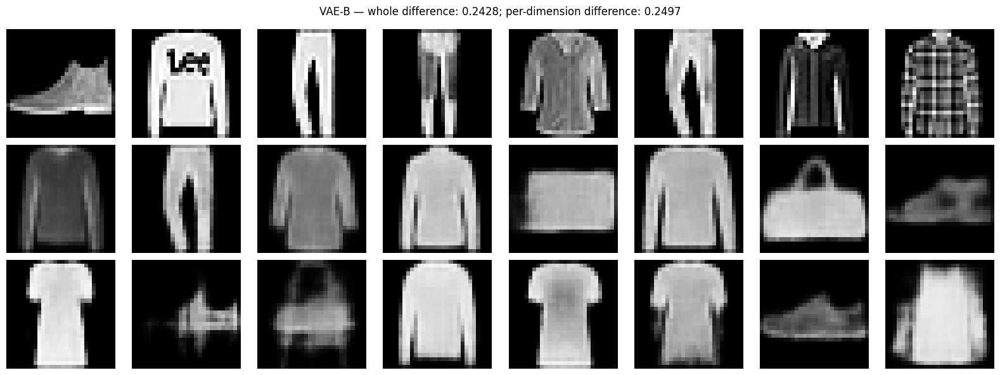

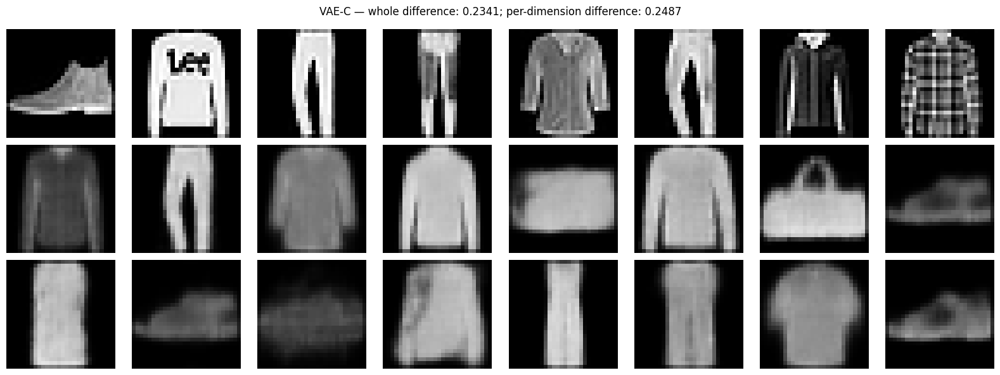

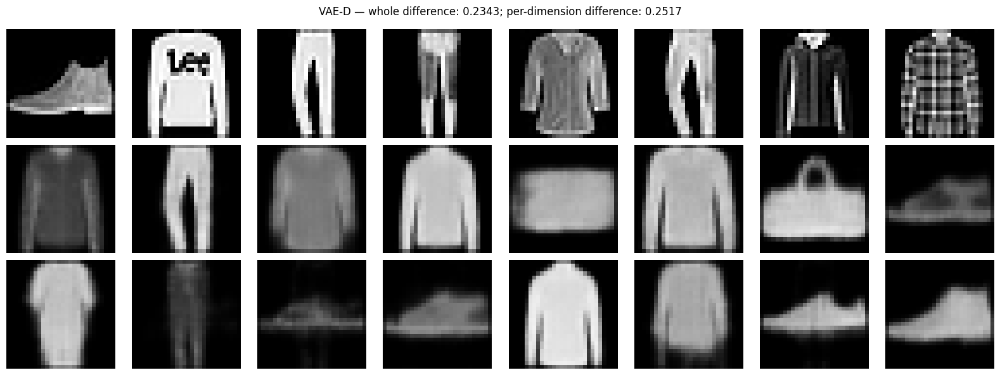

In [71]:
import matplotlib.pyplot as plt

n_show = 8

for name, results in shuffle_results.items():
    fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))

    originals = fixed_test_batch[:n_show].cpu()
    reconstructions = results["whole"]["x_rec"][:n_show]
    whole_outputs = results["whole"]["x_int"][:n_show]
    per_dim_outputs = results["per_dim"]["x_int"][:n_show]

    rows = [
        (originals, "Original"),
        (whole_outputs, "Whole-code shuffle"),
        (per_dim_outputs, "Per-dimension shuffle")
    ]

    for row_idx, (images, row_label) in enumerate(rows):
        for col_idx in range(n_show):
            axes[row_idx, col_idx].imshow(
                images[col_idx, 0].numpy(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[row_idx, col_idx].axis("off")

        axes[row_idx, 0].set_ylabel(row_label, fontsize=9)

    fig.suptitle(
        f"{name} — whole difference: "
        f"{results['whole']['mean_abs_diff']:.4f}; "
        f"per-dimension difference: "
        f"{results['per_dim']['mean_abs_diff']:.4f}"
    )
    fig.tight_layout()
    plt.show()

In [72]:
# Problem 3B (iii): Quantify the mean absolute output change and show representative grids.
# TODO: table of mean |delta| for {replacement, shuffle} x {VAE-A..D}; grids of original / recon / intervened.

In [73]:
# Problem 3B (iii): Summarize mean absolute output changes.

import os
import pandas as pd

rows = []

for name in models.keys():
    rows.append({
        "model": name,
        "intervention": "prior_replacement",
        "mean_abs_change": intervention_results[name]["mean_abs_diff"]
    })

    rows.append({
        "model": name,
        "intervention": "whole_code_shuffle",
        "mean_abs_change": shuffle_results[name]["whole"]["mean_abs_diff"]
    })

    rows.append({
        "model": name,
        "intervention": "per_dimension_shuffle",
        "mean_abs_change": shuffle_results[name]["per_dim"]["mean_abs_diff"]
    })

change_df = pd.DataFrame(rows)

# Display a compact comparison table.
change_table = change_df.pivot(
    index="model",
    columns="intervention",
    values="mean_abs_change"
).reindex(list(models.keys()))

display(change_table.round(6))

# Save the long-form and wide-form tables.
metrics_dir = os.path.join(OUT_DIR, "metrics")
os.makedirs(metrics_dir, exist_ok=True)

change_df.to_csv(
    os.path.join(metrics_dir, "p3b_iii_output_changes_long.csv"),
    index=False
)
change_table.to_csv(
    os.path.join(metrics_dir, "p3b_iii_output_changes.csv")
)

print("Saved output-change tables to:", metrics_dir)

intervention,per_dimension_shuffle,prior_replacement,whole_code_shuffle
model,,,
VAE-A,0.271160,0.281517,0.254878
VAE-B,0.249679,0.248605,0.242830
VAE-C,0.248728,0.234832,0.234067
VAE-D,0.251666,0.252389,0.234272


Saved output-change tables to: outputs/metrics


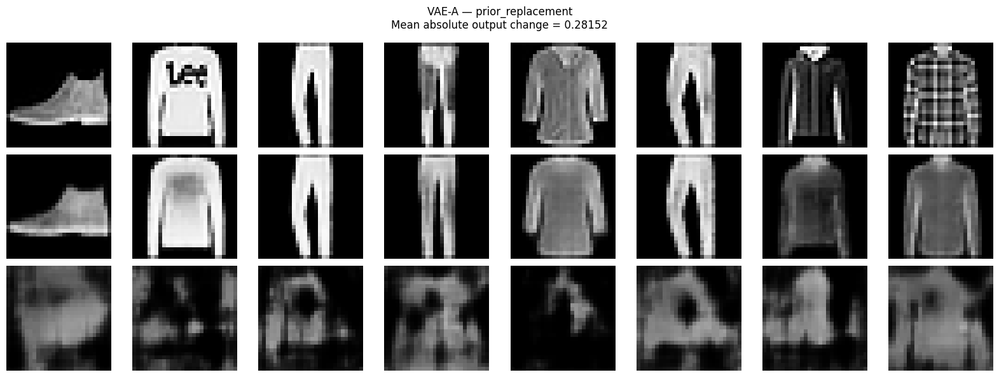

Saved: outputs/figures/p3b_iii_vae_a_prior_replacement.png


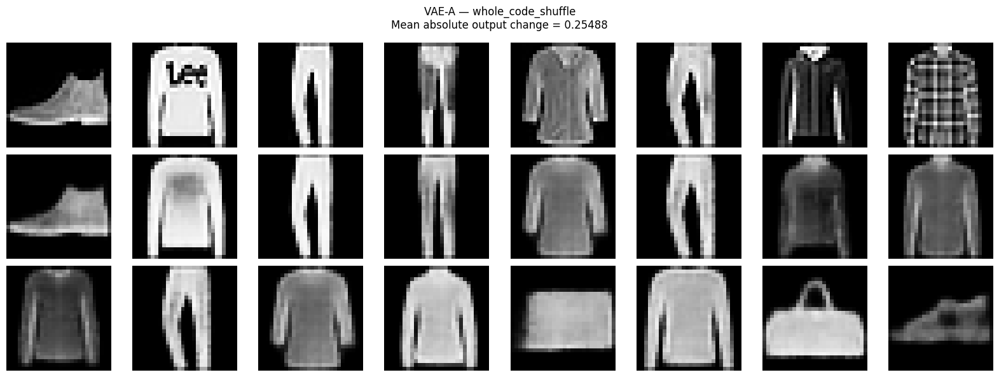

Saved: outputs/figures/p3b_iii_vae_a_whole_code_shuffle.png


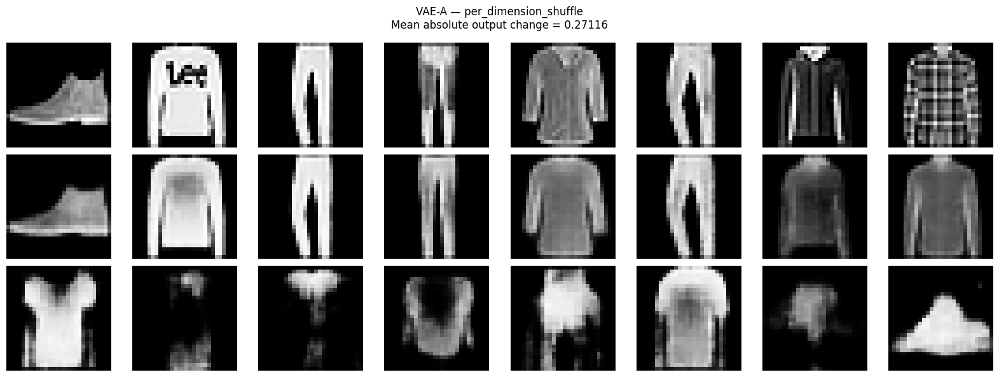

Saved: outputs/figures/p3b_iii_vae_a_per_dimension_shuffle.png


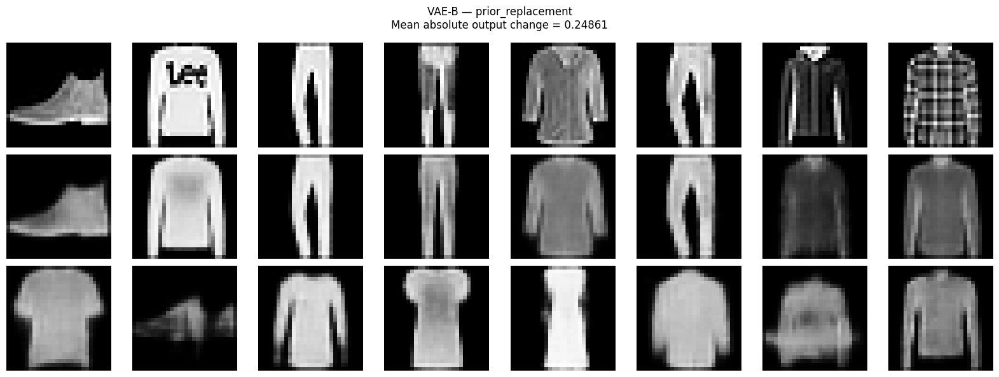

Saved: outputs/figures/p3b_iii_vae_b_prior_replacement.png


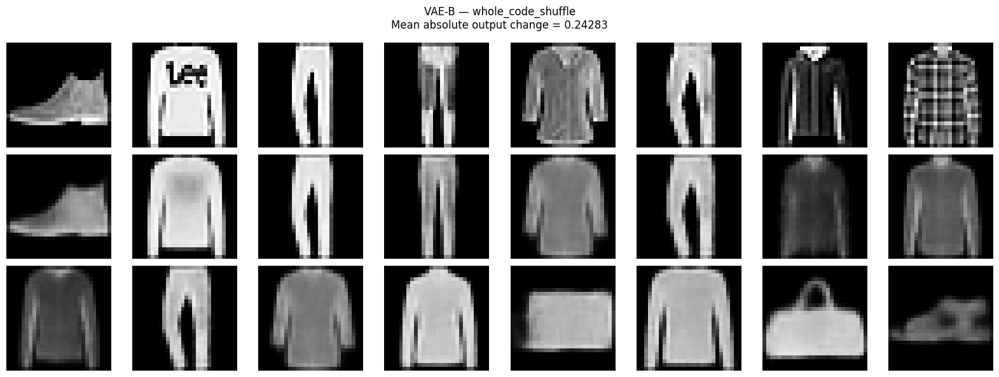

Saved: outputs/figures/p3b_iii_vae_b_whole_code_shuffle.png


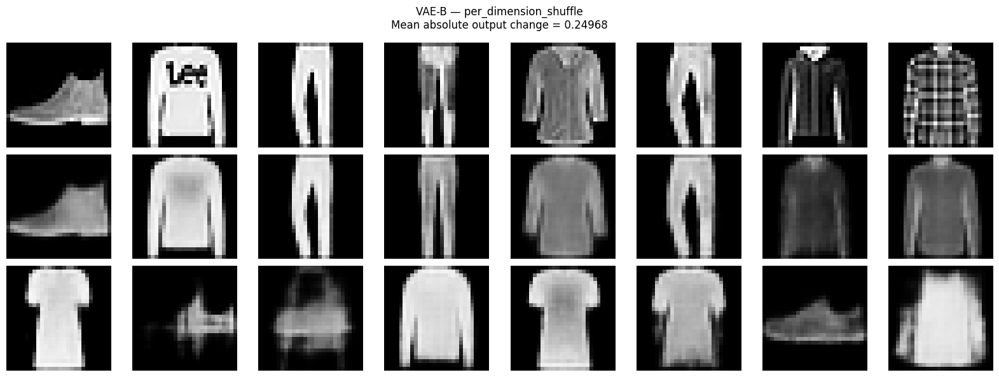

Saved: outputs/figures/p3b_iii_vae_b_per_dimension_shuffle.png


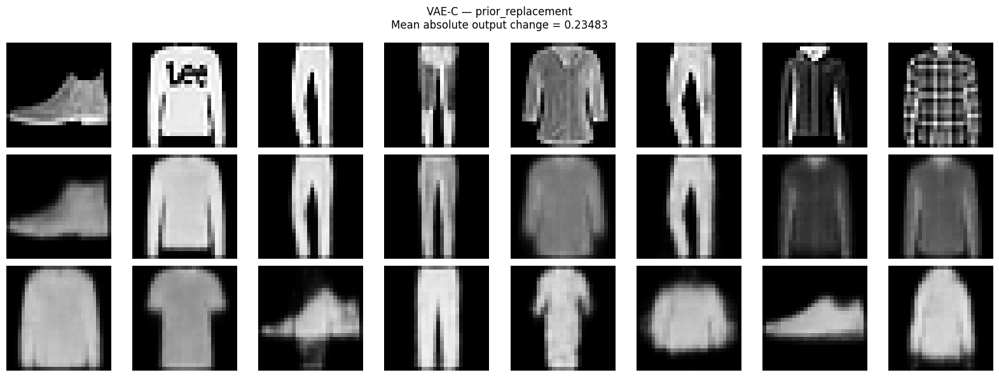

Saved: outputs/figures/p3b_iii_vae_c_prior_replacement.png


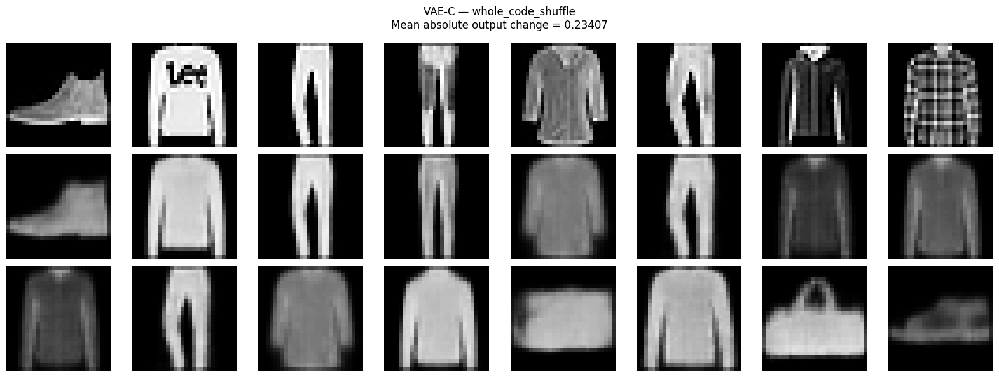

Saved: outputs/figures/p3b_iii_vae_c_whole_code_shuffle.png


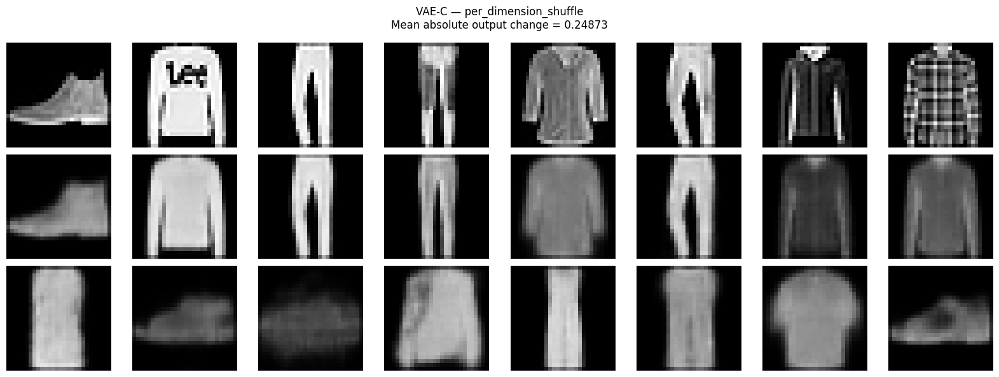

Saved: outputs/figures/p3b_iii_vae_c_per_dimension_shuffle.png


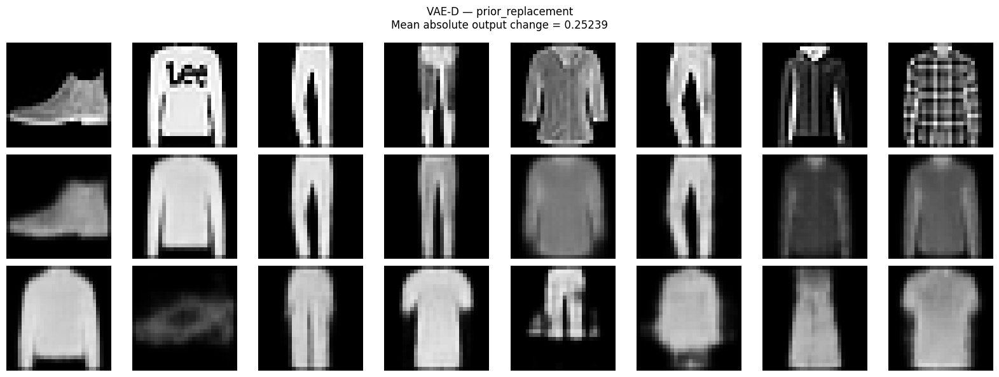

Saved: outputs/figures/p3b_iii_vae_d_prior_replacement.png


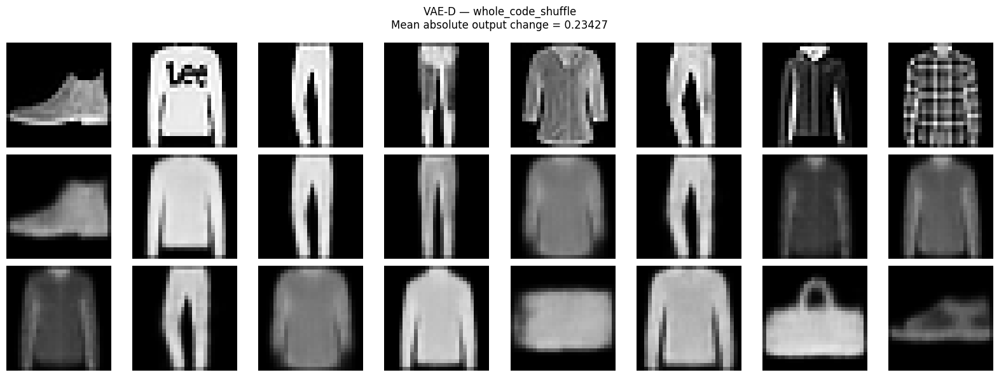

Saved: outputs/figures/p3b_iii_vae_d_whole_code_shuffle.png


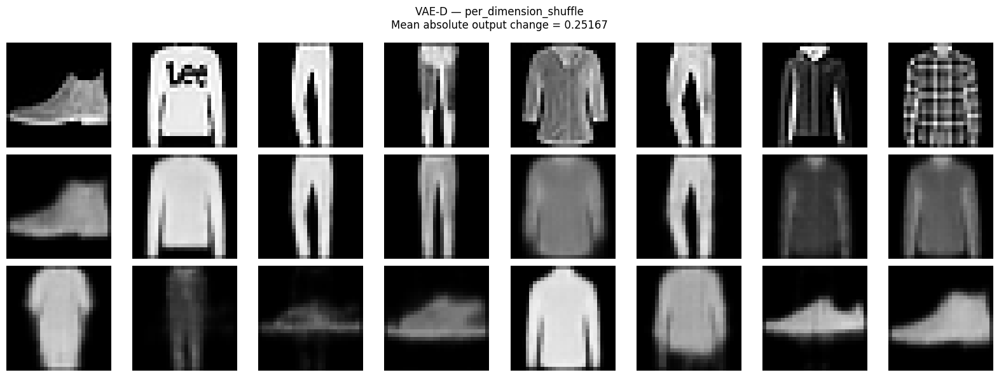

Saved: outputs/figures/p3b_iii_vae_d_per_dimension_shuffle.png


In [74]:
# Save representative grids for each model and intervention.

import matplotlib.pyplot as plt
import os

figures_dir = os.path.join(OUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

N_SHOW = 8

originals = fixed_test_batch[:N_SHOW].cpu()

def save_intervention_grid(
    model_name,
    x_rec,
    x_int,
    intervention_name,
    mean_abs_diff,
    originals
):
    fig, axes = plt.subplots(
        3, N_SHOW,
        figsize=(2 * N_SHOW, 6),
        squeeze=False
    )

    rows = [
        (originals, "Original"),
        (x_rec[:N_SHOW], "Reconstruction"),
        (x_int[:N_SHOW], "Intervened")
    ]

    for row_idx, (images, row_label) in enumerate(rows):
        for col_idx in range(N_SHOW):
            axes[row_idx, col_idx].imshow(
                images[col_idx, 0].numpy(),
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[row_idx, col_idx].axis("off")

        axes[row_idx, 0].set_ylabel(row_label, fontsize=10)

    fig.suptitle(
        f"{model_name} — {intervention_name}\n"
        f"Mean absolute output change = {mean_abs_diff:.5f}"
    )
    fig.tight_layout()

    filename = (
        f"p3b_iii_{model_name.lower().replace('-', '_')}_"
        f"{intervention_name}.png"
    )
    path = os.path.join(figures_dir, filename)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", path)


for name in models.keys():
    # Prior replacement
    result = intervention_results[name]
    save_intervention_grid(
        model_name=name,
        x_rec=result["x_rec"],
        x_int=result["x_int"],
        intervention_name="prior_replacement",
        mean_abs_diff=result["mean_abs_diff"],
        originals=originals
    )

    # Whole-code shuffle
    result = shuffle_results[name]["whole"]
    save_intervention_grid(
        model_name=name,
        x_rec=result["x_rec"],
        x_int=result["x_int"],
        intervention_name="whole_code_shuffle",
        mean_abs_diff=result["mean_abs_diff"],
        originals=originals
    )

    # Per-dimension shuffle
    result = shuffle_results[name]["per_dim"]
    save_intervention_grid(
        model_name=name,
        x_rec=result["x_rec"],
        x_int=result["x_int"],
        intervention_name="per_dimension_shuffle",
        mean_abs_diff=result["mean_abs_diff"],
        originals=originals
    )

In [75]:
# Problem 3B (iv): If the decoder is using z, what should each intervention do? Explain why the interventions
# provide evidence beyond the KL value alone.

**3B (iv) — your answer:**

_TODO: write your answer here._

### 3C. Does KL warm-up help? (10 pts)

In [76]:
# Problem 3C — PREDICTION: will VAE-D use more latent dimensions than VAE-C? At what reconstruction cost?

**3C prediction — your answer:**

_TODO: write your answer here._

In [77]:
# Problem 3C (i): Compare VAE-C with VAE-D. Determine whether warm-up improves latent utilization without
# unacceptable reconstruction degradation. Base your conclusion on active units, per-dimension KL,
# latent-intervention sensitivity, reconstruction, and prior samples — not on one metric alone.
import os
import numpy as np
import pandas as pd

def evidence_table_c_vs_d():
    """
    Assemble quantitative and qualitative evidence comparing VAE-C and VAE-D.
    Rows are evidence types; columns are the two models.
    """

    models_to_compare = ["VAE-C", "VAE-D"]

    # --- 3A: Per-dimension KL, KL sum, active dimensions, mean variance ---
    latent_metrics = p3a_table.set_index("model")

    # --- 3B: Mean absolute output change ---
    # change_table has models as rows and intervention types as columns.
    intervention_metrics = change_table

    # --- 2A: Final reconstruction and KL metrics ---
    final_history = {}
    for name in models_to_compare:
        records = histories[name]
        final_history[name] = records[-1]

    # Build an evidence dictionary for each model.
    evidence = {}

    for name in models_to_compare:
        latent_row = latent_metrics.loc[name]
        history_row = final_history[name]

        # Per-dimension KL vector
        kl_values = np.array([
            latent_row[f"KL_{j}"] for j in range(LATENT_DIM)
        ], dtype=float)

        # Per-dimension posterior mean variance
        mu_variances = np.array([
            latent_row[f"Var(mu_{j})"] for j in range(LATENT_DIM)
        ], dtype=float)

        # Active dimensions: reuse the existing table result
        active_units = int(latent_row["active_dimensions"])

        # Intervention sensitivities from Problem 3B
        prior_change = float(
            intervention_metrics.loc[name, "prior_replacement"]
        )
        whole_shuffle_change = float(
            intervention_metrics.loc[name, "whole_code_shuffle"]
        )
        per_dim_shuffle_change = float(
            intervention_metrics.loc[name, "per_dimension_shuffle"]
        )

        evidence[name] = {
            "Final test reconstruction loss (lower is better)":
                float(history_row["test_recon"]),
            "Final test KL (total)":
                float(history_row["test_kl"]),
            "Active latent dimensions":
                f"{active_units}/{LATENT_DIM}",
            "Per-dimension KL values":
                np.array2string(kl_values, precision=4, separator=", "),
            "Sum of per-dimension KL":
                float(kl_values.sum()),
            "Dimensions with Var(mu_j) > 0.01":
                int(np.sum(mu_variances > 0.01)),
            "Per-dimension Var(mu_j)":
                np.array2string(mu_variances, precision=4, separator=", "),
            "Mean |output change|: prior replacement":
                prior_change,
            "Mean |output change|: whole-code shuffle":
                whole_shuffle_change,
            "Mean |output change|: per-dimension shuffle":
                per_dim_shuffle_change,
            "Reconstruction visual inspection":
                "Inspect saved 2A reconstruction grids",
            "Prior-sample visual inspection":
                "Inspect saved 2A fixed-prior sample grids",
        }

    table = pd.DataFrame(evidence)

    # Display all rows without truncating the per-dimension arrays.
    display(table)

    # Save a copy for your report.
    metrics_dir = os.path.join(OUT_DIR, "metrics")
    os.makedirs(metrics_dir, exist_ok=True)

    save_path = os.path.join(metrics_dir, "p3c_i_vae_c_vs_d_evidence.csv")
    table.to_csv(save_path, index_label="Evidence type")

    print(f"Saved evidence table to: {save_path}")

    return table


c_vs_d_evidence = evidence_table_c_vs_d()

,VAE-C,VAE-D
Final test reconstruction loss (lower is better),242.000559,243.037647
Final test KL (total),7.255802,7.245607
Active latent dimensions,8/16,12/16
Per-dimension KL values,"[7.7903e-03, 1.8432e+00, 1.5469e-03, 9.6652e-0...","[0.6099, 1.4092, 1.2244, 0.1549, 0.1345, 0.543..."
Sum of per-dimension KL,7.255798,7.245609
Dimensions with Var(mu_j) > 0.01,10,13
Per-dimension Var(mu_j),"[0.0149, 1.0346, 0.0026, 0.8169, 0.6663, 0.003...","[0.5816, 0.9444, 0.943 , 0.227 , 0.1946, 0.513..."
Mean |output change|: prior replacement,0.234832,0.252389
Mean |output change|: whole-code shuffle,0.234067,0.234272
Mean |output change|: per-dimension shuffle,0.248728,0.251666


Saved evidence table to: outputs/metrics/p3c_i_vae_c_vs_d_evidence.csv


In [78]:
# Problem 3C (ii): Complete collapse is not guaranteed with this decoder. If no model collapses completely,
# identify the configuration showing the strongest movement toward collapse and justify the claim.

**3C (ii) — your answer:**

_TODO: write your answer here._

## Problem 4: Evaluating Latent-Space Usefulness (20 pts)

### 4A. A multi-criterion comparison (10 pts)

In [79]:
# Problem 4A (i): Create a single table comparing VAE-A through VAE-D on:
#   reconstruction quality; prior-sample plausibility and diversity; aggregate-posterior compatibility with
#   the prior; number of active dimensions; sensitivity to latent replacement and shuffling; and
#   interpolation/traversal behavior.

    # TODO: assemble from earlier results. Suggested quantitative proxies:
    #   - recon: final test BCE
    #   - aggregate posterior vs prior: mean/cov of mu (or of sampled z) vs N(0, I), e.g. Gaussian KL of moments
    #   - sample diversity: mean pairwise pixel distance among the 64 fixed-prior samples
    #   - active dims and intervention MAEs from Problem 3
    #   - interpolation/traversal: qualitative label referencing the figure


In [80]:

# ============================================================
# Problem 4A(i): Comparison table for VAE-A through VAE-D
#
# Uses existing results from earlier assignment sections:
#   models, histories, encoded, OUT_DIR, LATENT_DIM
#   intervention_results, shuffle_results
#
# Produces:
#   OUT_DIR/metrics/p4a_i_vae_comparison.csv
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from itertools import combinations

os.makedirs(os.path.join(OUT_DIR, "metrics"), exist_ok=True)

MODEL_NAMES = ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]
ACTIVE_THRESHOLD = 0.01


# ------------------------------------------------------------
# 1. Helpers for aggregate-posterior and active dimensions
# ------------------------------------------------------------

def gaussian_moment_kl(mu, eps=1e-6):
    """
    KL[N(mean(mu), cov(mu)) || N(0, I)].

    Uses the Gaussian matching the empirical mean and covariance
    of posterior means. This is a moment-based approximation to
    aggregate-posterior compatibility, not the exact aggregate KL.
    """
    mu = np.asarray(mu, dtype=np.float64)

    if mu.ndim != 2 or mu.shape[0] < 2:
        raise ValueError("mu must have shape [N, latent_dim], N >= 2.")

    n, d = mu.shape
    mean = mu.mean(axis=0)
    cov = np.cov(mu, rowvar=False, ddof=1)
    cov = np.atleast_2d(cov)

    # Stabilize the covariance matrix for the log determinant.
    cov_reg = cov + eps * np.eye(d)
    sign, logdet = np.linalg.slogdet(cov_reg)

    if sign <= 0:
        raise ValueError("Regularized covariance is not positive definite.")

    trace_cov = np.trace(cov_reg)
    mean_term = mean @ mean

    kl = 0.5 * (trace_cov + mean_term - d - logdet)
    return float(max(kl, 0.0))


def active_dimension_metrics(mu, logvar, threshold=ACTIVE_THRESHOLD):
    """
    KL_j = average over examples of the per-example KL contribution
    for latent dimension j.
    """
    mu = np.asarray(mu)
    logvar = np.asarray(logvar)

    if mu.shape != logvar.shape:
        raise ValueError("mu and logvar shapes do not match.")

    kl_j = 0.5 * np.mean(
        mu**2 + np.exp(logvar) - logvar - 1.0,
        axis=0,
    )

    active = int(np.sum(kl_j > threshold))
    return active, kl_j


# ------------------------------------------------------------
# 2. Prior samples and pairwise pixel diversity
# ------------------------------------------------------------

def get_fixed_prior_codes():
    if "FIXED_PRIOR_Z" in globals():
        z = FIXED_PRIOR_Z
    else:
        code_path = os.path.join(OUT_DIR, "fixed_prior_codes.pt")
        if not os.path.exists(code_path):
            raise FileNotFoundError(
                "Could not find FIXED_PRIOR_Z or "
                f"{code_path}. Run the fixed-prior-code cell first."
            )
        try:
            z = torch.load(
                code_path, map_location="cpu", weights_only=True
            )
        except TypeError:
            z = torch.load(code_path, map_location="cpu")

    if not torch.is_tensor(z):
        z = torch.as_tensor(z)

    if z.ndim != 2 or z.shape[1] != LATENT_DIM:
        raise ValueError(
            f"Expected prior codes shaped [N, {LATENT_DIM}], "
            f"got {tuple(z.shape)}."
        )

    return z


def generate_fixed_prior_images(model, z):
    """Decode the same fixed prior codes for each model."""
    model.eval()
    device = next(model.parameters()).device

    with torch.no_grad():
        images = model.decode(z.to(device))

    return images.detach().cpu()


def mean_pairwise_pixel_distance(images):
    images = torch.as_tensor(images).float()

    if images.shape[0] < 2:
        return float("nan")

    flat = images.reshape(images.shape[0], -1)
    n = flat.shape[0]

    # Pairwise mean absolute pixel distance; diagonal is excluded.
    total = 0.0
    pair_count = 0

    for i in range(n - 1):
        distances = torch.abs(flat[i + 1:] - flat[i]).mean(dim=1)
        total += distances.sum().item()
        pair_count += distances.numel()

    return total / pair_count


# ------------------------------------------------------------
# 3. Pull intervention metrics from Problem 3B
# ------------------------------------------------------------

def get_intervention_mae(results, model_name, mode=None):
    """
    Supports:
      intervention_results[model]["mean_abs_diff"]
      shuffle_results[model]["whole"]["mean_abs_diff"]
      shuffle_results[model]["per_dim"]["mean_abs_diff"]
    """
    if results is None or model_name not in results:
        return np.nan

    result = results[model_name]

    if mode is not None:
        if mode not in result:
            return np.nan
        result = result[mode]

    if isinstance(result, dict):
        value = result.get("mean_abs_diff", np.nan)
        try:
            return float(value)
        except (TypeError, ValueError):
            return np.nan

    return np.nan


# ------------------------------------------------------------
# 4. Build the comparison table
# ------------------------------------------------------------

def comparison_table():
    rows = []
    fixed_z = get_fixed_prior_codes()

    for name in MODEL_NAMES:
        if name not in models:
            print(f"Warning: {name} not found in models; skipping.")
            continue

        if name not in histories or not histories[name]:
            print(f"Warning: no history for {name}; skipping.")
            continue

        if name not in encoded:
            print(f"Warning: no encoded test data for {name}; skipping.")
            continue

        # Final test reconstruction BCE, summed over pixels
        # and averaged over examples as stored in histories.
        final_record = histories[name][-1]
        final_test_recon = float(final_record["test_recon"])

        # Encoded test-set posterior statistics.
        mu, logvar, labels = encoded[name]
        mu = np.asarray(mu)
        logvar = np.asarray(logvar)

        agg_kl = gaussian_moment_kl(mu)
        mu_mean_norm = float(np.linalg.norm(mu.mean(axis=0)))
        mu_variance_mean = float(np.var(mu, axis=0).mean())

        active_count, kl_per_dim = active_dimension_metrics(
            mu, logvar, threshold=ACTIVE_THRESHOLD
        )

        # Generate exactly the same fixed prior codes for every model.
        prior_images = generate_fixed_prior_images(models[name], fixed_z)
        prior_diversity = mean_pairwise_pixel_distance(prior_images)

        # Intervention sensitivities from Problem 3B.
        prior_replacement_mae = get_intervention_mae(
            intervention_results, name
        )

        whole_shuffle_mae = get_intervention_mae(
            shuffle_results, name, mode="whole"
        )

        # Earlier code used "per_dim"; support "per_dimension" too.
        per_dim_shuffle_mae = get_intervention_mae(
            shuffle_results, name, mode="per_dim"
        )
        if np.isnan(per_dim_shuffle_mae):
            per_dim_shuffle_mae = get_intervention_mae(
                shuffle_results, name, mode="per_dimension"
            )

        # Figure references from earlier assignment cells.
        interpolation_figure = os.path.join(
            OUT_DIR, "figures", f"p2c_i_{name}_interpolation.png"
        )

        if name == "VAE-B":
            traversal_figure = os.path.join(
                OUT_DIR, "figures", "p2c_ii_vae_b_dim_*_traversal.png"
            )
            traversal_note = (
                "See VAE-B traversal figures for the three "
                "highest-variance posterior-mean dimensions."
            )
        else:
            traversal_figure = "Not evaluated (VAE-B only)"
            traversal_note = "Traversal experiment performed on VAE-B only."

        prior_grid_figure = os.path.join(
            OUT_DIR, "figures", f"p2a_ii_{name}_prior_samples.png"
        )

        rows.append({
            "model": name,

            # Reconstruction quality
            "final_test_BCE_per_example": final_test_recon,

            # Prior-sample plausibility and diversity
            "prior_sample_pairwise_pixel_MAE": prior_diversity,
            "prior_sample_grid_reference": prior_grid_figure,
            "prior_sample_plausibility_assessment":
                "Inspect the saved prior-sample grid; qualitative judgment.",

            # Aggregate posterior vs N(0,I), moment-based proxy
            "aggregate_posterior_moment_Gaussian_KL": agg_kl,
            "norm_of_mean_posterior_mu": mu_mean_norm,
            "mean_variance_of_posterior_mu": mu_variance_mean,

            # Latent usage
            "active_dimensions_KL_gt_0.01": active_count,
            "active_dimension_threshold": ACTIVE_THRESHOLD,
            "sum_per_dimension_KL": float(kl_per_dim.sum()),

            # Problem 3B intervention sensitivity
            "prior_replacement_MAE": prior_replacement_mae,
            "whole_code_shuffle_MAE": whole_shuffle_mae,
            "per_dimension_shuffle_MAE": per_dim_shuffle_mae,

            # Problem 2C behavior
            "interpolation_figure": interpolation_figure,
            "interpolation_behavior_assessment":
                "Inspect interpolation figure for smoothness and semantic change.",
            "traversal_figure_reference": traversal_figure,
            "traversal_behavior_assessment": traversal_note,
        })

    df = pd.DataFrame(rows)

    output_path = os.path.join(
        OUT_DIR, "metrics", "p4a_i_vae_comparison.csv"
    )
    df.to_csv(output_path, index=False)

    print(f"Saved comparison table to: {output_path}")
    return df


# Run and display the table
p4a_comparison_df = comparison_table()
display(p4a_comparison_df)


Saved comparison table to: outputs/metrics/p4a_i_vae_comparison.csv


,model,final_test_BCE_per_example,prior_sample_pairwise_pixel_MAE,prior_sample_grid_reference,prior_sample_plausibility_assessment,aggregate_posterior_moment_Gaussian_KL,norm_of_mean_posterior_mu,mean_variance_of_posterior_mu,active_dimensions_KL_gt_0.01,active_dimension_threshold,sum_per_dimension_KL,prior_replacement_MAE,whole_code_shuffle_MAE,per_dimension_shuffle_MAE,interpolation_figure,interpolation_behavior_assessment,traversal_figure_reference,traversal_behavior_assessment
0,VAE-A,213.486009,0.161545,outputs/figures/p2a_ii_VAE-A_prior_samples.png,Inspect the saved prior-sample grid; qualitati...,131.232856,8.925095,14.271289,16,0.01,292.354919,0.281517,0.254878,0.271160,outputs/figures/p2c_i_VAE-A_interpolation.png,Inspect interpolation figure for smoothness an...,Not evaluated (VAE-B only),Traversal experiment performed on VAE-B only.
1,VAE-B,223.901563,0.223879,outputs/figures/p2a_ii_VAE-B_prior_samples.png,Inspect the saved prior-sample grid; qualitati...,0.886043,0.169954,0.757658,16,0.01,16.811977,0.248605,0.242830,0.249679,outputs/figures/p2c_i_VAE-B_interpolation.png,Inspect interpolation figure for smoothness an...,outputs/figures/p2c_ii_vae_b_dim_*_traversal.png,See VAE-B traversal figures for the three high...
2,VAE-C,242.000559,0.225965,outputs/figures/p2a_ii_VAE-C_prior_samples.png,Inspect the saved prior-sample grid; qualitati...,20.895954,0.084470,0.345090,8,0.01,7.255798,0.234832,0.234067,0.248728,outputs/figures/p2c_i_VAE-C_interpolation.png,Inspect interpolation figure for smoothness an...,Not evaluated (VAE-B only),Traversal experiment performed on VAE-B only.
3,VAE-D,243.037647,0.228066,outputs/figures/p2a_ii_VAE-D_prior_samples.png,Inspect the saved prior-sample grid; qualitati...,11.829222,0.083733,0.377830,12,0.01,7.245609,0.252389,0.234272,0.251666,outputs/figures/p2c_i_VAE-D_interpolation.png,Inspect interpolation figure for smoothness an...,Not evaluated (VAE-B only),Traversal experiment performed on VAE-B only.


In [81]:
# Problem 4A (ii): Select the most useful model for (i) compression and reconstruction, and
# (ii) generation from the prior. The same model need not win both. Define the evidence used for each selection.

In [82]:

# ============================================================
# Problem 4A(ii): Select models for reconstruction and generation
#
# Uses previously computed:
#   p4a_comparison_df, histories, encoded, models, OUT_DIR
#
# Outputs:
#   OUT_DIR/metrics/p4a_ii_model_selection.csv
#   OUT_DIR/metrics/p4a_ii_model_selection_summary.txt
# ============================================================

import os
import numpy as np
import pandas as pd

os.makedirs(os.path.join(OUT_DIR, "metrics"), exist_ok=True)

# ------------------------------------------------------------
# 1. Check that the previous comparison table is available
# ------------------------------------------------------------

if "p4a_comparison_df" not in globals() or p4a_comparison_df.empty:
    raise ValueError(
        "p4a_comparison_df is missing or empty. "
        "Run the Problem 4A(i) comparison_table() cell first."
    )

df = p4a_comparison_df.copy()

required_columns = [
    "model",
    "final_test_BCE_per_example",
    "aggregate_posterior_moment_Gaussian_KL",
    "prior_sample_pairwise_pixel_MAE",
    "active_dimensions_KL_gt_0.01",
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in comparison table: {missing}")


# ------------------------------------------------------------
# 2. Add compression/reconstruction evidence
# ------------------------------------------------------------

# Reconstruction loss is the primary quantitative metric.
# Latent activity and intervention MAE are supporting metrics.
df["compression_reconstruction_score"] = np.nan

def minmax_score(series, higher_is_better=True):
    """
    Scale a numeric series to [0, 1].
    Constant-valued series receive 0.5 for all non-missing entries.
    """
    values = pd.to_numeric(series, errors="coerce")
    valid = values.dropna()

    result = pd.Series(np.nan, index=series.index, dtype=float)

    if len(valid) == 0:
        return result

    low, high = valid.min(), valid.max()

    if np.isclose(low, high):
        result.loc[valid.index] = 0.5
    else:
        score = (values.loc[valid.index] - low) / (high - low)
        result.loc[valid.index] = score if higher_is_better else 1 - score

    return result


# Lower reconstruction BCE is better.
df["reconstruction_score"] = minmax_score(
    df["final_test_BCE_per_example"],
    higher_is_better=False,
)

# More active dimensions can indicate more useful latent capacity,
# but is not by itself proof of better compression.
df["active_dimension_score"] = minmax_score(
    df["active_dimensions_KL_gt_0.01"],
    higher_is_better=True,
)

# Higher intervention MAE means the decoder responds more to latent
# codes. Use available intervention columns and average their scores.
intervention_columns = [
    "prior_replacement_MAE",
    "whole_code_shuffle_MAE",
    "per_dimension_shuffle_MAE",
]
available_interventions = [
    c for c in intervention_columns if c in df.columns
]

if available_interventions:
    intervention_scores = pd.concat(
        [
            minmax_score(df[c], higher_is_better=True).rename(c)
            for c in available_interventions
        ],
        axis=1,
    )
    df["latent_sensitivity_score"] = intervention_scores.mean(
        axis=1, skipna=True
    )
else:
    df["latent_sensitivity_score"] = np.nan

# Reconstruction is weighted most heavily.
# Missing supporting metrics are omitted from each model's denominator.
compression_components = {
    "reconstruction_score": 0.70,
    "active_dimension_score": 0.15,
    "latent_sensitivity_score": 0.15,
}

weighted_sum = pd.Series(0.0, index=df.index)
weight_sum = pd.Series(0.0, index=df.index)

for column, weight in compression_components.items():
    valid = df[column].notna()
    weighted_sum.loc[valid] += df.loc[valid, column] * weight
    weight_sum.loc[valid] += weight

df["compression_reconstruction_score"] = (
    weighted_sum / weight_sum.replace(0, np.nan)
)


# ------------------------------------------------------------
# 3. Add prior-generation evidence
# ------------------------------------------------------------

# Lower moment-based Gaussian KL is better for prior compatibility.
df["prior_compatibility_score"] = minmax_score(
    df["aggregate_posterior_moment_Gaussian_KL"],
    higher_is_better=False,
)

# Greater diversity is a useful signal, but excessive diversity can
# also come from noisy or implausible images.
df["prior_diversity_score"] = minmax_score(
    df["prior_sample_pairwise_pixel_MAE"],
    higher_is_better=True,
)

# Combine quantitative signals, prioritizing compatibility.
# The visual plausibility assessment is not assigned a numeric score
# because it requires inspecting the actual generated images.
generation_components = {
    "prior_compatibility_score": 0.70,
    "prior_diversity_score": 0.30,
}

weighted_sum = pd.Series(0.0, index=df.index)
weight_sum = pd.Series(0.0, index=df.index)

for column, weight in generation_components.items():
    valid = df[column].notna()
    weighted_sum.loc[valid] += df.loc[valid, column] * weight
    weight_sum.loc[valid] += weight

df["prior_generation_score"] = (
    weighted_sum / weight_sum.replace(0, np.nan)
)


# ------------------------------------------------------------
# 4. Select winners based on the defined scores
# ------------------------------------------------------------

eligible_compression = df.dropna(
    subset=["compression_reconstruction_score"]
)
eligible_generation = df.dropna(
    subset=["prior_generation_score"]
)

if eligible_compression.empty or eligible_generation.empty:
    raise ValueError(
        "Not enough valid metric values to select models. "
        "Check the comparison table for missing values."
    )

compression_winner = eligible_compression.loc[
    eligible_compression["compression_reconstruction_score"].idxmax()
]

generation_winner = eligible_generation.loc[
    eligible_generation["prior_generation_score"].idxmax()
]

df["compression_rank"] = df[
    "compression_reconstruction_score"
].rank(ascending=False, method="min")

df["prior_generation_rank"] = df[
    "prior_generation_score"
].rank(ascending=False, method="min")

df["selected_for_compression_reconstruction"] = (
    df["model"] == compression_winner["model"]
)
df["selected_for_prior_generation"] = (
    df["model"] == generation_winner["model"]
)


# ------------------------------------------------------------
# 5. Save ranking table and a report-ready summary
# ------------------------------------------------------------

output_csv = os.path.join(
    OUT_DIR, "metrics", "p4a_ii_model_selection.csv"
)
df.to_csv(output_csv, index=False)

compression_evidence = (
    f"{compression_winner['model']} selected for compression and "
    f"reconstruction. Its composite score is "
    f"{compression_winner['compression_reconstruction_score']:.3f}; "
    f"final test BCE is "
    f"{compression_winner['final_test_BCE_per_example']:.4f}, "
    f"with "
    f"{int(compression_winner['active_dimensions_KL_gt_0.01'])} "
    f"active dimensions."
)

generation_evidence = (
    f"{generation_winner['model']} selected for prior generation. "
    f"Its composite score is "
    f"{generation_winner['prior_generation_score']:.3f}; "
    f"moment-based aggregate-posterior KL is "
    f"{generation_winner['aggregate_posterior_moment_Gaussian_KL']:.4f}, "
    f"and fixed-prior sample pairwise pixel MAE is "
    f"{generation_winner['prior_sample_pairwise_pixel_MAE']:.4f}."
)

summary = f"""
Problem 4A(ii): Model selection

Metrics and selection rules
---------------------------
Compression/reconstruction:
- 70% normalized reconstruction score (lower test BCE is better)
- 15% normalized active-dimension score (more active dimensions is better)
- 15% normalized latent-sensitivity score (larger intervention MAE is better)

Prior generation:
- 70% normalized prior-compatibility score (lower moment-based Gaussian KL is better)
- 30% normalized sample-diversity score (larger pairwise pixel MAE is better)

Scores are normalized to [0, 1] across the models in this comparison.
If a metric is missing, available components are reweighted proportionally.

Selected model for compression/reconstruction:
{compression_evidence}

Selected model for prior generation:
{generation_evidence}

Just based on some written metrics
"""

output_txt = os.path.join(
    OUT_DIR, "metrics", "p4a_ii_model_selection_summary.txt"
)

with open(output_txt, "w", encoding="utf-8") as f:
    f.write(summary.strip() + "\n")

print(summary)
print(f"Saved ranking table: {output_csv}")
print(f"Saved report summary: {output_txt}")

display(
    df[
        [
            "model",
            "final_test_BCE_per_example",
            "active_dimensions_KL_gt_0.01",
            "compression_reconstruction_score",
            "aggregate_posterior_moment_Gaussian_KL",
            "prior_sample_pairwise_pixel_MAE",
            "prior_generation_score",
            "compression_rank",
            "prior_generation_rank",
            "selected_for_compression_reconstruction",
            "selected_for_prior_generation",
        ]
    ].sort_values("compression_rank").round(4)
)



Problem 4A(ii): Model selection

Metrics and selection rules
---------------------------
Compression/reconstruction:
- 70% normalized reconstruction score (lower test BCE is better)
- 15% normalized active-dimension score (more active dimensions is better)
- 15% normalized latent-sensitivity score (larger intervention MAE is better)

Prior generation:
- 70% normalized prior-compatibility score (lower moment-based Gaussian KL is better)
- 30% normalized sample-diversity score (larger pairwise pixel MAE is better)

Scores are normalized to [0, 1] across the models in this comparison.
If a metric is missing, available components are reweighted proportionally.

Selected model for compression/reconstruction:
VAE-A selected for compression and reconstruction. Its composite score is 1.000; final test BCE is 213.4860, with 16 active dimensions.

Selected model for prior generation:
VAE-B selected for prior generation. Its composite score is 0.981; moment-based aggregate-posterior KL is 0.8860

,model,final_test_BCE_per_example,active_dimensions_KL_gt_0.01,compression_reconstruction_score,aggregate_posterior_moment_Gaussian_KL,prior_sample_pairwise_pixel_MAE,prior_generation_score,compression_rank,prior_generation_rank,selected_for_compression_reconstruction,selected_for_prior_generation
0,VAE-A,213.4860,16,1.0000,131.2329,0.1615,0.0000,1.0,4.0,True,False
1,VAE-B,223.9016,16,0.6412,0.8860,0.2239,0.9811,2.0,1.0,False,True
3,VAE-D,243.0376,12,0.1008,11.8292,0.2281,0.9412,3.0,2.0,False,False
2,VAE-C,242.0006,8,0.0246,20.8960,0.2260,0.8831,4.0,3.0,False,False


**4A (ii) — your answer:**

_TODO: write your answer here._

### 4B. Final technical interpretation (10 pts)

In [83]:
# Problem 4B Q1: Which configuration uses z most strongly, and how do you know?
# Answer in a short, evidence-based paragraph tied to specific figures or metrics.

,model,Prior replacement MAE,Whole-code shuffle MAE,Per-dimension shuffle MAE,Active dimensions
0,VAE-A,0.2815,0.2549,0.2712,16
1,VAE-B,0.2486,0.2428,0.2497,16
2,VAE-C,0.2348,0.2341,0.2487,8
3,VAE-D,0.2524,0.2343,0.2517,12


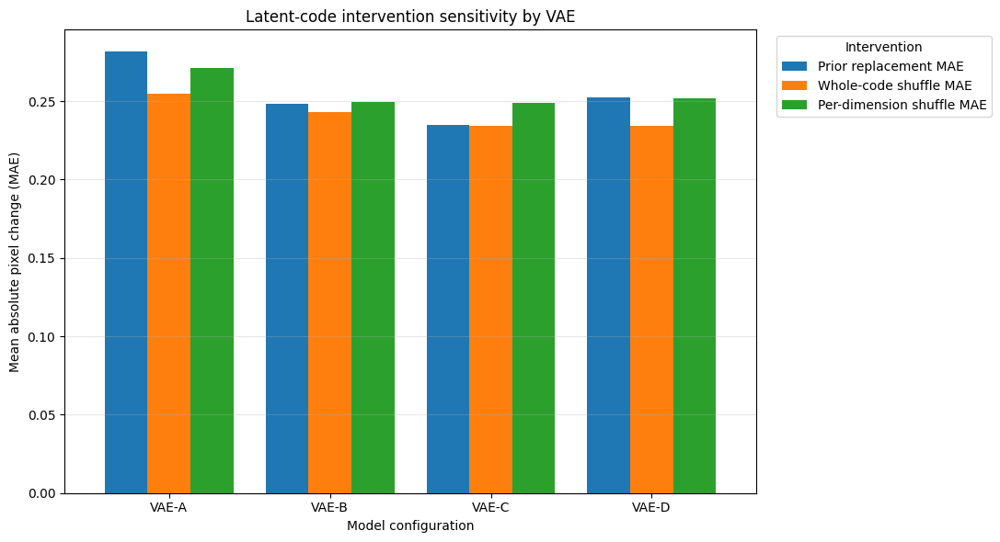

Saved graph to: outputs/figures/p4b_q1_latent_sensitivity.png

Models ranked by average intervention sensitivity:


,model,Prior replacement MAE,Whole-code shuffle MAE,Per-dimension shuffle MAE,Active dimensions,mean_intervention_MAE
0,VAE-A,0.2815,0.2549,0.2712,16,0.2692
1,VAE-B,0.2486,0.2428,0.2497,16,0.2470
3,VAE-D,0.2524,0.2343,0.2517,12,0.2461
2,VAE-C,0.2348,0.2341,0.2487,8,0.2392


In [84]:

# Problem 4B Q1: Which configuration uses z most strongly?
# Metrics: prior replacement MAE, whole-code shuffle MAE,
#          per-dimension shuffle MAE, active latent dimensions.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_names = ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]

def extract_mae(results, model, mode=None):
    if model not in results:
        return np.nan

    item = results[model]
    if mode is not None:
        if mode not in item:
            return np.nan
        item = item[mode]

    return float(item.get("mean_abs_diff", np.nan))

rows = []

for name in model_names:
    rows.append({
        "model": name,
        "Prior replacement MAE": extract_mae(
            intervention_results, name
        ),
        "Whole-code shuffle MAE": extract_mae(
            shuffle_results, name, "whole"
        ),
        "Per-dimension shuffle MAE": extract_mae(
            shuffle_results, name, "per_dim"
        ),
    })

intervention_df = pd.DataFrame(rows)

# Add active dimensions from the Problem 3A table, if available.
if "p3a_table" in globals():
    active_col = "active_dimensions"
    if active_col in p3a_table.columns:
        active_lookup = p3a_table.set_index("model")[active_col]
        intervention_df["Active dimensions"] = (
            intervention_df["model"].map(active_lookup)
        )

display(intervention_df.round(4))

# Grouped bar graph of output sensitivity.
metric_cols = [
    "Prior replacement MAE",
    "Whole-code shuffle MAE",
    "Per-dimension shuffle MAE",
]

ax = intervention_df.set_index("model")[metric_cols].plot(
    kind="bar", figsize=(11, 6), width=0.8
)
ax.set_title("Latent-code intervention sensitivity by VAE")
ax.set_xlabel("Model configuration")
ax.set_ylabel("Mean absolute pixel change (MAE)")
ax.legend(title="Intervention", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

out_path = os.path.join(
    OUT_DIR, "figures", "p4b_q1_latent_sensitivity.png"
)
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved graph to:", out_path)

# Quantitative summary: average available intervention MAEs.
intervention_df["mean_intervention_MAE"] = (
    intervention_df[metric_cols].mean(axis=1, skipna=True)
)

ranking = intervention_df.sort_values(
    "mean_intervention_MAE", ascending=False
)

print("\nModels ranked by average intervention sensitivity:")
display(ranking.round(4))


**4B Q1 — your answer:**

_TODO: write your answer here._

In [85]:
# Problem 4B Q2: Which configuration produces the most defensible prior samples?
# Answer in a short, evidence-based paragraph tied to specific figures or metrics.

Quantitative evidence:


,model,moment_based_Gaussian_KL_lower_is_better,prior_sample_pairwise_pixel_MAE_higher_is_more_diverse,number_of_prior_samples,visual_plausibility
0,VAE-A,131.23286,0.16155,64,Inspect saved grid
1,VAE-B,0.88604,0.22388,64,Inspect saved grid
2,VAE-C,20.89595,0.22597,64,Inspect saved grid
3,VAE-D,11.82922,0.22807,64,Inspect saved grid


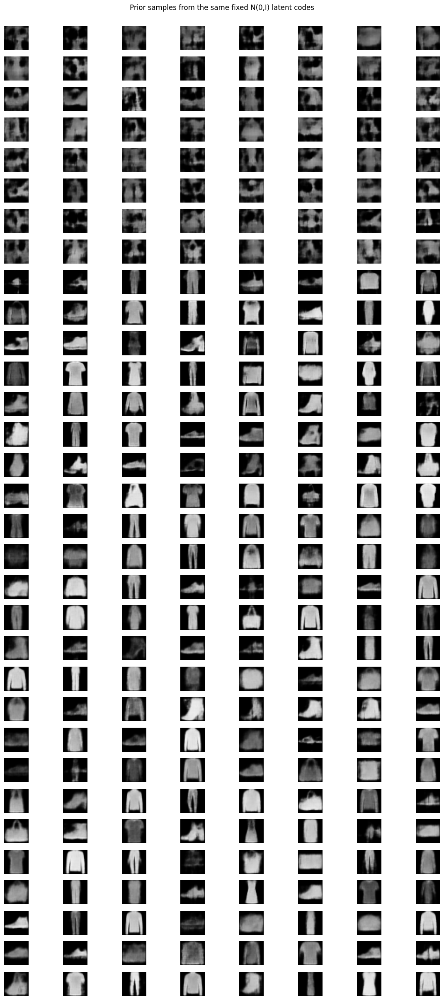

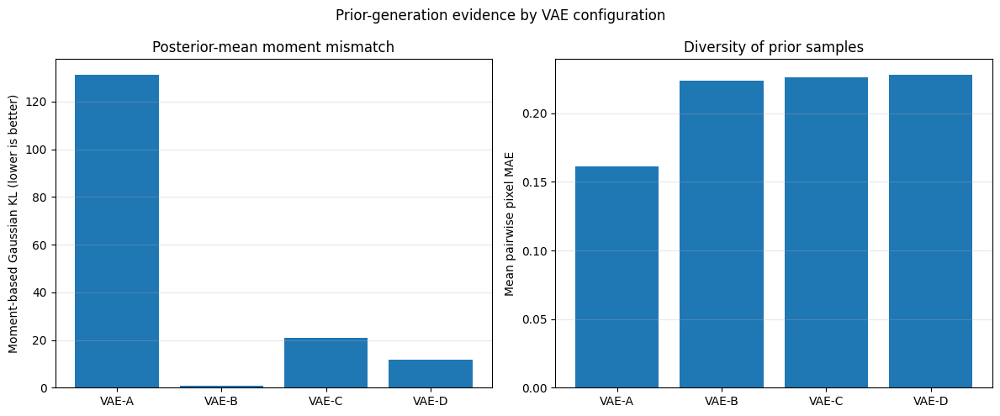

Saved prior sample grids: outputs/figures/p4b_q2_prior_samples.png
Saved metric graph: outputs/figures/p4b_q2_prior_metrics.png
Saved metrics CSV: outputs/metrics/p4b_q2_prior_sample_evidence.csv


In [86]:

# ============================================================
# Problem 4B Q2: Which model produces the most defensible
# prior samples?
#
# Metrics:
# 1. Moment-based Gaussian KL of posterior means vs N(0,I)
# 2. Mean pairwise pixel MAE among 64 fixed-prior samples
# 3. Visual inspection of prior-generated sample grids
#
# Outputs:
#   OUT_DIR/figures/p4b_q2_prior_samples.png
#   OUT_DIR/figures/p4b_q2_prior_metrics.png
#   OUT_DIR/metrics/p4b_q2_prior_sample_evidence.csv
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "metrics"), exist_ok=True)

MODEL_NAMES = ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]


# ------------------------------------------------------------
# 1. Load the same fixed prior codes used earlier
# ------------------------------------------------------------

if "FIXED_PRIOR_Z" in globals():
    fixed_z = FIXED_PRIOR_Z
else:
    prior_path = os.path.join(OUT_DIR, "fixed_prior_codes.pt")
    if not os.path.exists(prior_path):
        raise FileNotFoundError(
            "Fixed prior codes were not found. Run the fixed-prior "
            "sampling cell from Problem 2A first."
        )
    try:
        fixed_z = torch.load(
            prior_path, map_location="cpu", weights_only=True
        )
    except TypeError:
        fixed_z = torch.load(prior_path, map_location="cpu")

if not torch.is_tensor(fixed_z):
    fixed_z = torch.as_tensor(fixed_z)

fixed_z = fixed_z[:64]
if fixed_z.shape[0] < 2:
    raise ValueError("At least two prior codes are required.")


# ------------------------------------------------------------
# 2. Metric definitions
# ------------------------------------------------------------

def moment_gaussian_kl(mu, eps=1e-6):
    """
    KL between N(mean(mu), cov(mu)) and N(0,I).

    This is a moment-matched Gaussian proxy based on posterior
    means. It is not the exact aggregate-posterior KL.
    """
    mu = np.asarray(mu, dtype=np.float64)

    if mu.ndim != 2 or mu.shape[0] < 2:
        raise ValueError("mu must have shape [N, latent_dim], N >= 2.")

    n, d = mu.shape
    mean = mu.mean(axis=0)
    cov = np.atleast_2d(np.cov(mu, rowvar=False, ddof=1))
    cov = cov + eps * np.eye(d)

    sign, logdet = np.linalg.slogdet(cov)
    if sign <= 0:
        return float("nan")

    value = 0.5 * (
        np.trace(cov) + mean @ mean - d - logdet
    )
    return float(max(value, 0.0))


def pairwise_pixel_mae(images):
    """
    Average absolute pixel difference across every distinct
    pair of generated images.
    """
    images = torch.as_tensor(images).float()
    flat = images.reshape(images.shape[0], -1)

    n = flat.shape[0]
    if n < 2:
        return float("nan")

    total = 0.0
    count = 0

    for i in range(n - 1):
        distances = (flat[i + 1:] - flat[i]).abs().mean(dim=1)
        total += distances.sum().item()
        count += distances.numel()

    return total / count


# ------------------------------------------------------------
# 3. Generate the same fixed prior codes for each model
# ------------------------------------------------------------

prior_images_by_model = {}
rows = []

for name in MODEL_NAMES:
    if name not in models:
        print(f"Skipping {name}: model not found.")
        continue

    if name not in encoded:
        print(f"Skipping {name}: encoded test data not found.")
        continue

    model = models[name]
    model.eval()
    device = next(model.parameters()).device

    with torch.no_grad():
        generated = model.decode(fixed_z.to(device)).detach().cpu()

    prior_images_by_model[name] = generated

    mu, logvar, labels = encoded[name]
    moment_kl = moment_gaussian_kl(mu)
    diversity = pairwise_pixel_mae(generated)

    rows.append({
        "model": name,
        "moment_based_Gaussian_KL_lower_is_better": moment_kl,
        "prior_sample_pairwise_pixel_MAE_higher_is_more_diverse": diversity,
        "number_of_prior_samples": len(generated),
        "visual_plausibility": "Inspect saved grid",
    })

prior_evidence_df = pd.DataFrame(rows)

if prior_evidence_df.empty:
    raise ValueError("No models had both a model and encoded test data.")

# Save quantitative evidence.
csv_path = os.path.join(
    OUT_DIR, "metrics", "p4b_q2_prior_sample_evidence.csv"
)
prior_evidence_df.to_csv(csv_path, index=False)

print("Quantitative evidence:")
display(prior_evidence_df.round(5))


# ------------------------------------------------------------
# 4. Plot the prior-sample grids
# ------------------------------------------------------------

available_models = list(prior_images_by_model.keys())
ncols = 8
nrows = len(available_models) * 8

fig, axes = plt.subplots(
    len(available_models) * 8,
    ncols,
    figsize=(12, max(8, len(available_models) * 6)),
)

axes = np.asarray(axes).reshape(len(available_models) * 8, ncols)

for model_index, name in enumerate(available_models):
    images = prior_images_by_model[name]

    for i in range(64):
        row_index = model_index * 8 + i // 8
        col_index = i % 8

        ax = axes[row_index, col_index]
        image = images[i].squeeze().numpy()
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

        if i == 0:
            ax.set_ylabel(
                name,
                rotation=0,
                labelpad=35,
                fontsize=11,
                va="center",
            )

fig.suptitle(
    "Prior samples from the same fixed N(0,I) latent codes",
    y=1.002,
)
plt.tight_layout()

grid_path = os.path.join(
    OUT_DIR, "figures", "p4b_q2_prior_samples.png"
)
plt.savefig(grid_path, dpi=150, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 5. Graph quantitative metrics in separate panels
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    prior_evidence_df["model"],
    prior_evidence_df["moment_based_Gaussian_KL_lower_is_better"],
)
axes[0].set_title("Posterior-mean moment mismatch")
axes[0].set_ylabel("Moment-based Gaussian KL (lower is better)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    prior_evidence_df["model"],
    prior_evidence_df[
        "prior_sample_pairwise_pixel_MAE_higher_is_more_diverse"
    ],
)
axes[1].set_title("Diversity of prior samples")
axes[1].set_ylabel("Mean pairwise pixel MAE")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Prior-generation evidence by VAE configuration")
plt.tight_layout()

metrics_path = os.path.join(
    OUT_DIR, "figures", "p4b_q2_prior_metrics.png"
)
plt.savefig(metrics_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved prior sample grids:", grid_path)
print("Saved metric graph:", metrics_path)
print("Saved metrics CSV:", csv_path)


**4B Q2 — your answer:**

_TODO: write your answer here._

In [87]:
# Problem 4B Q3: Is the model with the smoothest interpolation necessarily the best VAE?
# Answer in a short, evidence-based paragraph tied to specific figures or metrics.

Interpolation endpoints: test index 0 (label 9) -> test index 1 (label 2)


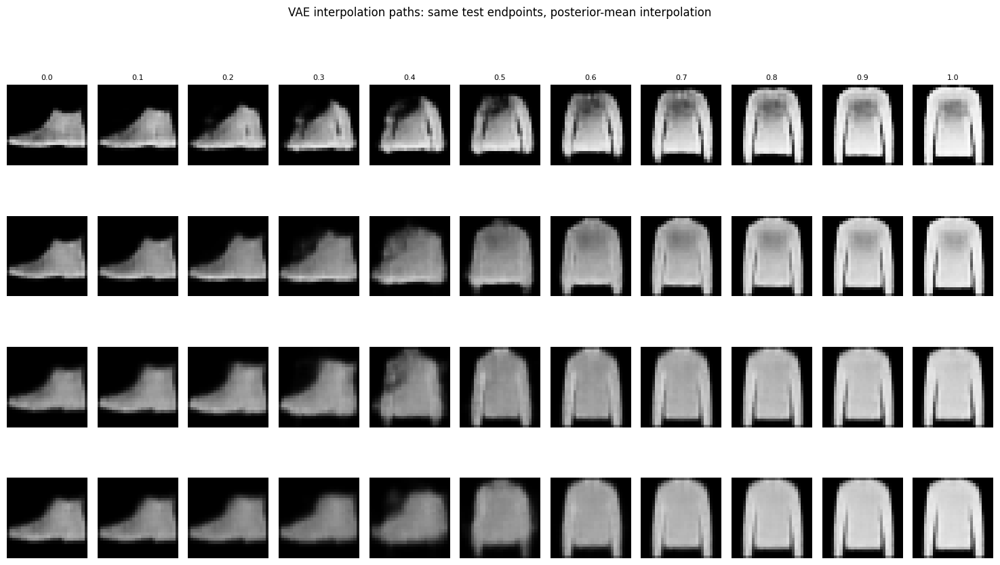

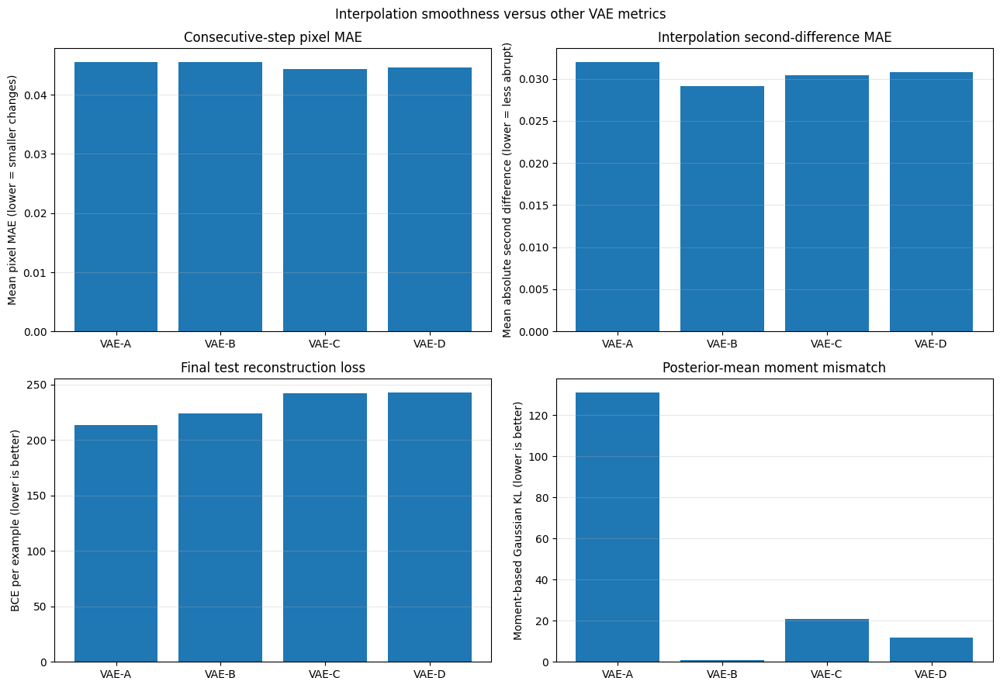

Saved interpolation figure: outputs/figures/p4b_q3_interpolation_comparison.png
Saved metric comparison graph: outputs/figures/p4b_q3_metric_comparison.png
Saved metrics CSV: outputs/metrics/p4b_q3_interpolation_metrics.csv


,model,interpolation_step_MAE_lower_is_smoother,interpolation_second_difference_MAE_lower_is_less_abrupt,final_test_reconstruction_BCE_lower_is_better,active_dimensions_KL_gt_0.01,aggregate_posterior_moment_KL_lower_is_better,endpoint_A_index,endpoint_B_index,endpoint_A_label,endpoint_B_label
0,VAE-A,0.04558,0.03201,213.48601,16,131.23286,0,1,9,2
1,VAE-B,0.04551,0.02913,223.90156,16,0.88604,0,1,9,2
2,VAE-C,0.04437,0.03039,242.00056,8,20.89595,0,1,9,2
3,VAE-D,0.04465,0.03082,243.03765,12,11.82922,0,1,9,2


Smallest average step-to-step change: VAE-C
Smallest second-difference magnitude: VAE-B


In [88]:

# ============================================================
# Problem 4B Q3: Is the smoothest interpolation the best VAE?
#
# Reuses:
#   models, test_set, histories, encoded, OUT_DIR, LATENT_DIM
#
# Outputs:
#   figures/p4b_q3_interpolation_comparison.png
#   figures/p4b_q3_metric_comparison.png
#   metrics/p4b_q3_interpolation_metrics.csv
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "metrics"), exist_ok=True)

MODEL_NAMES = ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]
N_INTERP = 11
ACTIVE_THRESHOLD = 0.01


# ------------------------------------------------------------
# 1. Select a fixed pair of test images with different labels
# ------------------------------------------------------------

# Prefer the same pair from the earlier interpolation experiment.
if "IDX_A" in globals() and "IDX_B" in globals():
    idx_a, idx_b = IDX_A, IDX_B
else:
    idx_a = 0
    label_a = int(test_set[idx_a][1])
    idx_b = next(
        i for i in range(1, len(test_set))
        if int(test_set[i][1]) != label_a
    )

x_a, label_a = test_set[idx_a]
x_b, label_b = test_set[idx_b]

print(
    f"Interpolation endpoints: test index {idx_a} "
    f"(label {int(label_a)}) -> test index {idx_b} "
    f"(label {int(label_b)})"
)


# ------------------------------------------------------------
# 2. Metric helpers
# ------------------------------------------------------------

def moment_gaussian_kl(mu, eps=1e-6):
    """KL of moment-matched Gaussian over posterior means vs N(0,I)."""
    mu = np.asarray(mu, dtype=np.float64)
    n, d = mu.shape

    mean = mu.mean(axis=0)
    cov = np.atleast_2d(np.cov(mu, rowvar=False, ddof=1))
    cov = cov + eps * np.eye(d)

    sign, logdet = np.linalg.slogdet(cov)
    if sign <= 0:
        return float("nan")

    value = 0.5 * (
        np.trace(cov) + mean @ mean - d - logdet
    )
    return float(max(value, 0.0))


def interpolation_smoothness(images):
    """
    Mean pixel MAE between consecutive decoded images.
    Lower = smaller average changes between neighboring steps.

    Also calculates second-difference magnitude as a rough
    measure of abrupt changes in the interpolation trajectory.
    """
    images = torch.as_tensor(images).float()
    flat = images.reshape(images.shape[0], -1)

    first_diff = flat[1:] - flat[:-1]
    step_mae = first_diff.abs().mean().item()

    if flat.shape[0] >= 3:
        second_diff = flat[2:] - 2 * flat[1:-1] + flat[:-2]
        curvature = second_diff.abs().mean().item()
    else:
        curvature = float("nan")

    return step_mae, curvature


def minmax(series, higher_is_better=True):
    """Normalize metrics to [0,1] for visualization only."""
    s = pd.to_numeric(series, errors="coerce")
    out = pd.Series(np.nan, index=s.index, dtype=float)
    valid = s.dropna()

    if len(valid) == 0:
        return out

    lo, hi = valid.min(), valid.max()
    if np.isclose(lo, hi):
        out.loc[valid.index] = 0.5
    else:
        score = (s.loc[valid.index] - lo) / (hi - lo)
        out.loc[valid.index] = score if higher_is_better else 1 - score

    return out


# ------------------------------------------------------------
# 3. Encode endpoints, interpolate posterior means, decode
# ------------------------------------------------------------

alpha = torch.linspace(0, 1, N_INTERP)
interpolations = {}
rows = []

for name in MODEL_NAMES:
    if name not in models or name not in encoded:
        print(f"Skipping {name}: model or encoded data missing.")
        continue

    model = models[name]
    model.eval()
    device = next(model.parameters()).device

    xa = x_a.unsqueeze(0).to(device)
    xb = x_b.unsqueeze(0).to(device)

    with torch.no_grad():
        mu_a, _ = model.encode(xa)
        mu_b, _ = model.encode(xb)

        z_path = torch.stack([
            (1 - a) * mu_a.squeeze(0) + a * mu_b.squeeze(0)
            for a in alpha.to(device)
        ])

        decoded = model.decode(z_path).detach().cpu()

    interpolations[name] = decoded

    step_mae, curvature = interpolation_smoothness(decoded)

    mu, logvar, labels = encoded[name]
    mu = np.asarray(mu)
    logvar = np.asarray(logvar)

    # Average KL contribution for each latent dimension.
    kl_per_dim = 0.5 * np.mean(
        mu**2 + np.exp(logvar) - logvar - 1.0,
        axis=0,
    )
    active_dims = int(np.sum(kl_per_dim > ACTIVE_THRESHOLD))

    # Final test reconstruction BCE from existing training history.
    final_recon = (
        float(histories[name][-1]["test_recon"])
        if name in histories and histories[name]
        else np.nan
    )

    rows.append({
        "model": name,
        "interpolation_step_MAE_lower_is_smoother": step_mae,
        "interpolation_second_difference_MAE_lower_is_less_abrupt": curvature,
        "final_test_reconstruction_BCE_lower_is_better": final_recon,
        "active_dimensions_KL_gt_0.01": active_dims,
        "aggregate_posterior_moment_KL_lower_is_better":
            moment_gaussian_kl(mu),
        "endpoint_A_index": idx_a,
        "endpoint_B_index": idx_b,
        "endpoint_A_label": int(label_a),
        "endpoint_B_label": int(label_b),
    })

interp_df = pd.DataFrame(rows)

if interp_df.empty:
    raise ValueError(
        "No models could be evaluated. Check models and encoded."
    )


# ------------------------------------------------------------
# 4. Plot the decoded interpolation paths
# ------------------------------------------------------------

names = list(interpolations.keys())
fig, axes = plt.subplots(
    len(names), N_INTERP,
    figsize=(1.35 * N_INTERP, 2.2 * len(names)),
)

if len(names) == 1:
    axes = np.expand_dims(axes, axis=0)

for r, name in enumerate(names):
    images = interpolations[name]

    for c in range(N_INTERP):
        ax = axes[r, c]
        ax.imshow(images[c].squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

        if r == 0:
            ax.set_title(f"{alpha[c].item():.1f}", fontsize=8)

    axes[r, 0].set_ylabel(name, rotation=0, labelpad=35, va="center")

fig.suptitle(
    "VAE interpolation paths: same test endpoints, posterior-mean interpolation",
    y=1.01,
)
plt.tight_layout()

interp_fig_path = os.path.join(
    OUT_DIR, "figures", "p4b_q3_interpolation_comparison.png"
)
plt.savefig(interp_fig_path, dpi=150, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 5. Plot the quantitative metrics
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_specs = [
    (
        "interpolation_step_MAE_lower_is_smoother",
        "Consecutive-step pixel MAE",
        "Mean pixel MAE (lower = smaller changes)",
    ),
    (
        "interpolation_second_difference_MAE_lower_is_less_abrupt",
        "Interpolation second-difference MAE",
        "Mean absolute second difference (lower = less abrupt)",
    ),
    (
        "final_test_reconstruction_BCE_lower_is_better",
        "Final test reconstruction loss",
        "BCE per example (lower is better)",
    ),
    (
        "aggregate_posterior_moment_KL_lower_is_better",
        "Posterior-mean moment mismatch",
        "Moment-based Gaussian KL (lower is better)",
    ),
]

for ax, (column, title, ylabel) in zip(axes.flat, plot_specs):
    ax.bar(interp_df["model"], interp_df[column])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Interpolation smoothness versus other VAE metrics")
plt.tight_layout()

metrics_fig_path = os.path.join(
    OUT_DIR, "figures", "p4b_q3_metric_comparison.png"
)
plt.savefig(metrics_fig_path, dpi=150, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 6. Save metrics and show results
# ------------------------------------------------------------

csv_path = os.path.join(
    OUT_DIR, "metrics", "p4b_q3_interpolation_metrics.csv"
)
interp_df.to_csv(csv_path, index=False)

print("Saved interpolation figure:", interp_fig_path)
print("Saved metric comparison graph:", metrics_fig_path)
print("Saved metrics CSV:", csv_path)

display(interp_df.round(5))

# Identify the smallest step-change and smallest curvature.
smoothest_step_model = interp_df.loc[
    interp_df["interpolation_step_MAE_lower_is_smoother"].idxmin(),
    "model",
]
smoothest_curvature_model = interp_df.loc[
    interp_df[
        "interpolation_second_difference_MAE_lower_is_less_abrupt"
    ].idxmin(),
    "model",
]

print("Smallest average step-to-step change:", smoothest_step_model)
print("Smallest second-difference magnitude:", smoothest_curvature_model)


**4B Q3 — your answer:**

_TODO: write your answer here._

In [89]:
# Problem 4B Q4: What is your strongest evidence for or against posterior collapse?
# Answer in a short, evidence-based paragraph tied to specific figures or metrics.

Posterior-collapse metric summary:


,model,mean_total_KL_per_example,active_dimensions_KL_gt_0.01,inactive_dimensions_KL_le_0.01,fraction_inactive_dimensions,mean_KL_per_dimension,median_KL_per_dimension,dimensions_with_KL_below_0.001,mean_variance_of_posterior_means,dimensions_with_mu_variance_below_0.01,mean_posterior_logvar,final_test_KL_from_history,final_test_reconstruction_BCE,final_test_total_loss
0,VAE-A,292.35494,16,0,0.00,18.27218,18.03355,0,14.27129,0,-18.29449,292.35494,213.48601,213.48601
1,VAE-B,16.81198,16,0,0.00,1.05075,1.01743,0,0.75766,0,-2.11381,16.81198,223.90156,240.71354
2,VAE-C,7.25580,8,8,0.50,0.45349,0.01509,0,0.34509,6,-0.91317,7.25580,242.00056,271.02377
3,VAE-D,7.24561,12,4,0.25,0.45285,0.15488,0,0.37783,3,-0.91326,7.24561,243.03765,272.02008



Saved metrics: outputs/metrics/p4b_q4_posterior_collapse_metrics.csv


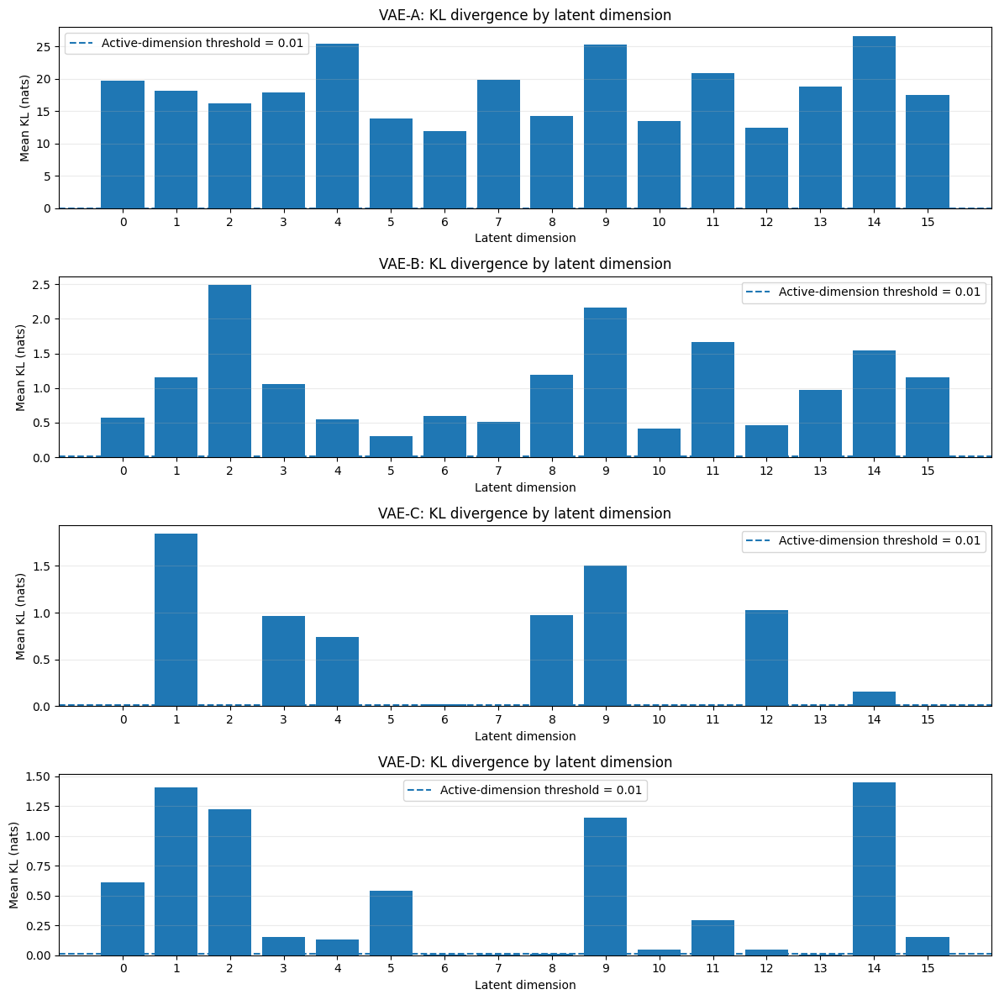

Saved figure: outputs/figures/p4b_q4_per_dimension_kl.png


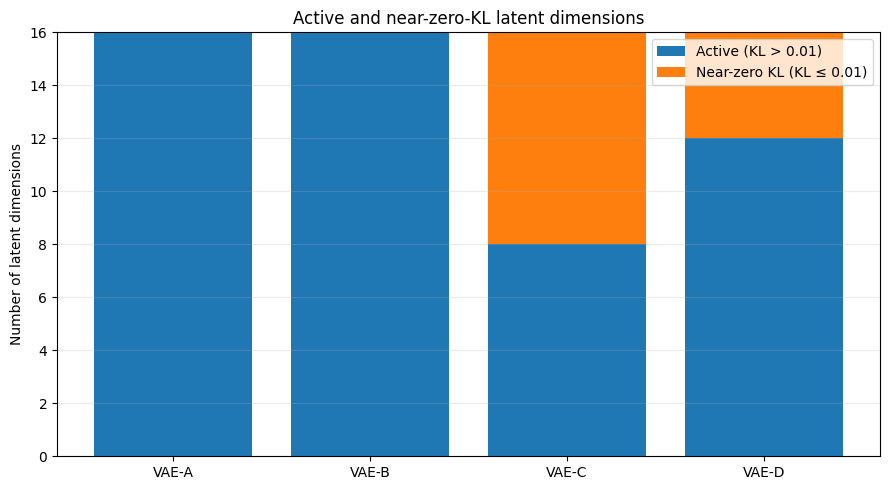

Saved figure: outputs/figures/p4b_q4_active_dimensions.png


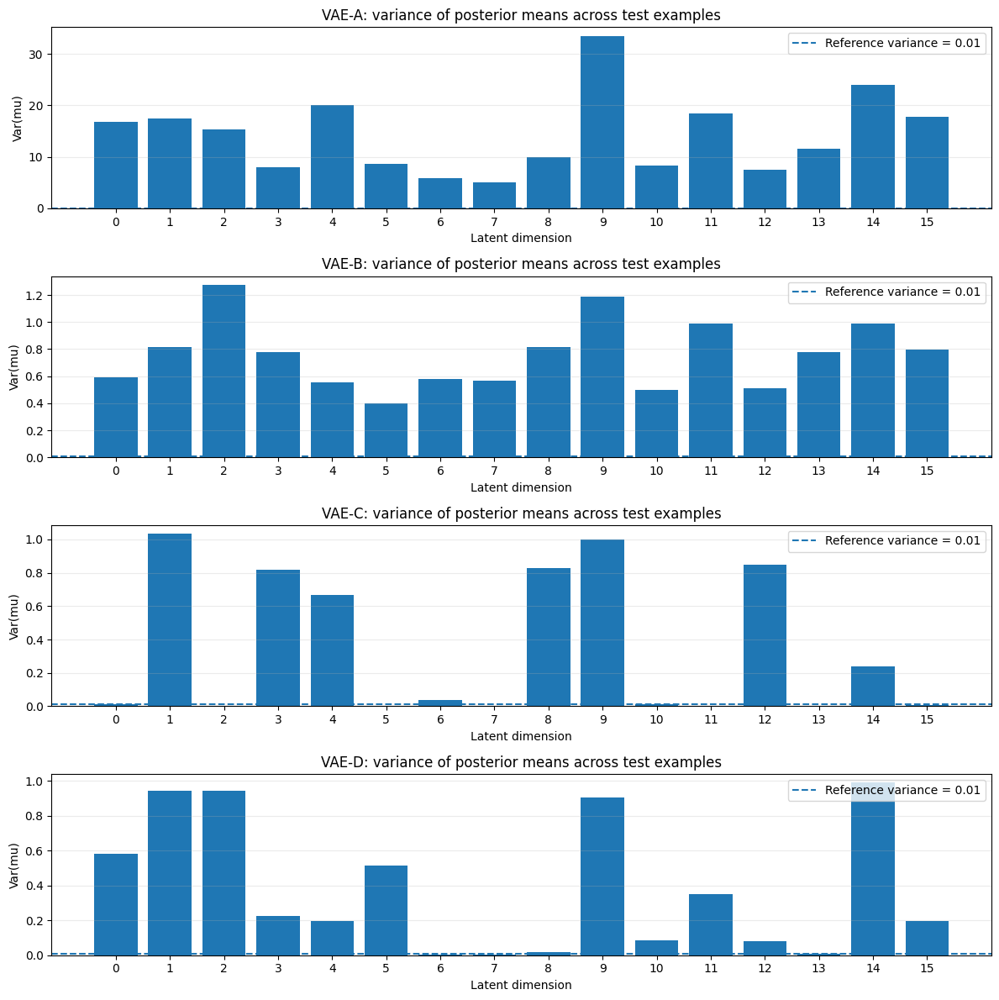

Saved figure: outputs/figures/p4b_q4_posterior_mean_variance.png


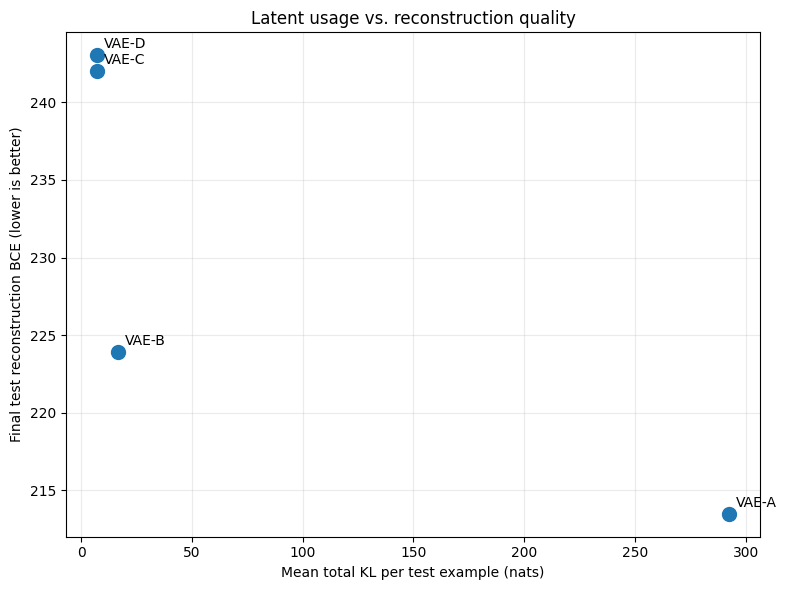

Saved figure: outputs/figures/p4b_q4_kl_vs_reconstruction.png


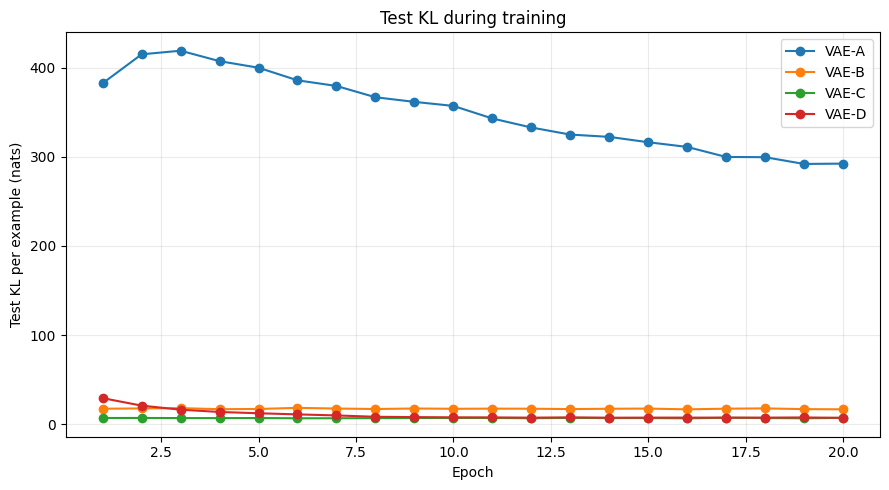

Saved figure: outputs/figures/p4b_q4_test_kl_during_training.png

Suggested evidence-based paragraph:
VAE-A: 16/16 active dimensions, total mean KL=292.3549 nats/example, and mean Var(mu)=14.27129.
VAE-B: 16/16 active dimensions, total mean KL=16.8120 nats/example, and mean Var(mu)=0.75766.
VAE-C: 8/16 active dimensions, total mean KL=7.2558 nats/example, and mean Var(mu)=0.34509.
VAE-D: 12/16 active dimensions, total mean KL=7.2456 nats/example, and mean Var(mu)=0.37783.


In [90]:
# ============================================================
# Problem 4B Q4: What is your strongest evidence for or against
# posterior collapse?
#
# Reuses existing models, encoded, histories, and OUT_DIR.
# Produces latent-dimension metrics, comparison graphs, and a
# CSV summary for VAE-A, VAE-B, VAE-C, and VAE-D.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path

# ---------- Output directories ----------
FIG_DIR = os.path.join(OUT_DIR, "figures")
METRIC_DIR = os.path.join(OUT_DIR, "metrics")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(METRIC_DIR, exist_ok=True)

MODEL_NAMES = [name for name in ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]
               if name in models and name in encoded]

if not MODEL_NAMES:
    raise ValueError("Could not find the expected VAE models and encoded test-set results.")

# ---------- Calculate latent-space metrics ----------
# encoded[name] = (mu, logvar, labels)
#
# Mean KL per dimension:
# KL_j = 0.5 * mean(mu_j^2 + exp(logvar_j) - logvar_j - 1)
#
# A dimension with KL near zero has a posterior close to N(0,1).
# Active dimensions are defined here as KL_j > 0.01 nats.
# This is a practical threshold, not a universal definition.

ACTIVE_KL_THRESHOLD = 0.01
EPS = 1e-6

rows = []
per_dim_kl = {}
per_dim_mu_var = {}
per_dim_logvar_mean = {}

for name in MODEL_NAMES:
    mu, logvar, labels = encoded[name]
    mu = np.asarray(mu, dtype=np.float64)
    logvar = np.asarray(logvar, dtype=np.float64)

    if mu.shape != logvar.shape:
        raise ValueError(f"{name}: mu and logvar shapes do not match.")

    # Mean KL divergence from each approximate posterior to N(0, I),
    # averaged across examples separately for each latent dimension.
    kl_j = 0.5 * np.mean(
        mu**2 + np.exp(np.clip(logvar, -30, 20)) - logvar - 1.0,
        axis=0
    )

    # Variance across examples of posterior means.
    mu_var = np.var(mu, axis=0)

    # Mean predicted posterior log-variance per dimension.
    mean_logvar = np.mean(logvar, axis=0)

    per_dim_kl[name] = kl_j
    per_dim_mu_var[name] = mu_var
    per_dim_logvar_mean[name] = mean_logvar

    final_epoch = histories[name][-1] if name in histories and histories[name] else {}
    final_test_kl = final_epoch.get("test_kl", np.nan)
    final_test_recon = final_epoch.get("test_recon", np.nan)
    final_test_total = final_epoch.get("test_total", np.nan)

    rows.append({
        "model": name,
        "mean_total_KL_per_example": float(np.sum(kl_j)),
        "active_dimensions_KL_gt_0.01": int(np.sum(kl_j > ACTIVE_KL_THRESHOLD)),
        "inactive_dimensions_KL_le_0.01": int(np.sum(kl_j <= ACTIVE_KL_THRESHOLD)),
        "fraction_inactive_dimensions": float(np.mean(kl_j <= ACTIVE_KL_THRESHOLD)),
        "mean_KL_per_dimension": float(np.mean(kl_j)),
        "median_KL_per_dimension": float(np.median(kl_j)),
        "dimensions_with_KL_below_0.001": int(np.sum(kl_j < 0.001)),
        "mean_variance_of_posterior_means": float(np.mean(mu_var)),
        "dimensions_with_mu_variance_below_0.01": int(np.sum(mu_var < 0.01)),
        "mean_posterior_logvar": float(np.mean(logvar)),
        "final_test_KL_from_history": float(final_test_kl) if np.isfinite(final_test_kl) else np.nan,
        "final_test_reconstruction_BCE": float(final_test_recon) if np.isfinite(final_test_recon) else np.nan,
        "final_test_total_loss": float(final_test_total) if np.isfinite(final_test_total) else np.nan,
    })

collapse_df = pd.DataFrame(rows)

csv_path = os.path.join(METRIC_DIR, "p4b_q4_posterior_collapse_metrics.csv")
collapse_df.to_csv(csv_path, index=False)

print("Posterior-collapse metric summary:")
display(collapse_df.round(5))
print(f"\nSaved metrics: {csv_path}")

# ---------- Figure 1: KL divergence for each latent dimension ----------
n_models = len(MODEL_NAMES)
fig, axes = plt.subplots(n_models, 1, figsize=(12, 3.0 * n_models), squeeze=False)

for i, name in enumerate(MODEL_NAMES):
    ax = axes[i, 0]
    values = per_dim_kl[name]
    ax.bar(np.arange(len(values)), values)
    ax.axhline(
        ACTIVE_KL_THRESHOLD,
        linestyle="--",
        linewidth=1.5,
        label=f"Active-dimension threshold = {ACTIVE_KL_THRESHOLD}"
    )
    ax.set_title(f"{name}: KL divergence by latent dimension")
    ax.set_xlabel("Latent dimension")
    ax.set_ylabel("Mean KL (nats)")
    ax.set_xticks(np.arange(len(values)))
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
kl_fig_path = os.path.join(FIG_DIR, "p4b_q4_per_dimension_kl.png")
fig.savefig(kl_fig_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {kl_fig_path}")

# ---------- Figure 2: Active vs. inactive dimensions ----------
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(MODEL_NAMES))
active = [
    int(np.sum(per_dim_kl[name] > ACTIVE_KL_THRESHOLD))
    for name in MODEL_NAMES
]
inactive = [LATENT_DIM - value for value in active]

ax.bar(x, active, label=f"Active (KL > {ACTIVE_KL_THRESHOLD})")
ax.bar(x, inactive, bottom=active, label=f"Near-zero KL (KL ≤ {ACTIVE_KL_THRESHOLD})")
ax.set_xticks(x)
ax.set_xticklabels(MODEL_NAMES)
ax.set_ylim(0, LATENT_DIM)
ax.set_ylabel("Number of latent dimensions")
ax.set_title("Active and near-zero-KL latent dimensions")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

active_fig_path = os.path.join(FIG_DIR, "p4b_q4_active_dimensions.png")
fig.savefig(active_fig_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {active_fig_path}")

# ---------- Figure 3: Posterior-mean variance by dimension ----------
# If mu barely changes across test examples, the corresponding latent
# dimension carries little information about which example was encoded.
fig, axes = plt.subplots(n_models, 1, figsize=(12, 3.0 * n_models), squeeze=False)

for i, name in enumerate(MODEL_NAMES):
    ax = axes[i, 0]
    values = per_dim_mu_var[name]
    ax.bar(np.arange(len(values)), values)
    ax.axhline(0.01, linestyle="--", linewidth=1.5,
               label="Reference variance = 0.01")
    ax.set_title(f"{name}: variance of posterior means across test examples")
    ax.set_xlabel("Latent dimension")
    ax.set_ylabel("Var(mu)")
    ax.set_xticks(np.arange(len(values)))
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
var_fig_path = os.path.join(FIG_DIR, "p4b_q4_posterior_mean_variance.png")
fig.savefig(var_fig_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {var_fig_path}")

# ---------- Figure 4: Total KL vs. reconstruction BCE ----------
# Low KL alone does not establish collapse: a model may reconstruct well
# with a compact latent representation. Consider both axes together.
plot_df = collapse_df.dropna(subset=["final_test_reconstruction_BCE"]).copy()

if len(plot_df) > 0:
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(
        plot_df["mean_total_KL_per_example"],
        plot_df["final_test_reconstruction_BCE"],
        s=100
    )
    for _, row in plot_df.iterrows():
        ax.annotate(
            row["model"],
            (row["mean_total_KL_per_example"], row["final_test_reconstruction_BCE"]),
            xytext=(5, 5),
            textcoords="offset points"
        )
    ax.set_xlabel("Mean total KL per test example (nats)")
    ax.set_ylabel("Final test reconstruction BCE (lower is better)")
    ax.set_title("Latent usage vs. reconstruction quality")
    ax.grid(alpha=0.25)
    fig.tight_layout()

    tradeoff_fig_path = os.path.join(FIG_DIR, "p4b_q4_kl_vs_reconstruction.png")
    fig.savefig(tradeoff_fig_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {tradeoff_fig_path}")

# ---------- Optional: KL over training ----------
# Useful for identifying whether KL fell toward zero as training progressed.
fig, ax = plt.subplots(figsize=(9, 5))
plotted = False

for name in MODEL_NAMES:
    if name not in histories or not histories[name]:
        continue
    epochs = [item.get("epoch", i + 1) for i, item in enumerate(histories[name])]
    kl_values = [item.get("test_kl", np.nan) for item in histories[name]]
    if np.isfinite(np.asarray(kl_values, dtype=float)).any():
        ax.plot(epochs, kl_values, marker="o", label=name)
        plotted = True

if plotted:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Test KL per example (nats)")
    ax.set_title("Test KL during training")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    kl_training_path = os.path.join(FIG_DIR, "p4b_q4_test_kl_during_training.png")
    fig.savefig(kl_training_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {kl_training_path}")
else:
    plt.close(fig)
    print("Skipped training KL plot: test_kl values were not available in histories.")

# ---------- Evidence-based paragraph using actual results ----------
# This is a cautious summary of quantitative indicators, not a definitive
# diagnosis. Stronger evidence of collapse is near-zero KL in most dimensions
# together with near-zero variation in posterior means.
print("\nSuggested evidence-based paragraph:")
for _, row in collapse_df.iterrows():
    print(
        f"{row['model']}: {row['active_dimensions_KL_gt_0.01']}/{LATENT_DIM} "
        f"active dimensions, total mean KL={row['mean_total_KL_per_example']:.4f} "
        f"nats/example, and mean Var(mu)={row['mean_variance_of_posterior_means']:.5f}."
    )

most_inactive = collapse_df.sort_values(
    ["fraction_inactive_dimensions", "mean_total_KL_per_example"],
    ascending=[False, True]
).iloc[0]

most_active = collapse_df.sort_values(
    ["active_dimensions_KL_gt_0.01", "mean_total_KL_per_example"],
    ascending=[False, False]
).iloc[0]

**4B Q4 — your answer:**

_TODO: write your answer here._

In [91]:
# Problem 4B Q5: If two VAEs reconstruct equally well, what additional evidence determines which learned the more useful latent space?
# Answer in a short, evidence-based paragraph tied to specific figures or metrics.

Latent-space usefulness metrics:


,model,final_test_reconstruction_BCE_lower_is_better,final_test_KL,active_dimensions_KL_gt_0.01,total_mean_KL_per_example,mean_variance_of_posterior_means,dimensions_with_mu_variance_gt_0.01,aggregate_posterior_moment_Gaussian_KL_proxy,prior_replacement_MAE,whole_code_shuffle_MAE,per_dimension_shuffle_MAE,score_active_dimensions,score_posterior_mean_variance,score_prior_replacement_sensitivity,score_per_dimension_sensitivity,score_prior_compatibility,score_reconstruction,latent_usefulness_score
0,VAE-A,213.4860,292.3549,16,292.3549,14.2713,16,131.2329,0.2815,0.2549,0.2712,1.0,1.0000,1.0000,1.0000,0.0000,1.0000,0.8000
1,VAE-B,223.9016,16.8120,16,16.8120,0.7577,16,0.8860,0.2486,0.2428,0.2497,1.0,0.0296,0.2950,0.0424,1.0000,0.6475,0.4734
2,VAE-D,243.0376,7.2456,12,7.2456,0.3778,13,11.8244,0.2524,0.2343,0.2517,0.5,0.0024,0.3761,0.1310,0.9161,0.0000,0.3851
3,VAE-C,242.0006,7.2558,8,7.2558,0.3451,10,20.8791,0.2348,0.2341,0.2487,0.0,0.0000,0.0000,0.0000,0.8466,0.0351,0.1693


Saved CSV: outputs/metrics/p4b_q5_latent_usefulness_comparison.csv


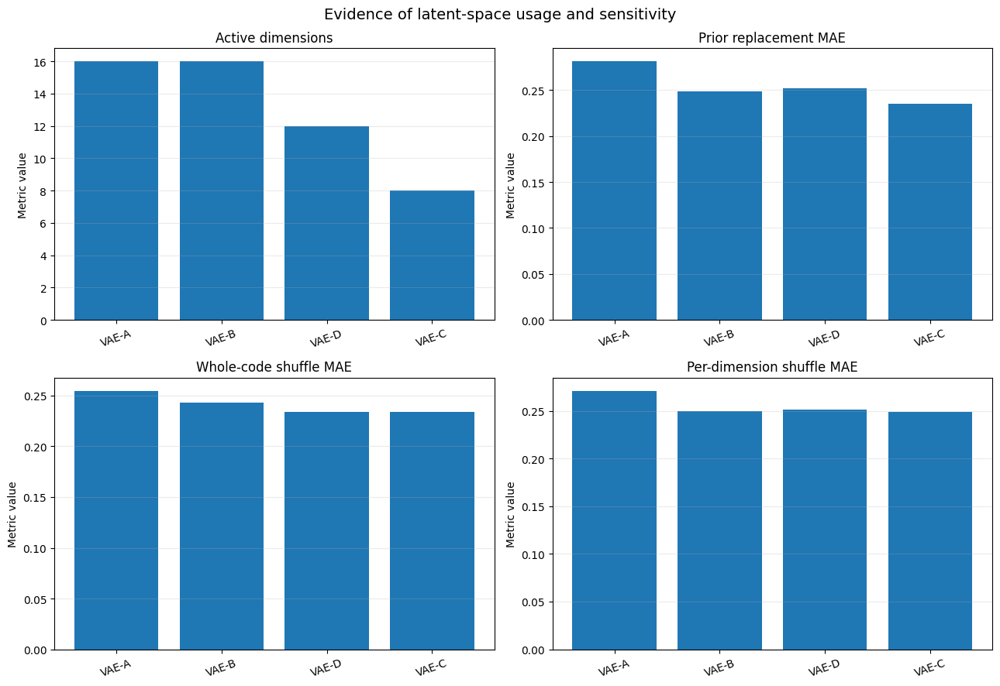

Saved figure: outputs/figures/p4b_q5_latent_sensitivity_metrics.png


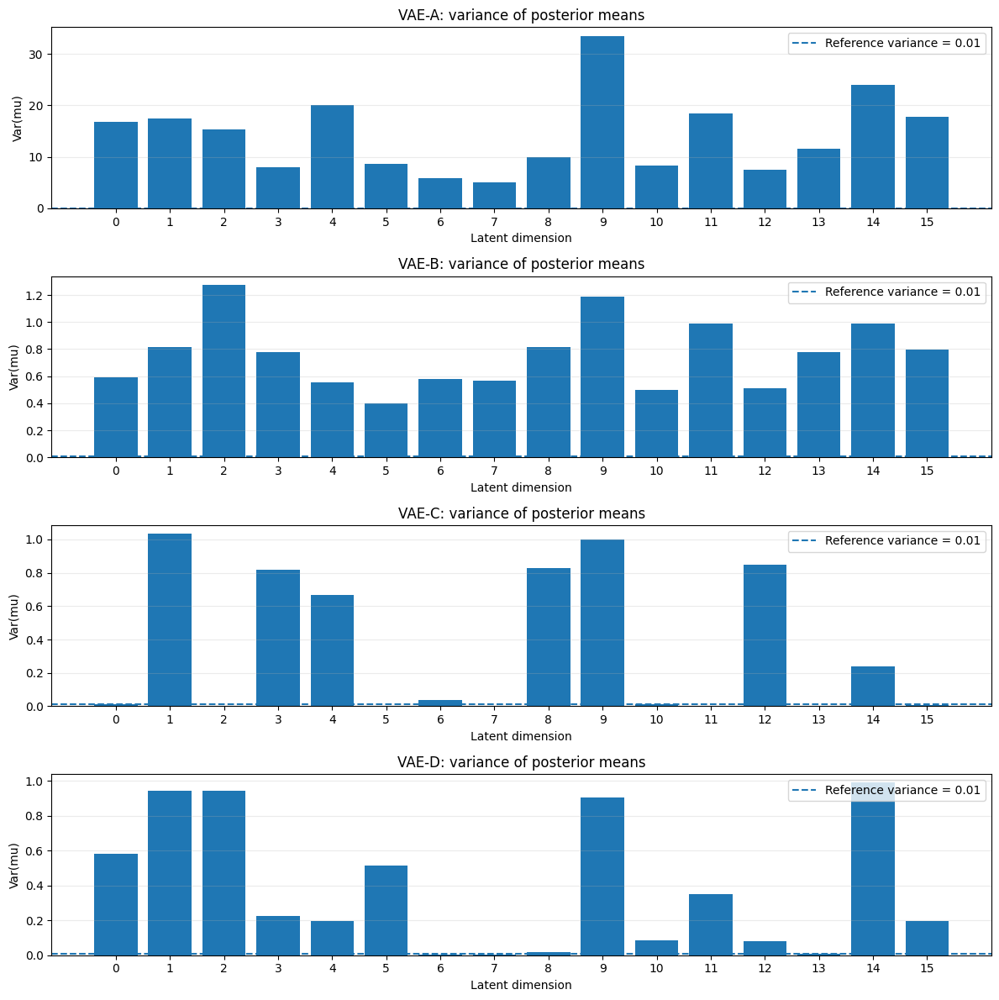

Saved figure: outputs/figures/p4b_q5_posterior_mean_variance.png


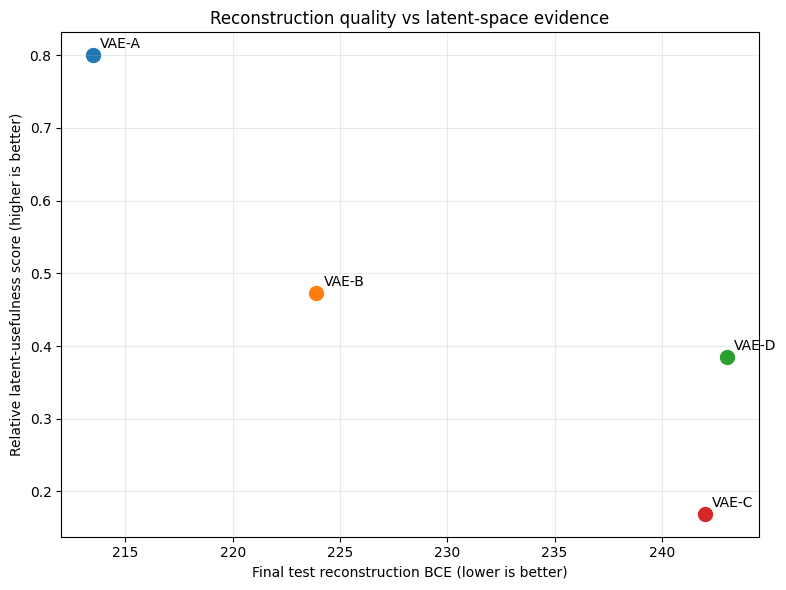

Saved figure: outputs/figures/p4b_q5_reconstruction_vs_usefulness.png


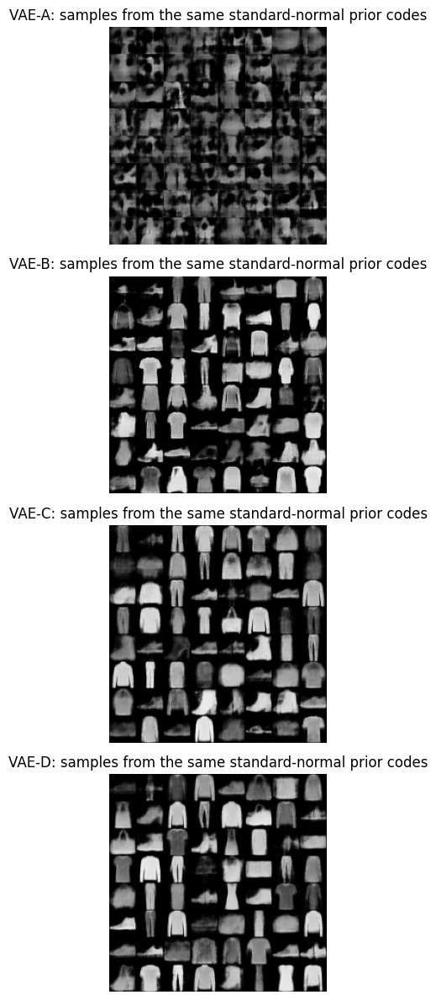

Saved figure: outputs/figures/p4b_q5_prior_sample_grids.png


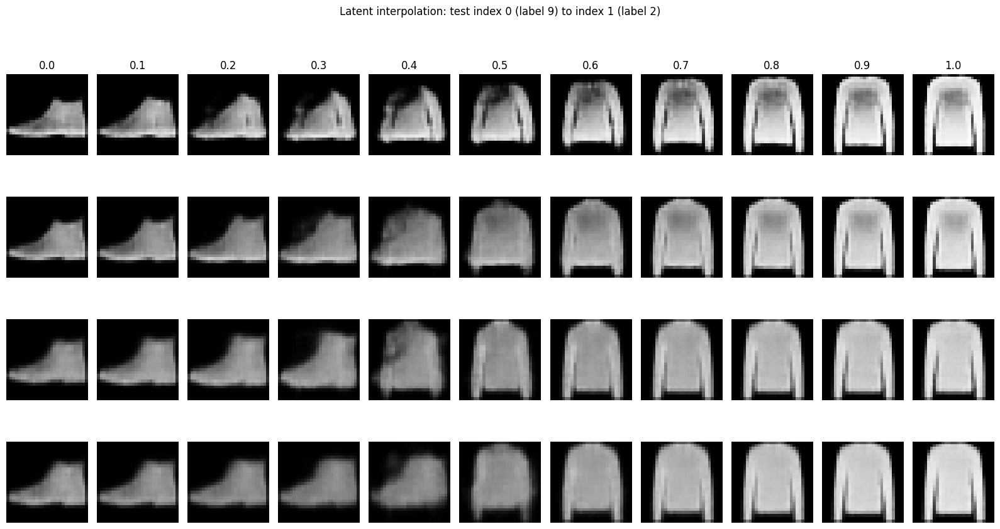

Saved figure: outputs/figures/p4b_q5_interpolation_comparison.png
Interpolation smoothness metrics:


,model,interpolation_step_MAE_lower_is_smoother,endpoint_A_index,endpoint_B_index,endpoint_A_label,endpoint_B_label
0,VAE-A,0.04558,0,1,9,2
1,VAE-B,0.04551,0,1,9,2
2,VAE-C,0.04437,0,1,9,2
3,VAE-D,0.04465,0,1,9,2


Saved CSV: outputs/metrics/p4b_q5_interpolation_metrics.csv

Evidence-based interpretation:
VAE-A has the highest relative latent-usefulness score among the models evaluated (0.800). It has 16 active dimensions by the KL > 0.01 criterion. Check its interpolation and prior-sample grids before selecting it: active dimensions and sensitivity indicate latent usage, but do not guarantee interpretable changes or realistic generations.


In [92]:
# ============================================================
# Problem 4B Q5: If two VAEs reconstruct equally well, which
# learned the more useful latent space?
#
# Uses existing results:
# models, encoded, histories, intervention_results, shuffle_results,
# pca/interpolation results if available, FIXED_PRIOR_Z, OUT_DIR.
#
# Outputs:
# 1. Comparison metrics CSV
# 2. Latent usefulness metric graph
# 3. Posterior-mean variance graph
# 4. Prior sample grids
# 5. Interpolation grids
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from itertools import combinations

FIG_DIR = os.path.join(OUT_DIR, "figures")
METRIC_DIR = os.path.join(OUT_DIR, "metrics")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(METRIC_DIR, exist_ok=True)

MODEL_NAMES = [
    name for name in ["VAE-A", "VAE-B", "VAE-C", "VAE-D"]
    if name in models and name in encoded and name in histories
]

if len(MODEL_NAMES) < 2:
    raise ValueError("At least two trained models with encoded results and histories are required.")

# ------------------------------------------------------------
# 1. Calculate latent usefulness metrics
# ------------------------------------------------------------

ACTIVE_KL_THRESHOLD = 0.01
rows = []
latent_stats = {}

for name in MODEL_NAMES:
    mu, logvar, labels = encoded[name]
    mu = np.asarray(mu, dtype=np.float64)
    logvar = np.asarray(logvar, dtype=np.float64)

    # KL divergence from each approximate posterior dimension to N(0,1)
    kl_dim = 0.5 * np.mean(
        mu**2 + np.exp(np.clip(logvar, -30, 20)) - logvar - 1,
        axis=0
    )

    # Variation in posterior means across test examples
    mu_var = np.var(mu, axis=0)

    # Aggregate-posterior moment-matched Gaussian KL proxy.
    # This is a proxy, not the exact aggregate-posterior KL.
    mu_mean = mu.mean(axis=0)
    cov = np.cov(mu, rowvar=False)
    cov = np.atleast_2d(cov)
    cov_reg = cov + 1e-5 * np.eye(cov.shape[0])

    sign, logdet = np.linalg.slogdet(cov_reg)
    if sign > 0:
        aggregate_kl_proxy = 0.5 * (
            np.trace(cov_reg) + mu_mean @ mu_mean
            - len(mu_mean) - logdet
        )
    else:
        aggregate_kl_proxy = np.nan

    # Final-epoch test metrics
    final = histories[name][-1]
    recon_bce = float(final.get("test_recon", np.nan))
    test_kl = float(final.get("test_kl", np.nan))

    # Existing intervention sensitivity results, if available
    prior_mae = np.nan
    whole_shuffle_mae = np.nan
    dim_shuffle_mae = np.nan

    if "intervention_results" in globals() and name in intervention_results:
        prior_mae = float(intervention_results[name].get("mean_abs_diff", np.nan))

    if "shuffle_results" in globals() and name in shuffle_results:
        whole_shuffle_mae = float(
            shuffle_results[name].get("whole", {}).get("mean_abs_diff", np.nan)
        )
        dim_shuffle_mae = float(
            shuffle_results[name].get("per_dim", {}).get("mean_abs_diff", np.nan)
        )

    latent_stats[name] = {
        "mu": mu,
        "logvar": logvar,
        "kl_dim": kl_dim,
        "mu_var": mu_var,
    }

    rows.append({
        "model": name,
        "final_test_reconstruction_BCE_lower_is_better": recon_bce,
        "final_test_KL": test_kl,
        "active_dimensions_KL_gt_0.01": int(np.sum(kl_dim > ACTIVE_KL_THRESHOLD)),
        "total_mean_KL_per_example": float(kl_dim.sum()),
        "mean_variance_of_posterior_means": float(mu_var.mean()),
        "dimensions_with_mu_variance_gt_0.01": int(np.sum(mu_var > 0.01)),
        "aggregate_posterior_moment_Gaussian_KL_proxy": float(aggregate_kl_proxy),
        "prior_replacement_MAE": prior_mae,
        "whole_code_shuffle_MAE": whole_shuffle_mae,
        "per_dimension_shuffle_MAE": dim_shuffle_mae,
    })

usefulness_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 2. Create comparable normalized scores
# Larger scores indicate stronger relative evidence on a metric.
# These scores are descriptive, not a universal definition of quality.
# ------------------------------------------------------------

def normalized_score(series, higher_is_better=True):
    s = pd.to_numeric(series, errors="coerce")
    valid = s.dropna()

    result = pd.Series(np.nan, index=s.index, dtype=float)
    if len(valid) == 0:
        return result
    if valid.max() == valid.min():
        result.loc[valid.index] = 0.5
    elif higher_is_better:
        result.loc[valid.index] = (valid - valid.min()) / (valid.max() - valid.min())
    else:
        result.loc[valid.index] = (valid.max() - valid) / (valid.max() - valid.min())
    return result

usefulness_df["score_active_dimensions"] = normalized_score(
    usefulness_df["active_dimensions_KL_gt_0.01"], True
)
usefulness_df["score_posterior_mean_variance"] = normalized_score(
    usefulness_df["mean_variance_of_posterior_means"], True
)
usefulness_df["score_prior_replacement_sensitivity"] = normalized_score(
    usefulness_df["prior_replacement_MAE"], True
)
usefulness_df["score_per_dimension_sensitivity"] = normalized_score(
    usefulness_df["per_dimension_shuffle_MAE"], True
)
usefulness_df["score_prior_compatibility"] = normalized_score(
    usefulness_df["aggregate_posterior_moment_Gaussian_KL_proxy"], False
)
usefulness_df["score_reconstruction"] = normalized_score(
    usefulness_df["final_test_reconstruction_BCE_lower_is_better"], False
)

# Average the available latent-space indicators.
latent_score_cols = [
    "score_active_dimensions",
    "score_posterior_mean_variance",
    "score_prior_replacement_sensitivity",
    "score_per_dimension_sensitivity",
    "score_prior_compatibility",
]

usefulness_df["latent_usefulness_score"] = usefulness_df[latent_score_cols].mean(
    axis=1, skipna=True
)

# Reconstruction score is kept separate because the question assumes
# reconstruction quality is similar.
usefulness_df = usefulness_df.sort_values(
    "latent_usefulness_score", ascending=False
).reset_index(drop=True)

csv_path = os.path.join(METRIC_DIR, "p4b_q5_latent_usefulness_comparison.csv")
usefulness_df.to_csv(csv_path, index=False)

print("Latent-space usefulness metrics:")
display(usefulness_df.round(4))
print(f"Saved CSV: {csv_path}")

# ------------------------------------------------------------
# 3. Graph: compare active dimensions and latent sensitivity
# ------------------------------------------------------------

metric_columns = [
    ("active_dimensions_KL_gt_0.01", "Active dimensions"),
    ("prior_replacement_MAE", "Prior replacement MAE"),
    ("whole_code_shuffle_MAE", "Whole-code shuffle MAE"),
    ("per_dimension_shuffle_MAE", "Per-dimension shuffle MAE"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.flat, metric_columns):
    values = pd.to_numeric(usefulness_df[col], errors="coerce")
    ax.bar(usefulness_df["model"], values)
    ax.set_title(title)
    ax.set_ylabel("Metric value")
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Evidence of latent-space usage and sensitivity", fontsize=14)
fig.tight_layout()
path = os.path.join(FIG_DIR, "p4b_q5_latent_sensitivity_metrics.png")
fig.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {path}")

# ------------------------------------------------------------
# 4. Graph: posterior-mean variance by latent dimension
# ------------------------------------------------------------

n_models = len(MODEL_NAMES)
fig, axes = plt.subplots(n_models, 1, figsize=(12, 3 * n_models), squeeze=False)

for i, name in enumerate(MODEL_NAMES):
    ax = axes[i, 0]
    values = latent_stats[name]["mu_var"]
    ax.bar(np.arange(len(values)), values)
    ax.axhline(0.01, linestyle="--", label="Reference variance = 0.01")
    ax.set_title(f"{name}: variance of posterior means")
    ax.set_xlabel("Latent dimension")
    ax.set_ylabel("Var(mu)")
    ax.set_xticks(np.arange(len(values)))
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
path = os.path.join(FIG_DIR, "p4b_q5_posterior_mean_variance.png")
fig.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {path}")

# ------------------------------------------------------------
# 5. Graph: reconstruction quality vs latent usefulness
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))
for _, row in usefulness_df.iterrows():
    x = row["final_test_reconstruction_BCE_lower_is_better"]
    y = row["latent_usefulness_score"]
    if np.isfinite(x) and np.isfinite(y):
        ax.scatter(x, y, s=100)
        ax.annotate(row["model"], (x, y), xytext=(5, 5),
                    textcoords="offset points")

ax.set_xlabel("Final test reconstruction BCE (lower is better)")
ax.set_ylabel("Relative latent-usefulness score (higher is better)")
ax.set_title("Reconstruction quality vs latent-space evidence")
ax.grid(alpha=0.25)
fig.tight_layout()
path = os.path.join(FIG_DIR, "p4b_q5_reconstruction_vs_usefulness.png")
fig.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {path}")

# ------------------------------------------------------------
# 6. Generate prior samples for visual inspection
# ------------------------------------------------------------

if "FIXED_PRIOR_Z" in globals():
    prior_z = FIXED_PRIOR_Z
else:
    prior_path = os.path.join(OUT_DIR, "fixed_prior_codes.pt")
    if os.path.exists(prior_path):
        prior_z = torch.load(prior_path, map_location="cpu", weights_only=True)
    else:
        generator = torch.Generator().manual_seed(SEED)
        prior_z = torch.randn(64, LATENT_DIM, generator=generator)

if not torch.is_tensor(prior_z):
    prior_z = torch.as_tensor(prior_z, dtype=torch.float32)

prior_z = prior_z[:64]

def decode_images(model, z):
    model.eval()
    device = next(model.parameters()).device
    z = z.to(device=device, dtype=torch.float32)
    with torch.no_grad():
        if hasattr(model, "decode"):
            images = model.decode(z)
        else:
            raise AttributeError("Model does not expose a decode(z) method.")
    return images.detach().cpu().clamp(0, 1)

fig, axes = plt.subplots(len(MODEL_NAMES), 1, figsize=(12, 3 * len(MODEL_NAMES)))
if len(MODEL_NAMES) == 1:
    axes = [axes]

for ax, name in zip(axes, MODEL_NAMES):
    imgs = decode_images(models[name], prior_z)
    grid = imgs[:64].reshape(8, 8, 28, 28).permute(0, 2, 1, 3).reshape(224, 224)
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}: samples from the same standard-normal prior codes")
    ax.axis("off")

fig.tight_layout()
path = os.path.join(FIG_DIR, "p4b_q5_prior_sample_grids.png")
fig.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {path}")

# ------------------------------------------------------------
# 7. Interpolate between the same two differently labelled examples
# ------------------------------------------------------------

if "test_set" in globals():
    idx_a = globals().get("IDX_A", 0)
    idx_b = globals().get("IDX_B", None)

    if idx_b is None:
        label_a = int(test_set[idx_a][1])
        for candidate in range(1, len(test_set)):
            if int(test_set[candidate][1]) != label_a:
                idx_b = candidate
                break

    if idx_b is not None:
        x_a, y_a = test_set[idx_a][0], int(test_set[idx_a][1])
        x_b, y_b = test_set[idx_b][0], int(test_set[idx_b][1])

        fig, axes = plt.subplots(len(MODEL_NAMES), 11,
                                 figsize=(16, 2.2 * len(MODEL_NAMES)))
        if len(MODEL_NAMES) == 1:
            axes = np.expand_dims(axes, axis=0)

        interpolation_metrics = []

        for row_i, name in enumerate(MODEL_NAMES):
            model = models[name]
            model.eval()
            device = next(model.parameters()).device

            with torch.no_grad():
                xa = x_a.unsqueeze(0).to(device)
                xb = x_b.unsqueeze(0).to(device)
                mu_a, _ = model.encode(xa)
                mu_b, _ = model.encode(xb)

                alphas = torch.linspace(0, 1, 11, device=device).unsqueeze(1)
                z_path = (1 - alphas) * mu_a + alphas * mu_b
                images = model.decode(z_path).detach().cpu().clamp(0, 1)

            # Average pixel change between consecutive interpolation points.
            arr = images.squeeze(1).numpy()
            step_mae = float(np.abs(arr[1:] - arr[:-1]).mean())

            interpolation_metrics.append({
                "model": name,
                "interpolation_step_MAE_lower_is_smoother": step_mae,
                "endpoint_A_index": idx_a,
                "endpoint_B_index": idx_b,
                "endpoint_A_label": y_a,
                "endpoint_B_label": y_b,
            })

            for j in range(11):
                axes[row_i, j].imshow(arr[j], cmap="gray", vmin=0, vmax=1)
                axes[row_i, j].axis("off")
                if row_i == 0:
                    axes[row_i, j].set_title(f"{j/10:.1f}")
            axes[row_i, 0].set_ylabel(name, rotation=0, labelpad=35, va="center")

        fig.suptitle(
            f"Latent interpolation: test index {idx_a} (label {y_a}) to "
            f"index {idx_b} (label {y_b})",
            y=1.01
        )
        fig.tight_layout()
        path = os.path.join(FIG_DIR, "p4b_q5_interpolation_comparison.png")
        fig.savefig(path, dpi=180, bbox_inches="tight")
        plt.show()
        print(f"Saved figure: {path}")

        interp_df = pd.DataFrame(interpolation_metrics)
        interp_csv = os.path.join(METRIC_DIR, "p4b_q5_interpolation_metrics.csv")
        interp_df.to_csv(interp_csv, index=False)
        print("Interpolation smoothness metrics:")
        display(interp_df.round(5))
        print(f"Saved CSV: {interp_csv}")

# ------------------------------------------------------------
# 8. Print a concise interpretation based on actual results
# ------------------------------------------------------------

top = usefulness_df.iloc[0]
print("\nEvidence-based interpretation:")
print(
    f"{top['model']} has the highest relative latent-usefulness score among the "
    f"models evaluated ({top['latent_usefulness_score']:.3f}). It has "
    f"{int(top['active_dimensions_KL_gt_0.01'])} active dimensions by the KL > "
    f"{ACTIVE_KL_THRESHOLD} criterion. Check its interpolation and prior-sample "
    "grids before selecting it: active dimensions and sensitivity indicate latent "
    "usage, but do not guarantee interpretable changes or realistic generations."
)

**4B Q5 — your answer:**

_TODO: write your answer here._

## Submission extras

In [93]:
# Submission item 4: One unsuccessful or unexpected result and a technically grounded diagnosis.

**Unexpected result + diagnosis — your answer:**

_TODO: write your answer here._

In [94]:
# Submission item 3: Configuration files, checkpoints, fixed prior codes, and raw metric files.
# Check that everything has been written under OUT_DIR.
for root, _, files in os.walk(OUT_DIR):
    for fname in sorted(files):
        print(os.path.join(root, fname))

outputs/fixed_prior_codes.pt
outputs/configs/configs.json
outputs/metrics/p2a_final_metrics.csv
outputs/metrics/p3a_combined_latent_metrics.csv
outputs/metrics/p3a_i_per_dim_kl.csv
outputs/metrics/p3a_ii_active_dimensions.csv
outputs/metrics/p3b_iii_output_changes.csv
outputs/metrics/p3b_iii_output_changes_long.csv
outputs/metrics/p3c_i_vae_c_vs_d_evidence.csv
outputs/metrics/p4a_i_vae_comparison.csv
outputs/metrics/p4a_ii_model_selection.csv
outputs/metrics/p4a_ii_model_selection_summary.txt
outputs/metrics/p4b_q2_prior_sample_evidence.csv
outputs/metrics/p4b_q3_interpolation_metrics.csv
outputs/metrics/p4b_q4_posterior_collapse_metrics.csv
outputs/metrics/p4b_q5_interpolation_metrics.csv
outputs/metrics/p4b_q5_latent_usefulness_comparison.csv
outputs/metrics/vae_a.json
outputs/metrics/vae_b.json
outputs/metrics/vae_c.json
outputs/metrics/vae_d.json
outputs/figures/p2a_curves.png
outputs/figures/p2a_vae-a_prior_samples.png
outputs/figures/p2a_vae-a_reconstructions.png
outputs/figures/

In [95]:
# Submission item 5: AI-use appendix — tool, prompts used, substantive outputs incorporated, and your modifications.
# Keep a running log here and transfer it to the report appendix.